# M25a · Gaussienne multivariée, conditionnement et divergence KL — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m25a_gaussienne/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M25a.1 à M25a.9, M25a.16 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M25a.20 | La log-densité d'une loi normale multivariée, par Cholesky · `mvn_logpdf` | 🔨 | ★★ | 30 |
|  | M25a.21 | Tirer des vecteurs de loi N(μ, Σ) par Cholesky · `sample_mvn` | 🔨 | ★ | 20 |
|  | M25a.22 | Le complément de Schur d'un bloc, et la loi conditionnelle d'un vecteur gaussien · `schur_complement`, `condition_gaussian` | 🔨 | ★★ | 35 |
|  | M25a.23 | Le posterior d'une régression linéaire bayésienne · `linreg_posterior` | 🔨 | ★★ | 25 |
|  | M25a.24 | `scipy.stats.multivariate_normal`, `np.cov` et `scipy.integrate` : tes log-densités, le maximum de vraisemblance, et la KL de M25a.8 par une intégrale double | 📦 | ★ | 25 |
| B | M25a.25 | Prédire la part des tirages dans l'ellipsoïde de Mahalanobis de même niveau quand la dimension passe de 2 à 10, puis mesurer | 🔮 | ★ | 15 |
|  | M25a.26 | Conditionner par simulation : garder les tirages dont une mesure tombe près d'une valeur, et comparer à la loi conditionnelle exacte | 🔬 | ★★ | 25 |
|  | M25a.27 | Les ellipses de niveau d'une gaussienne en dimension 2, une tranche (la loi conditionnelle) et une projection (la loi marginale), selon la corrélation | 🎨 | ★ | 20 |
| C | M25a.28 | Chasse à l'erreur : un tirage par E L au lieu de E Lᵀ, ln det Σ sans le facteur 2, et une covariance conditionnelle qui dépend de la valeur observée | 🐛 | ★ | 20 |
|  | M25a.29 | Un test de propriété : la moyenne et la covariance empiriques de tes tirages, à une tolérance fixée par l'erreur type | 🛠️ | ★ | 20 |
| D | M25a.30 | Défi : reconstruire les températures manquantes le long d'une route par la loi conditionnelle d'une gaussienne, sous une erreur quadratique moyenne fixée | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : la densité d'un couple gaussien, des images linéaires et un tirage par Cholesky, des ellipses de niveau, un capteur estimé par ses voisins, la fusion de mesures, une régression bayésienne, des divergences KL, une route orthodromique, et un pont vers les tableaux en lignes.
- Écrire les cinq fonctions de `mymath/gaussian.py` (`mvn_logpdf`, `sample_mvn`, `schur_complement`, `condition_gaussian`, `linreg_posterior`) et les tester.
- Comparer ta librairie à SciPy, prédire et mesurer la masse d'un ellipsoïde en dimension croissante, conditionner par simulation, dessiner des ellipses, une tranche et une projection, corriger trois erreurs classiques, écrire un test statistique, et relever un défi.

**Rappel express.** $\ln\mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}, \boldsymbol{\Sigma}) = -\frac12\big[d\ln(2\pi) + \ln\det\boldsymbol{\Sigma} + \Delta^2\big]$, $\Delta^2 = (\mathbf{x} - \boldsymbol{\mu})^\top\boldsymbol{\Sigma}^{-1}(\mathbf{x} - \boldsymbol{\mu}) = \lVert\mathbf{L}^{-1}(\mathbf{x} - \boldsymbol{\mu})\rVert^2$, $\ln\det\boldsymbol{\Sigma} = 2\sum_i\ln L_{ii}$. $\mathbf{A}\mathbf{x} + \mathbf{b} \sim \mathcal{N}(\mathbf{A}\boldsymbol{\mu} + \mathbf{b}, \mathbf{A}\boldsymbol{\Sigma}\mathbf{A}^\top)$ ; $\boldsymbol{\mu} + \mathbf{L}\boldsymbol{\varepsilon} \sim \mathcal{N}(\boldsymbol{\mu}, \mathbf{L}\mathbf{L}^\top)$, en lignes `mean + E @ L.T`. Ellipse $\Delta = c$ : demi-axes $c\sqrt{\lambda_i}$, aire $\pi c^2\sqrt{\det\boldsymbol{\Sigma}}$, masse $1 - e^{-c^2/2}$ en dimension 2 ; $\Delta^2 \sim \chi^2_d$. $\mathbf{x}_a \mid \mathbf{x}_b \sim \mathcal{N}\big(\boldsymbol{\mu}_a + \boldsymbol{\Sigma}_{ab}\boldsymbol{\Sigma}_{bb}^{-1}(\mathbf{x}_b - \boldsymbol{\mu}_b),\ \boldsymbol{\Sigma}_{aa} - \boldsymbol{\Sigma}_{ab}\boldsymbol{\Sigma}_{bb}^{-1}\boldsymbol{\Sigma}_{ba}\big)$ ; $\boldsymbol{\Sigma}_{a \mid b} = \boldsymbol{\Lambda}_{aa}^{-1}$. Bayes gaussien : les précisions s'additionnent ; $\mathbf{S}_N = (\mathbf{S}_0^{-1} + \sigma^{-2}\boldsymbol{\Phi}^\top\boldsymbol{\Phi})^{-1}$, $\mathbf{m}_N = \mathbf{S}_N(\mathbf{S}_0^{-1}\mathbf{m}_0 + \sigma^{-2}\boldsymbol{\Phi}^\top\mathbf{y})$. $\hat{\boldsymbol{\Sigma}} = \mathbf{S}/n$ (`np.cov(X, rowvar=False, bias=True)`). $\mathrm{KL}(p \,\|\, q) = \mathbb{E}_p[\ln p - \ln q] \ge 0$ ; entre deux gaussiennes, $\frac12\big[\operatorname{tr}(\boldsymbol{\Sigma}_1^{-1}\boldsymbol{\Sigma}_0) + \boldsymbol{\delta}^\top\boldsymbol{\Sigma}_1^{-1}\boldsymbol{\delta} - d + \ln\frac{\det\boldsymbol{\Sigma}_1}{\det\boldsymbol{\Sigma}_0}\big]$. Slerp : $\frac{\sin((1 - t)\Omega)}{\sin\Omega}\mathbf{u} + \frac{\sin(t\Omega)}{\sin\Omega}\mathbf{v}$.

## Partie 0 · Vérifier tes exercices papier (✏️ M25a.1 à M25a.9, 🔗 M25a.16)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0.2, -1]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit ;
- une valeur exacte entre guillemets, écrite avec des entiers, des fractions, `sqrt`, `pi`, `ln` et `exp`, comme `"sqrt(5)/3"` ou `"2*ln(7)"` ;
- une expression entre guillemets, comme `"x*exp(-x)"` ;
- une **forme** comme un tuple, `(7, 2)`, ou comme un texte, `"(7, 2)"` ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (exact fractions, NumPy, SymPy for one expression)
import math
from fractions import Fraction

import numpy as np
import sympy as sp


def shape_of(shape):
    """A shape (a tuple, or that of an array) written as NumPy prints it: "(3, 4)"."""
    shape = np.shape(shape) if hasattr(shape, "shape") else shape
    return str(tuple(int(n) for n in shape))


def floats(values):
    """A vector or a matrix of exact values (fractions, floats) as nested lists of floats."""
    return np.asarray(values, dtype=float).tolist()


def frac_matrix(rows):
    """A matrix as nested lists of fractions."""
    return [[Fraction(v) for v in row] for row in rows]


def finv2(M):
    """The inverse of a 2 × 2 matrix of fractions: the comatrix divided by the determinant."""
    (a, b), (c, d) = M
    det = a * d - b * c
    return [[d / det, -b / det], [-c / det, a / det]]


def fquad(u, M):
    """uᵀ M u, exact."""
    return sum(u[i] * M[i][j] * u[j] for i in range(len(u)) for j in range(len(u)))


def gauss_logpdf(x, mean, cov):
    """ln N(x | mean, cov), by the formula of the fiche (§1), with the determinant and a linear system."""
    dev = np.asarray(x, dtype=float) - mean
    return float(-0.5 * (len(dev) * math.log(2 * math.pi) + math.log(np.linalg.det(cov))
                         + dev @ np.linalg.solve(cov, dev)))


MU_1, S_1 = np.array([22.0, 65.0]), np.array([[4.0, -6.0], [-6.0, 34.0]])                   # M25a.1
XP_1, XQ_1 = np.array([24.0, 68.0]), np.array([24.0, 60.0])
DET_1 = int(S_1[0, 0] * S_1[1, 1] - S_1[0, 1] * S_1[1, 0])
COMATRIX_1 = [[S_1[1, 1], -S_1[0, 1]], [-S_1[1, 0], S_1[0, 0]]]
INV_1 = (np.array(COMATRIX_1) / DET_1).tolist()
L11_1 = math.sqrt(S_1[0, 0])
L_1 = [[L11_1, 0.0], [S_1[1, 0] / L11_1, math.sqrt(S_1[1, 1] - (S_1[1, 0] / L11_1) ** 2)]]


def mahalanobis2_1(x):
    """Δ² by the triangular system L y = x − μ (a forward substitution)."""
    dev = x - MU_1
    y1 = dev[0] / L_1[0][0]
    y2 = (dev[1] - L_1[1][0] * y1) / L_1[1][1]
    return y1 ** 2 + y2 ** 2


D2_1 = [mahalanobis2_1(XP_1), mahalanobis2_1(XQ_1)]
assert np.allclose(D2_1, [d @ np.linalg.solve(S_1, d) for d in (XP_1 - MU_1, XQ_1 - MU_1)])
ROOT_DET_1 = math.isqrt(DET_1)
assert ROOT_DET_1 ** 2 == DET_1
DENSITY_MU_1 = f"1/({2 * ROOT_DET_1}*pi)"                                                    # 1 / (2π √det Σ)
LOGP_1 = [-math.log(2 * math.pi) - 0.5 * math.log(DET_1) - d / 2 for d in D2_1]
RATIO_1 = math.exp(LOGP_1[1] - LOGP_1[0])
EUCLID2_1 = [int(np.sum((x - MU_1) ** 2)) for x in (XP_1, XQ_1)]
MU_2 = np.array([40.0, 60.0, 30.0])                                                          # M25a.2
S_2 = np.array([[4.0, 6.0, -2.0], [6.0, 13.0, -1.0], [-2.0, -1.0, 3.0]])
W_2, V_2, EPS_2 = np.array([2.0, 1.0, 3.0]), np.array([-1.0, 1.0, 0.0]), np.array([0.5, -1.0, 2.0])
L_2 = np.linalg.cholesky(S_2)
A_2 = np.vstack([W_2, V_2])                                                                  # (c, δ) = A x
L32_WRONG_2 = L_2.copy()
L32_WRONG_2[2, 1] = S_2[2, 1] / L_2[1, 1]                                                    # l₃₁ l₂₁ forgotten
L32_WRONG_2[2, 2] = math.sqrt(S_2[2, 2] - L_2[2, 0] ** 2 - L32_WRONG_2[2, 1] ** 2)
S_3 = [[14, 3], [3, 6]]                                                                      # M25a.3
MU_3 = [Fraction(5, 2), Fraction(1)]
TRACE_3, DET_3 = S_3[0][0] + S_3[1][1], S_3[0][0] * S_3[1][1] - S_3[0][1] * S_3[1][0]
ROOT_3 = math.isqrt(TRACE_3 ** 2 - 4 * DET_3)
assert ROOT_3 ** 2 == TRACE_3 ** 2 - 4 * DET_3
LAMBDAS_3 = [Fraction(TRACE_3 + ROOT_3, 2), Fraction(TRACE_3 - ROOT_3, 2)]                  # decreasing
LAMBDAS_F_3 = np.array(LAMBDAS_3, dtype=float)
SLOPE_3 = (LAMBDAS_3[0] - S_3[0][0]) / S_3[0][1]                                             # v/u along (Σ − λ₁I)q = 0
MINOR_SLOPE_3 = (LAMBDAS_3[1] - S_3[0][0]) / S_3[0][1]
MASSES_3 = [0.90, 0.95]
C2_3 = [-2 * math.log(1 - m) for m in MASSES_3]                                              # c² = −2 ln β
C_LEVEL_3 = 1.4
READING_3 = [Fraction(17, 2), Fraction(0)]
DEV_3 = [READING_3[i] - MU_3[i] for i in range(2)]
D2_READING_3 = fquad(DEV_3, finv2(frac_matrix(S_3)))
S_4 = frac_matrix([[4, 3, 1], [3, 4, 2], [1, 2, 4]])                                         # M25a.4
MU_4, VALUES_4 = [Fraction(18), Fraction(17), Fraction(15)], [Fraction(39, 2), Fraction(14)]
B_4 = [0, 2]                                                                                 # the neighbours, a = {1}
SBB_4 = [[S_4[i][j] for j in B_4] for i in B_4]
SAB_4 = [S_4[1][j] for j in B_4]
SBB_INV_4 = finv2(SBB_4)
WEIGHTS_4 = [sum(SAB_4[i] * SBB_INV_4[i][j] for i in range(2)) for j in range(2)]          # Σ_ab Σ_bb⁻¹
DEV_4 = [VALUES_4[j] - MU_4[B_4[j]] for j in range(2)]
COND_MEAN_4 = MU_4[1] + sum(WEIGHTS_4[j] * DEV_4[j] for j in range(2))
SCHUR_4 = S_4[1][1] - sum(WEIGHTS_4[j] * SAB_4[j] for j in range(2))
ONE_NEIGHBOUR_4 = [MU_4[1] + S_4[1][0] / S_4[0][0] * DEV_4[0], S_4[1][1] - S_4[1][0] ** 2 / S_4[0][0]]
DET_4 = (S_4[0][0] * (S_4[1][1] * S_4[2][2] - S_4[1][2] * S_4[2][1])
         - S_4[0][1] * (S_4[1][0] * S_4[2][2] - S_4[1][2] * S_4[2][0])
         + S_4[0][2] * (S_4[1][0] * S_4[2][1] - S_4[1][1] * S_4[2][0]))
LAMBDA22_4 = (S_4[0][0] * S_4[2][2] - S_4[0][2] * S_4[2][0]) / DET_4                       # cofactor (2, 2) / det
assert abs(float(LAMBDA22_4) - np.linalg.inv(np.array(S_4, dtype=float))[1, 1]) < 1e-12
X_5 = [Fraction(31), Fraction(27), Fraction(36)]                                             # M25a.5: tape, laser, wheel
SD_5 = [Fraction(3), Fraction(2), Fraction(6)]
V_5 = [s ** 2 for s in SD_5]


def fuse(m1, v1, m2, v2):
    """The product of two Gaussian densities: precisions add up, means weighted by the precisions (exact)."""
    v = 1 / (1 / v1 + 1 / v2)
    return [v * (m1 / v1 + m2 / v2), v]


FUSE_TL_5 = fuse(X_5[0], V_5[0], X_5[1], V_5[1])
FUSE_ALL_5 = fuse(*FUSE_TL_5, X_5[2], V_5[2])
FUSE_WT_5 = fuse(X_5[2], V_5[2], X_5[0], V_5[0])
PHI_6, E_6 = np.array([[1.0, 0.0], [1.0, 1.0]]), np.array([0.3, -0.6])                     # M25a.6
S0_6, NOISE_6 = np.diag([0.25, 1.0]), 0.04
EVIDENCE_COV_6 = PHI_6 @ S0_6 @ PHI_6.T + NOISE_6 * np.eye(2)
SN_6 = np.linalg.inv(np.linalg.inv(S0_6) + PHI_6.T @ PHI_6 / NOISE_6)
MN_6 = SN_6 @ (PHI_6.T @ E_6 / NOISE_6)


def predictive_6(T, mean, cov, noise=True):
    """The predictive of the error of one reading at T °C: [mean, variance], φ = (1, T/100)."""
    phi = np.array([1.0, T / 100])
    return [float(phi @ mean), float(phi @ cov @ phi + (NOISE_6 if noise else 0.0))]


A_7, B_7, X_7 = sp.symbols("a b x", positive=True)                                          # M25a.7
KL_EXP_7 = sp.simplify(sp.integrate(A_7 * sp.exp(-A_7 * X_7) * sp.log((A_7 * sp.exp(-A_7 * X_7))
                                                                      / (B_7 * sp.exp(-B_7 * X_7))),
                                    (X_7, 0, sp.oo)))
kl_exp_7 = sp.lambdify((A_7, B_7), KL_EXP_7, "math")
LEN_P_7, LEN_Q_7 = 5 - 2, 10 - 0                                                            # U[2, 5] and U[0, 10]
MU0_8, S0_8 = [Fraction(2), Fraction(-1)], frac_matrix([[4, 2], [2, 3]])                    # M25a.8
MU1_8, S1_8 = [Fraction(3), Fraction(-2)], frac_matrix([[6, -1], [-1, 2]])
DELTA_8 = [MU1_8[i] - MU0_8[i] for i in range(2)]
INV0_8, INV1_8 = finv2(S0_8), finv2(S1_8)
TRACE_10_8 = sum(INV1_8[i][k] * S0_8[k][i] for i in range(2) for k in range(2))             # tr(Σ₁⁻¹Σ₀)
TRACE_01_8 = sum(INV0_8[i][k] * S1_8[k][i] for i in range(2) for k in range(2))             # tr(Σ₀⁻¹Σ₁)
QUAD_1_8, QUAD_0_8 = fquad(DELTA_8, INV1_8), fquad(DELTA_8, INV0_8)
DET0_8 = S0_8[0][0] * S0_8[1][1] - S0_8[0][1] * S0_8[1][0]
DET1_8 = S1_8[0][0] * S1_8[1][1] - S1_8[0][1] * S1_8[1][0]
KL01_8 = 0.5 * (float(TRACE_10_8 + QUAD_1_8) - 2 + math.log(DET1_8 / DET0_8))
KL10_8 = 0.5 * (float(TRACE_01_8 + QUAD_0_8) - 2 + math.log(DET0_8 / DET1_8))


def entropy_8(S):
    """½ ln((2πe)^d det Σ) in dimension 2."""
    return 0.5 * math.log((2 * math.pi * math.e) ** 2 * float(S[0][0] * S[1][1] - S[0][1] * S[1][0]))


BREST_9, NEW_YORK_9, R_9 = (48.39, -4.49), (40.71, -74.01), 6371.0                          # M25a.9


def unit_9(lat, lon, radians=True):
    """(cos φ cos λ, cos φ sin λ, sin φ) for a latitude φ and a longitude λ in degrees (radians=False: read as radians)."""
    f, l = (math.radians(lat), math.radians(lon)) if radians else (lat, lon)
    return np.array([math.cos(f) * math.cos(l), math.cos(f) * math.sin(l), math.sin(f)])


def slerp_9(u, v, t):
    omega = math.acos(float(u @ v))
    return (math.sin((1 - t) * omega) * u + math.sin(t * omega) * v) / math.sin(omega)


U_9, V_9 = unit_9(*BREST_9), unit_9(*NEW_YORK_9)
OMEGA_9 = math.acos(float(U_9 @ V_9))
THIRD_9 = slerp_9(U_9, V_9, 1 / 3)
LAT_LON_9 = [math.degrees(math.asin(THIRD_9[2])), math.degrees(math.atan2(THIRD_9[1], THIRD_9[0]))]
CHORD_THIRD_9 = (2 * U_9 + V_9) / 3                                                          # the third of the chord
MU_16, S_16 = np.array([5.0, 3.0]), np.array([[4.0, -2.0], [-2.0, 10.0]])                  # M25a.16
L_16, E_16 = np.array([[2.0, 0.0], [-1.0, 3.0]]), np.array([[1.0, 0.0], [0.5, -1.0], [-1.0, 2.0]])
assert np.allclose(L_16 @ L_16.T, S_16)
X_16 = MU_16 + E_16 @ L_16.T                                                                 # X = 1 μᵀ + E Lᵀ
D2_16 = [float(np.sum(np.linalg.solve(L_16, d) ** 2)) for d in X_16 - MU_16]               # ‖L⁻¹(x − μ)‖²
LOGP_16 = [-math.log(2 * math.pi) - 0.5 * math.log(np.linalg.det(S_16)) - d / 2 for d in D2_16]

**Ex M25a.1 — La densité d'un couple gaussien (température et humidité d'une serre) en deux points**

In [3]:
wbm.record("M25a.1a", DET_1, mistakes={"le déterminant d'une matrice 2 × 2 est ad − bc": int(S_1[0][0] * S_1[1][1] + S_1[0][1] * S_1[1][0])})
wbm.record("M25a.1b", floats(INV_1), decimals=2,
           mistakes={"l'inverse divise la comatrice par le déterminant": floats(COMATRIX_1),
                     "dans l'inverse d'une matrice 2 × 2, les coefficients hors diagonale changent de signe : vérifie "
                     "le signe de départ": floats([[INV_1[0][0], -INV_1[0][1]], [-INV_1[1][0], INV_1[1][1]]]),
                     "dans l'inverse d'une matrice 2 × 2, les deux coefficients diagonaux s'échangent":
                         floats([[INV_1[1][1], INV_1[0][1]], [INV_1[1][0], INV_1[0][0]]])})
wbm.record("M25a.1c", floats(L_1), decimals=4,
           mistakes={"l₂₁ = Σ₂₁ / l₁₁ garde le signe de Σ₂₁": floats([[L_1[0][0], 0], [-L_1[1][0], L_1[1][1]]]),
                     "l₂₂ est la racine de Σ₂₂ − l₂₁²": floats([[L_1[0][0], 0], [L_1[1][0], math.sqrt(S_1[1][1])]]),
                     "le facteur de Cholesky est triangulaire inférieur : Σ = L Lᵀ": floats(np.transpose(L_1))})
wbm.record("M25a.1d", floats(D2_1), decimals=2,
           mistakes={"la distance de Mahalanobis utilise Σ⁻¹, pas Σ": [float(d @ S_1 @ d) for d in (XP_1 - MU_1, XQ_1 - MU_1)],
                     "la covariance de T et H compte : Δ² n'est pas la somme des écarts au carré divisés par les "
                     "variances": [float(np.sum(d ** 2 / np.diag(S_1))) for d in (XP_1 - MU_1, XQ_1 - MU_1)],
                     "donne les deux valeurs dans l'ordre des relevés de l'énoncé": floats(D2_1[::-1])})
wbm.record("M25a.1e", DENSITY_MU_1, kind="exact",
           mistakes={"le facteur de la densité contient la racine de det Σ": f"1/({2 * DET_1}*pi)",
                     "en dimension d, le facteur contient (2π) à la puissance d/2": f"1/({ROOT_DET_1}*sqrt(2*pi))"})
wbm.record("M25a.1f", floats(LOGP_1), decimals=2,
           mistakes={"le terme de distance de la log-densité est −½ Δ²": floats(-math.log(2 * math.pi)
                                                                            - 0.5 * math.log(DET_1) - np.array(D2_1)),
                     "la log-densité contient −½ ln det Σ, pas −ln det Σ": floats(-math.log(2 * math.pi)
                                                                                 - math.log(DET_1) - np.array(D2_1) / 2),
                     "le terme constant de la log-densité est −(d/2) ln(2π)": floats(-0.5 * math.log(2 * math.pi)
                                                                                     - 0.5 * math.log(DET_1)
                                                                                     - np.array(D2_1) / 2)})
wbm.record("M25a.1g", RATIO_1, decimals=4,
           mistakes={"le rapport demandé a la densité de x_Q au numérateur": 1 / RATIO_1,
                     "une densité contient exp(−Δ²/2) : n'oublie pas le ½": RATIO_1 ** 2})
wbm.record("M25a.1h", f"sqrt({EUCLID2_1[1]})", kind="exact",
           mistakes={"la distance demandée est celle de x_Q": f"sqrt({EUCLID2_1[0]})",
                     "une distance est la racine de la somme des carrés": EUCLID2_1[1]})
wbm.record("M25a.1i", bool(EUCLID2_1[1] > EUCLID2_1[0] and D2_1[1] < D2_1[0]), mistakes={"compare les densités (ou les distances de Mahalanobis), pas les distances euclidiennes": False})

WBM_ANSWER {"hash": "4af544548c2bb1f77d361c0ade003d5fd2f5858d39109111cde55f442c17d4e0", "id": "M25a.1a", "kind": "int", "magnitude": 2, "mistakes": {"19d4f54d52f61e3bf5b6fd3b4b98132b49ba6681a43c71aa77c11ee8536faba7": "le déterminant d'une matrice 2 × 2 est ad − bc"}, "sign": 1}
📝 Ex M25a.1a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 2, "element_coarse": [["ab2885b6637e5682b53b7464489bd3fb5a73b8283c33c928563210c3ff5c8f4b"], ["790f8573aaf3978567428dbfb22532d3de5888fe0e2611d09f8dc6affad47650"], ["6ae9b7e5c2e67f971a46820e45b158c23f10d0610799c906ecf0834d8296b9e5"], ["e299c4608987f633bd1a1b5178c3cc3646e6bcc71238d4a1bd6cd7c98fb0c722"]], "element_coarse_any": [[], [], [], []], "element_hashes": ["91db20fd2fcc4edb183a267e8a27aa464309569451936e5225e5d75a21e92a71", "fd708dea8a2b0a66f45ddb622eb1622ef4262d3369d9414de301e21c79853f9a", "482a3dec2aae3196223a8e4513ea34b10264bed190222e054fd5e212b062bd49", "50fccdb7dacda9b057012c309e46606024f3beb94bd20763e6b2f6888ffcda68"], "hash": "4c406fbc635

**Ex M25a.2 — Trois mesures corrélées : une somme pondérée, une différence, un tirage μ + Lε**

In [4]:
wbm.record("M25a.2a", floats(L_2), decimals=4,
           mistakes={"le facteur de Cholesky est triangulaire inférieur : Σ = L Lᵀ": floats(L_2.T),
                     "l₃₂ = (Σ₃₂ − l₃₁ l₂₁) / l₂₂": floats(L32_WRONG_2)})
wbm.record("M25a.2b", int(round(float(np.prod(np.diag(L_2)) ** 2))), mistakes={"det Σ = (det L)²": int(round(float(np.prod(np.diag(L_2)))))})
wbm.record("M25a.2c", [float(W_2 @ MU_2), float(W_2 @ S_2 @ W_2)], decimals=4,
           mistakes={"la variance de wᵀx contient les covariances : c'est wᵀΣw":
                         [float(W_2 @ MU_2), float(np.sum(W_2 ** 2 * np.diag(S_2)))],
                     "les poids interviennent au carré dans une variance":
                         [float(W_2 @ MU_2), float(np.sum(W_2 * np.diag(S_2)))]})
wbm.record("M25a.2d", [float(V_2 @ MU_2), float(V_2 @ S_2 @ V_2)], decimals=4,
           mistakes={"Var(x₂ − x₁) = Var(x₁) + Var(x₂) − 2 Cov(x₁, x₂)":
                         [float(V_2 @ MU_2), float(S_2[0, 0] + S_2[1, 1])],
                     "vérifie le signe du terme de covariance : −2 Cov(x₁, x₂)":
                         [float(V_2 @ MU_2), float(S_2[0, 0] + S_2[1, 1] + 2 * S_2[0, 1])]})
wbm.record("M25a.2e", floats(A_2 @ S_2 @ A_2.T), decimals=4,
           mistakes={"le coût et l'écart sont corrélés : calcule wᵀΣv hors de la diagonale":
                         floats(np.diag(np.diag(A_2 @ S_2 @ A_2.T))),
                     "vérifie le signe de wᵀΣv, avec v = (−1, 1, 0)":
                         floats(A_2 @ S_2 @ A_2.T * np.array([[1, -1], [-1, 1]]))})
wbm.record("M25a.2f", floats(MU_2 + L_2 @ EPS_2), decimals=4,
           mistakes={"le tirage est μ + Lε, avec le facteur triangulaire inférieur L, pas Lᵀ": floats(MU_2 + L_2.T @ EPS_2),
                     "on multiplie ε par L, pas par Σ": floats(MU_2 + S_2 @ EPS_2),
                     "n'oublie pas d'ajouter μ": floats(L_2 @ EPS_2)})
wbm.record("M25a.2g", floats(L_2.T @ L_2), decimals=4,
           mistakes={"la covariance de Mε est M Mᵀ, avec M la matrice qui multiplie ε : chez le collègue, ce n'est pas L":
                         floats(S_2)})
wbm.record("M25a.2h", bool(abs(float(W_2 @ S_2 @ V_2)) < 1e-12), mistakes={"deux coordonnées d'un vecteur gaussien sont indépendantes seulement si leur covariance est nulle":
                         True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["f6e9817c5bba1f3de1da9eeadf4601d6435ab7cac07dac2a08d43964465c46b4"], ["7c3ff683b4ce94583ffbfea53a3de6553866db14882a65c937f079e2d1b7ef1b"], ["b39ae13ea259ead46c0958213065c2e5ce81b1870ce54ff0b9ad9f77b0d84f40"], ["216e5be281855eb405dc5c6041f1681162a4970a9917465210cf93d8a2dc26ad"], ["b223c56800bfe714db7981fb74ac618f92d81f38576063d385f09c5ac9bea7e3"], ["2e17e719a09999630e33e42f42653189b99dcadb4200b4c829f4a4688537ec27"], ["b2bc5d38a7ac04b45358406d4b102998d65c1b4a5295f476ff06da2ccdbab88c"], ["51400e8bfd1f3e1eb188471162d302c7d0676ab6f872cc9f78a12eec1f0107e9"], ["0cfe1df007231866b6e9b2d420791b600587a7db0b63b9ffe1d741a4c43a3f2b"]], "element_coarse_any": [["b150a6c4aac937d939ebf933278c108c7d11da1c73ee0b5deee98b90117b5a94", "5f557c9da9db04bf74f63c47b4195f70094a6e048e62c99928306bb80b49e63d", "fddc0be8db0efb9fd4365421f809439cc696be0505c52ccb1ae03bdbc5d9bd61"], [], [], ["7530c1cbba85fec712caaf66382e99cb60d19745dd7c92951bf5af84f6e9fccc", "2d02eff6a24c352b

**Ex M25a.3 — Les ellipses à 90 % et à 95 % des composantes du vent**

In [5]:
wbm.record("M25a.3a", floats(LAMBDAS_3), decimals=4,
           mistakes={"ce sont les valeurs propres de Σ, pas celles de Σ⁻¹": floats([1 / LAMBDAS_3[1], 1 / LAMBDAS_3[0]]),
                     "de la plus grande à la plus petite": floats(LAMBDAS_3[::-1])})
wbm.record("M25a.3b", str(SLOPE_3), kind="fraction", simplified=True,
           mistakes={"le grand axe suit le vecteur propre de la plus grande valeur propre": str(MINOR_SLOPE_3),
                     "la pente est v/u, la composante nord sur la composante est": str(1 / SLOPE_3)})
wbm.record("M25a.3c", floats(C2_3), decimals=4,
           mistakes={"la masse 1 − β a pour niveau c² = −2 ln β : β est la part des relevés hors de l'ellipse":
                         floats([-2 * math.log(m) for m in MASSES_3]),
                     "on demande les niveaux c², pas c": floats(np.sqrt(C2_3))})
wbm.record("M25a.3d", floats(np.sqrt(C2_3[0] * LAMBDAS_F_3)), decimals=4,
           mistakes={"les demi-axes valent c√λ, pas cλ": floats(math.sqrt(C2_3[0]) * LAMBDAS_F_3),
                     "les demi-axes valent c√λ, avec c et non c²": floats(C2_3[0] * np.sqrt(LAMBDAS_F_3)),
                     "les demi-axes de l'ellipse Δ = c suivent √λ, pour les valeurs propres de Σ":
                         floats(math.sqrt(C2_3[0]) / np.sqrt(LAMBDAS_F_3[::-1]))})
wbm.record("M25a.3e", floats(np.sqrt(C2_3[1] * LAMBDAS_F_3)), decimals=4,
           mistakes={"les demi-axes valent c√λ, pas cλ": floats(math.sqrt(C2_3[1]) * LAMBDAS_F_3),
                     "les demi-axes valent c√λ, avec c et non c²": floats(C2_3[1] * np.sqrt(LAMBDAS_F_3))})
wbm.record("M25a.3f", floats(math.pi * np.array(C2_3) * math.sqrt(DET_3)), decimals=2,
           mistakes={"l'aire fait intervenir √(det Σ), pas det Σ": floats(math.pi * np.array(C2_3) * DET_3),
                     "l'aire de l'ellipse de niveau c est π c² √(det Σ) : c au carré":
                         floats(math.pi * np.sqrt(C2_3) * math.sqrt(DET_3))})
wbm.record("M25a.3g", 1 - math.exp(-C_LEVEL_3 ** 2 / 2), decimals=4,
           mistakes={"en dimension 2, la masse d'une ellipse de niveau c n'est pas celle d'un intervalle de la droite":
                         math.erf(C_LEVEL_3 / math.sqrt(2)),
                     "le niveau c est au carré dans l'exponentielle": 1 - math.exp(-C_LEVEL_3 / 2)})
wbm.record("M25a.3h", str(D2_READING_3), kind="fraction", simplified=True,
           mistakes={"Δ² utilise Σ⁻¹, pas Σ": str(fquad(DEV_3, frac_matrix(S_3))),
                     "la covariance des deux composantes compte : utilise toute la matrice Σ⁻¹":
                         str(sum(DEV_3[i] ** 2 / Fraction(S_3[i][i]) for i in range(2))),
                     "Δ² mesure l'écart à la moyenne μ": str(fquad(READING_3, finv2(frac_matrix(S_3))))})
wbm.record("M25a.3i", bool(D2_READING_3 <= C2_3[0]), mistakes={"compare Δ² au niveau c² de l'ellipse à 90 %": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["ab15a5d41df15c1bbc8ce9b9ab0b9558e0e5c52d52021c6a80a3211f4efb841e"], ["bfb338f655065adfa54bb73d6305bcccaf9b0b9de5b82e92330ee22d26b44b54"]], "element_coarse_any": [["4d05fb3410d08c1e2b93c9b2a7d24ff9c914b95263cfc15ca074c96a65ec4783", "68b201493a88e608c463d39a7bf3bb882ba79c6b76a97e6d1f27da1f82f9ff4a", "5df05151060a97dd689f6a56805cdcc0b0587fc1f61706597ab10cc9b278e709"], ["c8651bdc55d69aa39dc17e80466290a1effa53207e8da435b72048cede51a7a3", "4af1ef9bf6293f25f3bfff2a4bc84edb29969bed95fd90406a4a043ec8be45ad", "0a253cb03daaaba2e271def1d7fcd6fd91719438f01028afffbe89ab17906efe"]], "element_hashes": ["3e01a78965b550152c196c0dd4f50f03e78845a8be2f2030d078be2b65cf5ab6", "642dd067031e8de1addb90dd8217472072e14b59f374237c6325a119a8affcc0"], "hash": "ef1f9c5e46112c804086e4cb5f89cf0064a52af890c820b142b441029d07e03e", "id": "M25a.3a", "kind": "array", "mistakes": {"8d7902e675942603e556ccd30aa006472fd8a813b9edb38420a84e6f03f1c806": "ce sont les valeurs propres d

**Ex M25a.4 — Un capteur en panne estimé par ses deux voisins : complément de Schur et loi conditionnelle**

In [6]:
wbm.record("M25a.4a", floats(SBB_INV_4), decimals=4,
           mistakes={"les deux voisins sont corrélés : Σ_bb n'est pas diagonale":
                         floats([[1 / SBB_4[0][0], 0], [0, 1 / SBB_4[1][1]]]),
                     "on demande l'inverse du bloc": floats(SBB_4)})
wbm.record("M25a.4b", floats(WEIGHTS_4), decimals=4,
           mistakes={"les poids utilisent Σ_bb⁻¹ entière, avec la covariance des deux voisins":
                         floats([SAB_4[j] / SBB_4[j][j] for j in range(2)]),
                     "les poids sont Σ_ab Σ_bb⁻¹, pas Σ_ab Σ_bb":
                         floats([sum(SAB_4[i] * SBB_4[i][j] for i in range(2)) for j in range(2)])})
wbm.record("M25a.4c", str(SCHUR_4), kind="fraction", simplified=True,
           mistakes={"la variance conditionnelle est Σ₂₂ − Σ_ab Σ_bb⁻¹ Σ_ba, avec le bloc Σ_bb entier : les deux "
                     "voisins sont corrélés entre eux": str(S_4[1][1] - sum(SAB_4[j] ** 2 / SBB_4[j][j] for j in range(2))),
                     "sachant les voisins, la variance diminue : retire Σ_ab Σ_bb⁻¹ Σ_ba": str(S_4[1][1]),
                     "une variance est positive : Σ_bb doit être inversée":
                         str(S_4[1][1] - sum(SAB_4[i] * SBB_4[i][j] * SAB_4[j] for i in range(2) for j in range(2)))})
wbm.record("M25a.4d", float(COND_MEAN_4), decimals=2,
           mistakes={"la moyenne se corrige de l'écart x_b − μ_b, pas de x_b":
                         float(MU_4[1] + sum(WEIGHTS_4[j] * VALUES_4[j] for j in range(2))),
                     "les deux voisins sont corrélés entre eux : Σ_bb n'est pas diagonale":
                         float(MU_4[1] + sum(SAB_4[j] / SBB_4[j][j] * DEV_4[j] for j in range(2))),
                     "la moyenne conditionnelle ajoute Σ_ab Σ_bb⁻¹ (x_b − μ_b) : vérifie le signe":
                         float(MU_4[1] - sum(WEIGHTS_4[j] * DEV_4[j] for j in range(2)))})
wbm.record("M25a.4e", math.sqrt(S_4[1][1]) - math.sqrt(SCHUR_4), decimals=4,
           mistakes={"on demande l'écart des écarts-types, pas des variances": float(S_4[1][1] - SCHUR_4),
                     "on demande la différence entre l'écart-type avant et après la lecture": math.sqrt(SCHUR_4)})
wbm.record("M25a.4f", floats(ONE_NEIGHBOUR_4), decimals=3,
           mistakes={"avec un seul voisin, le poids est Σ₂₁ / Σ₁₁": floats([MU_4[1] + S_4[1][0] * DEV_4[0],
                                                                          S_4[1][1] - S_4[1][0] ** 2]),
                     "la variance conditionnelle diminue de Σ₂₁² / Σ₁₁": floats([ONE_NEIGHBOUR_4[0], S_4[1][1]])})
wbm.record("M25a.4g", int(DET_4), mistakes={"det Σ = det Σ_bb × det(complément de Schur)": int(SBB_4[0][0] * SBB_4[1][1] - SBB_4[0][1] ** 2)})
wbm.record("M25a.4h", str(LAMBDA22_4), kind="fraction", simplified=True,
           mistakes={"Λ₂₂ est le coefficient (2, 2) de l'inverse de Σ : calcule-le par la comatrice et le déterminant":
                         str(1 / LAMBDA22_4),
                     "le coefficient de l'inverse n'est pas l'inverse du coefficient": str(1 / Fraction(S_4[1][1]))})
wbm.record("M25a.4i", False, mistakes={"la covariance conditionnelle ne dépend pas des valeurs lues": True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["d4d2832f35754ddc4d8ab3953d9f74e587f4dcf69024a057fc10edbb5ab99f7d"], ["517ed3e0574ded284b421c82875b64c1b2eb2d8aeb8ca2d66d25ae53891dfcb8"], ["3d4a9e5697001a4eec1defcd4765e5870087c9184ff665358237c153c14a793c"], ["fe4f6eab9838835fad6cb4eecdb91b1891b90d34a34868ca9a350312a4945074"]], "element_coarse_any": [["5d7413ca180381188d190af9364527e5b03ac574cec0b184151d878bbd3418db", "1126b77374e755f52fe02c39a4d30f60e283948ff827765fe205354146134d67"], ["5b49bbb64979a0a3b3bad4190671f8d3823f9a52b1f7bcbdcc986d4815340616", "527dad5732549a630487c2c0515ef1eebd722e2ac0bd84415bbe5592c1c019e3"], ["f3ce52c115f7dd0a8d6ada283cde41d5088f5c9711cf96c07ab47cd7ebc1a075", "2f239e7dea3e1da36c776434000e73d5da5648e497f5a52ad79a6ef32a5fb076"], ["59d9c9dc6ad9a3df4f6e4a96ff1672fc89034c3d9c275df057ec387444dc5dbc", "15b688e45a12c6150af8e4a741159446a9d61b795fdf1a3f18a3c91abd33eddf"]], "element_hashes": ["0cf2fc5c5ed61832e85f65be5683ddd3e5d60b8b3522a07333ce9f3ebe2efa2b", "dbc765ef0

**Ex M25a.5 — Fusionner trois mesures d'une même distance : des précisions qui s'additionnent**

In [7]:
wbm.record("M25a.5a", floats(FUSE_TL_5), decimals=4,
           mistakes={"on additionne les précisions (les inverses des variances), pas les variances":
                         floats([(X_5[0] + X_5[1]) / 2, V_5[0] + V_5[1]]),
                     "les poids sont les précisions 1/σ², pas 1/σ":
                         floats([(X_5[0] / SD_5[0] + X_5[1] / SD_5[1]) / (1 / SD_5[0] + 1 / SD_5[1]), FUSE_TL_5[1]]),
                     "la moyenne fusionnée est pondérée par les précisions": floats([(X_5[0] + X_5[1]) / 2, FUSE_TL_5[1]])})
wbm.record("M25a.5b", floats(FUSE_ALL_5), decimals=4,
           mistakes={"on additionne les précisions, pas les variances": floats([FUSE_ALL_5[0], sum(V_5)]),
                     "la moyenne fusionnée est pondérée par les précisions": floats([sum(X_5) / 3, FUSE_ALL_5[1]])})
wbm.record("M25a.5c", floats(FUSE_WT_5), decimals=2,
           mistakes={"on additionne les précisions, et la moyenne est pondérée par elles":
                         floats([(X_5[2] + X_5[0]) / 2, V_5[2] + V_5[0]])})
wbm.record("M25a.5d", fuse(*FUSE_WT_5, X_5[1], V_5[1]) == FUSE_ALL_5, mistakes={"fusionner revient à additionner des précisions : l'ordre ne compte pas": False})
wbm.record("M25a.5e", str((1 / V_5[1]) / sum(1 / v for v in V_5)), kind="fraction", simplified=True,
           mistakes={"le poids d'une mesure est sa précision divisée par la somme des précisions": str(V_5[1] / sum(V_5)),
                     "les poids ne sont pas égaux : chaque mesure pèse selon sa précision": "1/3"})
wbm.record("M25a.5f", math.sqrt(FUSE_ALL_5[1]), decimals=4, mistakes={"on demande l'écart-type, la racine de la variance": float(FUSE_ALL_5[1])})
wbm.record("M25a.5g", bool(FUSE_ALL_5[1] > FUSE_TL_5[1]), mistakes={"une mesure de plus ajoute sa précision, même petite": True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["d0d7103e6425cf2ea12ec926cdf8893e65c4834e3f2e9f7c9768567775fbd727"], ["121a75c7f6b9937145ef7d016eb14a9bec335bb8acd5d131b82991ca15783b89"]], "element_coarse_any": [["f897ca2930da77e14e1994851248d643e34b2290ac4f93d548995c9efda581ae", "65c4075e088933ceb93965837b3d505e1929e3b25db2c6f99cd6a9da1bc8541f", "df4fda5c1238f0c41acc9e480a2c31ac5bdce512006a7bcc5e5b752ad3336276"], ["8c3e9191d27536be41ab17f0e882e89e8901871ede4e8656ca5c1872d96fc1a9", "fd0cbe984757d266acc61a7ca58a985e764a82e4ae842395f9cfcf08faa48f4e", "0b2d195834cd0e8816b3d1363fc8bd0c4c611b841910c5d436f1d19933691832"]], "element_hashes": ["07d516973a001215842aa67e1a2ab64cc349af6d0b1ba3ee65fdf08e2f85b040", "d191f7d11dd4958f4b44fa617bab9d165edb6084ec1db8426f22ae0deaaf8b72"], "hash": "7084c748f01e03d463f05e3c3c38aa90e91aa435255923df60b2ac8b9472e339", "id": "M25a.5a", "kind": "array", "mistakes": {"920fc4e0fce12deb46ff07960db30f41812694dadb9cad6b1d764297cac0aa08": "on additionne les précisions 

**Ex M25a.6 — Étalonner un thermomètre par la régression linéaire bayésienne**

In [8]:
wbm.record("M25a.6a", floats(EVIDENCE_COV_6), decimals=2,
           mistakes={"les erreurs mesurées contiennent aussi le bruit de lecture σ²": floats(PHI_6 @ S0_6 @ PHI_6.T),
                     "la covariance des erreurs est Φ S₀ Φᵀ + σ² I, avec Φ à gauche":
                         floats(PHI_6.T @ S0_6 @ PHI_6 + NOISE_6 * np.eye(2))})
wbm.record("M25a.6b", floats(S0_6 @ PHI_6.T), decimals=2,
           mistakes={"Cov(θ, Φθ + w) = S₀ Φᵀ : une ligne par paramètre, une colonne par bain": floats(PHI_6 @ S0_6)})
wbm.record("M25a.6c", gauss_logpdf(E_6, np.zeros(2), EVIDENCE_COV_6), decimals=4,
           mistakes={"les deux erreurs sont corrélées par le décalage commun : garde toute la covariance":
                         gauss_logpdf(E_6, np.zeros(2), np.diag(np.diag(EVIDENCE_COV_6))),
                     "l'évidence contient le bruit de lecture σ²": gauss_logpdf(E_6, np.zeros(2), PHI_6 @ S0_6 @ PHI_6.T)})
wbm.record("M25a.6d", floats(SN_6), decimals=4,
           mistakes={"a posteriori, ce sont les précisions qui s'additionnent":
                         floats(S0_6 + NOISE_6 * np.linalg.inv(PHI_6.T @ PHI_6)),
                     "la précision apportée par les données est σ⁻² ΦᵀΦ : on divise par σ²":
                         floats(np.linalg.inv(np.linalg.inv(S0_6) + NOISE_6 * PHI_6.T @ PHI_6))})
wbm.record("M25a.6e", floats(MN_6), decimals=4,
           mistakes={"l'a priori tire aussi les paramètres vers sa moyenne : ce ne sont pas les moindres carrés":
                         floats(np.linalg.solve(PHI_6, E_6))})
wbm.record("M25a.6f", floats(predictive_6(50, MN_6, SN_6)), decimals=4,
           mistakes={"la prédictive d'une lecture contient le bruit σ²": floats(predictive_6(50, MN_6, SN_6, noise=False)),
                     "après l'étalonnage, la prédictive utilise m_N et S_N": floats(predictive_6(50, np.zeros(2), S0_6))})
wbm.record("M25a.6g", floats(predictive_6(200, MN_6, SN_6)), decimals=4,
           mistakes={"la prédictive d'une lecture contient le bruit σ²": floats(predictive_6(200, MN_6, SN_6, noise=False)),
                     "après l'étalonnage, la prédictive utilise m_N et S_N": floats(predictive_6(200, np.zeros(2), S0_6))})
wbm.record("M25a.6h", float(SN_6[0, 1] / math.sqrt(SN_6[0, 0] * SN_6[1, 1])), decimals=4,
           mistakes={"une corrélation divise la covariance par le produit des écarts-types": float(SN_6[0, 1]),
                     "vérifie le signe de la covariance a posteriori":
                         float(-SN_6[0, 1] / math.sqrt(SN_6[0, 0] * SN_6[1, 1]))})
wbm.record("M25a.6i", bool(predictive_6(200, MN_6, SN_6)[1] < predictive_6(200, np.zeros(2), S0_6)[1]), mistakes={"les mesures réduisent l'incertitude sur les paramètres, donc partout": False})

WBM_ANSWER {"decimals": 2, "element_coarse": [["c4b8b2cd35167aa7e1ab009273cef0ea9d0fcc2706edac0364dd2e9f280979d7"], ["d87e6a10f932ff390bbd9a4f83f32c1aed9e29cbb2275e9769caeef3f8e8fc3a", "76642c7094596249e34403ac0bfd80cb55a7aa61ade0061e18738a254e02b192"], ["d9d6605b99e48fae295c5141363cc21713adaa277a7e4278a08dad661b6867d3", "095632989929f993ab2ffb234b6047ccf9dbd21e4d6324d8f5b8fdda58d45b1d"], ["f89b7d4dde3bf76e3e45efb79781ba848edf21565b6eea873d107f7c9ec75bb5"]], "element_coarse_any": [[], [], [], ["aac8c2308e30aec27e6f50882f4f43f7dad69671ce3d221f2cea9a2b182b74c7"]], "element_hashes": ["26a072a333bbf58f26cef77c705777d19e2ba57e390c417f6a90dec537fb74c2", "45563e17bcacb095c99fcc5f762cba71b4b734e13c59ed9c661159717014d595", "ffe370b23b772274f58883adddcf20174aca0bfd4a415ee4c10ac3d8a8514bb6", "20e13150bdaed5adefa0942d1e3e5b98e16189d04677c4397e766113433e9c31"], "hash": "1f94cae5f75226352ce7a6691fa572840b7767abab8cac7df847d1d938032023", "id": "M25a.6a", "kind": "array", "mistakes": {"5ea3ebfb60322c4

**Ex M25a.7 — La divergence KL continue entre deux lois exponentielles et entre deux lois uniformes**

In [9]:
wbm.record("M25a.7a", str(KL_EXP_7), kind="expr", variables=("a", "b"),
           mistakes={"l'espérance est prise sous la première loi, de moyenne 1/a": str(KL_EXP_7.subs({A_7: B_7, B_7: A_7},
                                                                                                     simultaneous=True)),
                     "n'oublie pas le terme constant": str(KL_EXP_7 + 1)})
wbm.record("M25a.7b", kl_exp_7(1 / 3, 1 / 8), decimals=3,
           mistakes={"le paramètre d'une loi exponentielle est l'inverse de sa moyenne, et l'espérance se prend sous "
                     "la première loi": kl_exp_7(3, 8),
                     "la KL se compte en nats, avec le logarithme népérien": kl_exp_7(1 / 3, 1 / 8) / math.log(2)})
wbm.record("M25a.7c", kl_exp_7(1 / 8, 1 / 3), decimals=3, mistakes={"KL(q ‖ p) prend l'espérance sous q, la première loi": kl_exp_7(1 / 3, 1 / 8)})
wbm.record("M25a.7d", math.log(LEN_Q_7 / LEN_P_7), decimals=3,
           mistakes={"une KL n'est jamais négative : c'est l'espérance de ln(p'/q') sous p'": math.log(LEN_P_7 / LEN_Q_7),
                     "la KL fait intervenir le rapport des densités, pas l'écart des longueurs":
                         math.log(LEN_Q_7 - LEN_P_7)})
wbm.record("M25a.7e", False, mistakes={"quand la première loi pèse sur une région où la seconde est nulle, la KL est infinie": True})
wbm.record("M25a.7f", kl_exp_7(1 / 6, 1 / 10), decimals=3, mistakes={"l'espérance est prise sous la loi réelle, la première": kl_exp_7(1 / 10, 1 / 6)})
wbm.record("M25a.7g", kl_exp_7(1 / 3, 1 / 8) + kl_exp_7(1 / 6, 1 / 10), decimals=3,
           mistakes={"le logarithme d'un produit de densités est une somme : la KL d'une loi produit ne se multiplie "
                     "pas": kl_exp_7(1 / 3, 1 / 8) * kl_exp_7(1 / 6, 1 / 10)})
wbm.record("M25a.7h", False, mistakes={"l'additivité demande des lois produits des deux côtés": True})

WBM_ANSWER {"hash": "41a8a9ee19fa19d121b53e621765edd593fb7cbc257c3369a5b73b2998e718a5", "id": "M25a.7a", "kind": "expr", "mistakes": {"2593628dee3c3b1892a7a43f22d3a9f17103c2568346496a007af229d5a50c5f": "n'oublie pas le terme constant", "943238b6a507b181ff267e42e8299390d956f6b389ec32b8fea2626de2c809ca": "l'espérance est prise sous la première loi, de moyenne 1/a"}, "points": [["5/7", "9/4"], ["9/4", "13/6"], ["3/11", "5/7"], ["13/6", "6/5"]], "variables": ["a", "b"]}
📝 Ex M25a.7a : réponse enregistrée (expr).
WBM_ANSWER {"coarse_any": {"1": ["4a46f54f871ae82eb453e92f873d5314a1182379ebfd2d814329a6d8adb0172b"]}, "decimals": 3, "hash": "cd4fd21d7f042597187815008f28677bed50c052a87fc1cb15e16fc1aed6a8f9", "hash_coarse": "70075431b6c2c7c2772add1ba77132657799478529268f5394b94e6584f130dd", "id": "M25a.7b", "kind": "float", "magnitude": -1, "mistakes": {"296bd221e0de559975f2da6e216204c43f6067cefcab9fbff96d67162d886194": "le paramètre d'une loi exponentielle est l'inverse de sa moyenne, et l'espér

**Ex M25a.8 — Deux réglages d'une machine de découpe : la KL entre deux gaussiennes dans les deux sens**

In [10]:
wbm.record("M25a.8a", str(TRACE_10_8), kind="fraction", simplified=True,
           mistakes={"la trace demandée multiplie Σ₀ à gauche par l'inverse de Σ₁": str(TRACE_01_8)})
wbm.record("M25a.8b", str(QUAD_1_8), kind="fraction", simplified=True,
           mistakes={"le décalage des moyennes se mesure avec l'inverse de la covariance de la seconde loi":
                         str(QUAD_0_8)})
wbm.record("M25a.8c", f"ln({DET1_8 / DET0_8})", kind="exact",
           mistakes={"vérifie le sens du rapport : det Σ₁ au numérateur": f"ln({DET0_8 / DET1_8})",
                     "on demande le logarithme du rapport": str(DET1_8 / DET0_8)})
wbm.record("M25a.8d", KL01_8, decimals=4,
           mistakes={"n'oublie pas le −d": KL01_8 + 1,
                     "la formule a un facteur ½": 2 * KL01_8,
                     "le logarithme est ln(det Σ₁ / det Σ₀), dans le même sens que la trace":
                         KL01_8 - math.log(DET1_8 / DET0_8)})
wbm.record("M25a.8e", str(TRACE_01_8), kind="fraction", simplified=True,
           mistakes={"dans KL(p₁ ‖ p₀), la trace multiplie Σ₁ à gauche par l'inverse de Σ₀": str(TRACE_10_8)})
wbm.record("M25a.8f", str(QUAD_0_8), kind="fraction", simplified=True,
           mistakes={"dans ce sens, le décalage se mesure avec l'inverse de Σ₀": str(QUAD_1_8)})
wbm.record("M25a.8g", KL10_8, decimals=4,
           mistakes={"n'oublie pas le −d": KL10_8 + 1,
                     "la formule a un facteur ½": 2 * KL10_8,
                     "dans ce sens, le logarithme est ln(det Σ₀ / det Σ₁)": KL10_8 + math.log(DET1_8 / DET0_8)})
wbm.record("M25a.8h", str(QUAD_0_8 / 2), kind="fraction", simplified=True,
           mistakes={"relis la formule de la KL quand les deux covariances sont égales : un facteur manque":
                         str(QUAD_0_8),
                     "la covariance commune est celle du réglage A": str(QUAD_1_8 / 2)})
wbm.record("M25a.8i", entropy_8(S1_8) - entropy_8(S0_8), decimals=4,
           mistakes={"l'entropie différentielle contient ½ ln det Σ, pas ln det Σ": math.log(DET1_8 / DET0_8),
                     "on demande une différence de logarithmes": float(DET1_8 / DET0_8) / 2})

WBM_ANSWER {"hash": "1b379704c624292a0d56fb4d31102e9b5ffe1b88eef835b6766df61872b06e73", "id": "M25a.8a", "kind": "fraction", "mistakes": {"5dc4663042d18088f2d180d2d7f1037f26b3251424ff82e8cd89ebd46a6cb471": "la trace demandée multiplie Σ₀ à gauche par l'inverse de Σ₁"}, "sign": 1, "simplified": true}
📝 Ex M25a.8a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "9ca07053a82831c6e6f00bc2d9d55c4ef90e1d4e738f8e658f925ca193a254e1", "id": "M25a.8b", "kind": "fraction", "mistakes": {"b1f1fd62e96cb311df54189a73e3b0a0c6b9f09325de028ebca79700d7d96af8": "le décalage des moyennes se mesure avec l'inverse de la covariance de la seconde loi"}, "sign": 1, "simplified": true}
📝 Ex M25a.8b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "8973c170b390a4f14d9a84d3a75332c702058df548ef2e70757bee537506e7ab", "id": "M25a.8c", "kind": "exact", "mistakes": {"cf9138cf51b2ed4545dcf11eb08863cc20095ce5d486fcf323c4847519effb84": "vérifie le sens du rapport : det Σ₁ au numérateur", "d241172c243dbc0ad1060c

**Ex M25a.9 — La route orthodromique entre deux villes : angle au centre, slerp au tiers, corde**

In [11]:
wbm.record("M25a.9a", floats(U_9), decimals=4,
           mistakes={"les fonctions trigonométriques de NumPy prennent des radians : convertis les degrés":
                         floats(unit_9(*BREST_9, radians=False)),
                     "une longitude ouest est négative": floats(unit_9(BREST_9[0], -BREST_9[1])),
                     "le vecteur est (cos φ cos λ, cos φ sin λ, sin φ), avec φ la latitude":
                         floats(unit_9(BREST_9[1], BREST_9[0]))})
wbm.record("M25a.9b", floats(V_9), decimals=4, mistakes={"une longitude ouest est négative": floats(unit_9(NEW_YORK_9[0], -NEW_YORK_9[1]))})
wbm.record("M25a.9c", OMEGA_9, decimals=4,
           mistakes={"on demande l'angle en radians": math.degrees(OMEGA_9),
                     "Ω est l'arc cosinus du produit scalaire": float(U_9 @ V_9)})
wbm.record("M25a.9d", R_9 * OMEGA_9, decimals=0, mistakes={"la longueur d'un arc est R Ω, avec Ω en radians": R_9 * math.degrees(OMEGA_9)})
wbm.record("M25a.9e", 2 * R_9 * math.sin(OMEGA_9 / 2), decimals=0, mistakes={"la corde fait intervenir le demi-angle au centre (fiche §8, « Arc et corde »)":
                                     2 * R_9 * math.sin(OMEGA_9)})
wbm.record("M25a.9f", floats(THIRD_9), decimals=4,
           mistakes={"ramener sur la sphère un point de la corde ne donne pas le point du slerp":
                         floats(CHORD_THIRD_9 / np.linalg.norm(CHORD_THIRD_9)),
                     "le coefficient de u est sin((1 − t)Ω) / sin Ω": floats(slerp_9(U_9, V_9, 2 / 3))})
wbm.record("M25a.9g", floats(LAT_LON_9), decimals=2,
           mistakes={"une longitude ouest est négative": floats([LAT_LON_9[0], -LAT_LON_9[1]]),
                     "la latitude d'abord": floats(LAT_LON_9[::-1])})
wbm.record("M25a.9h", R_9 * (1 - math.cos(OMEGA_9 / 2)), decimals=0,
           mistakes={"la profondeur sous la surface est R moins la distance du milieu au centre":
                         R_9 * math.cos(OMEGA_9 / 2),
                     "le milieu de la corde est à l'angle Ω/2 de chaque ville": R_9 * (1 - math.cos(OMEGA_9))})
wbm.record("M25a.9i", bool(abs(math.acos(float(U_9 @ CHORD_THIRD_9) / np.linalg.norm(CHORD_THIRD_9)) - OMEGA_9 / 3) < 1e-9), mistakes={"seul le slerp avance d'un angle proportionnel à t": True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["528ea8b71df4b521711080cf2c8e148a1d26d91b0d9d9558a32779fb0110e717"], ["6496425b0f045ccf13b8f860cc13e9c5034704ad3eb9b067db617a8cba03c49b"], ["1050bd7375eee9bbdbf6940925eddf355347f44c71568244df303e6d78aa63d3"]], "element_coarse_any": [["c2e1ca62e15fb053e9edc48e0b0303f078550f26deb026d90a4175688f44cc2f", "12173a1e1402f48e60129418f4c97207a398383a91b72b8b4292edd086afacc6", "08de9e9c12f6443d4483452a3453d6739f834b5ed855222cf53ebb6baa10df89"], ["6d2a7be7e7a6958704e689dceac9f3d70817191359f00e2f945a71e2fbe4c3bf", "d81ec23243a84e92a81b0d8554f6ee45fe62168153345d6210148050b82a9a3d"], ["97ce093a96c30012869477b4ab7c193b58bc3d397e78037b67ff778fa4aedfe6", "7a07111f3a5e267619fc13f73cd1cd6486015820b3bdeacca06d093d8dc5ea60", "4897bce0294e0fdedc326517868f10b351be7777ef3fb60af426e6e574319134"]], "element_hashes": ["6564e8c646b0741690359a60ecd45a177900ecc620344b98196128ba9fe017f5", "ffb597edc0dcb31a40af2f832306e3137d2d8885b0768e55d2f768b6096b939d", "05e6968100403

**Ex M25a.16 — Pont : des vecteurs rangés en lignes (n, d), tirés et évalués d'un coup**

In [12]:
wbm.record("M25a.16a", shape_of(E_16 @ L_16.T), mistakes={"une ligne par tirage : E a la forme (n, d)": shape_of(L_16 @ E_16.T)})
wbm.record("M25a.16b", floats(X_16), decimals=4,
           mistakes={"chaque ligne est μᵀ + εᵢᵀ Lᵀ : on multiplie à droite par Lᵀ": floats(MU_16 + E_16 @ L_16),
                     "ajoute μ à chaque ligne": floats(E_16 @ L_16.T)})
wbm.record("M25a.16c", floats(D2_16), decimals=4, mistakes={"Δ² utilise Σ⁻¹, pas Σ": floats([d @ S_16 @ d for d in X_16 - MU_16])})
wbm.record("M25a.16d", floats(LOGP_16), decimals=4,
           mistakes={"la log-densité contient −½ ln det Σ": floats(-math.log(2 * math.pi) - np.array(D2_16) / 2),
                     "le terme du déterminant est −½ ln det Σ, pas −ln det Σ":
                         floats(-math.log(2 * math.pi) - math.log(np.linalg.det(S_16)) - np.array(D2_16) / 2)})
wbm.record("M25a.16e", float(np.sum(LOGP_16) / X_16.size), decimals=4,
           mistakes={"on divise par n d, le nombre total de coordonnées": float(np.sum(LOGP_16) / len(X_16)),
                     "on demande une moyenne, pas une somme": float(np.sum(LOGP_16))})
wbm.record("M25a.16f", shape_of((X_16 - MU_16) @ np.linalg.inv(S_16) @ (X_16 - MU_16).T), mistakes={"D a une ligne par point": shape_of(np.zeros((2, 2)))})
wbm.record("M25a.16g", bool(np.allclose((L_16 @ E_16.T).T + MU_16, X_16)), mistakes={"la transposée d'un produit renverse l'ordre des facteurs": False})

WBM_ANSWER {"hash": "1147710d34c705b435ebead52eb30617486215ceada11a86d0a1b1dde7f8c1d1", "id": "M25a.16a", "kind": "str", "mistakes": {"e544f8a22cffc6516c427a9f329f955b2750a62e42356a2155e1c014aba90875": "une ligne par tirage : E a la forme (n, d)"}}
📝 Ex M25a.16a : réponse enregistrée (str).
WBM_ANSWER {"decimals": 4, "element_coarse": [["ead808033c0d27ea11dd6f81288d9c8470853dab09aa2acfe31119e98d912ae5"], ["d3a8acacb7dcc610e43e27061f66a9dbd968a57132fa975d97bfca7da8b19506"], ["59f7549ec63ac10456af3ea2002e64afb67e6cc31362985134879dadafd7e883"], ["4fb378396380c447195d23af96e0fc1a10759a1fadd1aabca5a1b83e565c453e"], ["6f542572c69e838d8cc4ca8ace2c86055829cb77814be0df0ddcd17c1f2ab0ac"], ["ff35bcfdcf2c8f9529b29971930dfb37d1596059ae02fe0e297a5359fba7092e"]], "element_coarse_any": [["0ea9d1f6930096d824883e1b767b46ad6f041cd28c06c11833daf14174e6b35b", "12dcc12d4df65fe6fa45732468934f02fb0328289f845271ac6d27d9843dc6de", "96a7b7d64aefe36a333a09162549ba448f51a6475f9e492bb72cf972303c0fe3"], ["bf918c5125

## Partie A · Ta librairie : log-densité, tirages, conditionnement, régression bayésienne, et SciPy

Fiche §1, §2, §4 à §7. Les cinq fonctions de `mymath/gaussian.py`, leurs tests, et un usage de chacune ; puis SciPy et `np.cov` pour vérifier, estimer et intégrer.

In [13]:
# Tools of the notebook (parts A to D)
import math
import numbers
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, stats

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, fr, pair, run_pytest_group, same, verdict

TEST_M25A = "tests/test_m25a_gaussian.py"            # the tests of mymath/gaussian.py


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        if isinstance(value, tuple):
            return "(" + ", ".join(str(np.round(np.asarray(v, dtype=float), digits).tolist()) for v in value) + ")"
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())
    except (TypeError, ValueError):
        return repr(value)[:120]


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def line_points(line):
    """The (x, y) points of a line of matplotlib, as two float arrays."""
    return np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)


def through(ax, xs, ys, rtol=1e-9):
    """True when one line of ax passes by all the points (xs, ys), in this order or in the reverse order."""
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    for line in ax.lines:
        x, y = line_points(line)
        for a, b in ((xs, ys), (xs[::-1], ys[::-1])):
            if (x.shape == a.shape and y.shape == b.shape and np.allclose(x, a, rtol=rtol, atol=1e-12)
                    and np.allclose(y, b, rtol=rtol, atol=1e-12)):
                return True
    return False


def horizontal(ax, level):
    """True when ax has a horizontal line at the height level (ax.axhline, or a line of constant height)."""
    return any(line_points(line)[1].size >= 2 and np.allclose(line_points(line)[1], level, rtol=1e-9, atol=1e-12)
               for line in ax.lines)


def has_points(ax, points):
    """True when every (x, y) of points is a point of a line (markers) or of a scatter of ax."""
    found = []
    for line in ax.lines:
        x, y = line_points(line)
        found += list(zip(x, y))
    for collection in ax.collections:
        offsets = np.asarray(collection.get_offsets(), dtype=float)
        if offsets.ndim == 2 and offsets.shape[1] == 2:
            found += [tuple(p) for p in offsets]
    return all(any(abs(fx - px) < 1e-9 and abs(fy - py) < 1e-9 for fx, fy in found) for px, py in points)

### Ex M25a.20 — La log-densité d'une loi normale multivariée, par Cholesky · `mvn_logpdf` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer la log-densité d'une loi normale multivariée par le facteur de Cholesky, puis voir qu'en grande dimension la densité sort des flottants et son logarithme non.  
**Prérequis :** fiche §1 ; M12c ; Ex M25a.1 et M25a.16 · **mymath :** `gaussian.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/gaussian.py`, lis la docstring du module puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.gaussian.<nom>` (par exemple `mymath.gaussian.mvn_logpdf(x, mean, cov)`), ou donne-leur un nom court (`mvn_logpdf = mymath.gaussian.mvn_logpdf`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute `import numpy as np` en tête du fichier (et `import numbers` ou `import math` si tu t'en sers). NumPy est permis, mais, de `np.linalg`, seulement `cholesky` et `solve` (et `np.linalg.LinAlgError` pour attraper un échec), ni `multivariate_normal` (ni celui de NumPy, ni la méthode d'un `Generator`), et aucune fonction de SciPy : les tests comparent tes résultats à ceux de `scipy.stats.multivariate_normal`, et un test lit ton module. Les indices d'un bloc se donnent par une **liste** (`[0, 2]`, jamais un entier nu), numérotés à partir de 0. Les nombres se rendent en `float` de Python, les vecteurs et les matrices en tableaux NumPy de flottants ; ne modifie jamais les tableaux reçus. Hors de `mymath`, le notebook peut se servir de tout NumPy et de SciPy.

Écris `mvn_logpdf(x, mean, cov)` (fiche §1), en suivant sa docstring : la log-densité de $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$ en un point de forme $(d,)$, ou en $n$ points rangés en lignes $(n, d)$, par le facteur de Cholesky : $\ln\det\boldsymbol{\Sigma} = 2\sum_i\ln L_{ii}$ et $\Delta^2 = \lVert\mathbf{y}\rVert^2$, où $\mathbf{y}$ résout $\mathbf{L}\mathbf{y} = \mathbf{x} - \boldsymbol{\mu}$, jamais par `det` ni par une inverse. Un `float` pour un point, un tableau de $n$ flottants pour $n$ points ; `ValueError` pour les formes et les covariances que refuse la docstring (pas symétrique, pas définie positive).

**L'usage.** La cellule fournie donne la serre de M25a.1 (`MU_GREEN_20`, `COV_GREEN_20`, `XP_20`, `XQ_20`), le pont M25a.16 (`MU_16_20`, `COV_16_20`, `L_16_20`, `E_16_20`), et la loi de dimension 600 de moyenne nulle et de covariance $\Sigma_{ij} = 0{,}3^{\lvert i - j\rvert}$ (`COV_20`), avec `EPS_20` $= $ `np.random.default_rng(5920).standard_normal(600)`. Avec ta fonction :
- a) $\ln p(\mathbf{x}_P)$ et $\ln p(\mathbf{x}_Q)$ pour la serre, à comparer à ta réponse f) de M25a.1 (une liste de 2 nombres) ;
- b) les trois log-densités des lignes de $\mathbf{X} = \mathbf{1}\boldsymbol{\mu}^\top + \mathbf{E}\mathbf{L}^\top$ du 🔗 M25a.16, d'un seul appel avec un `x` de forme $(3, 2)$, à comparer à ta réponse d) (une liste de 3 nombres) ;
- c) en dimension 600, $\ln p(\mathbf{x})$ au point $\mathbf{x} = \mathbf{L}\boldsymbol{\varepsilon}$, où $\mathbf{L}$ = `np.linalg.cholesky(COV_20)` et $\boldsymbol{\varepsilon}$ = `EPS_20` (2 décimales dans ta copie) ;
- d) vrai ou faux : `np.exp` de cette valeur vaut exactement `0.0` ;
- e) $\ln\det\boldsymbol{\Sigma}$ par $2\sum_i\ln L_{ii}$, à comparer à la valeur exacte $599\ln(1 - 0{,}3^2)$ (2 décimales dans ta copie).

Ce qu'il faut observer : en grande dimension, la densité d'un point tout à fait ordinaire sort des flottants, son logarithme non ; et le déterminant, minuscule, se calcule par son logarithme, une somme de $d$ termes. Dans ta copie : pourquoi $\ln\det\boldsymbol{\Sigma} = 2\sum_i\ln L_{ii}$ ? Quel est l'ordre de grandeur de $\det\boldsymbol{\Sigma}$ en dimension 600 ?

In [14]:
MU_GREEN_20 = np.array([22.0, 65.0])                       # the greenhouse of M25a.1: (T, H)
COV_GREEN_20 = np.array([[4.0, -6.0], [-6.0, 34.0]])
XP_20, XQ_20 = np.array([24.0, 68.0]), np.array([24.0, 60.0])
MU_16_20 = np.array([5.0, 3.0])                            # the bridge M25a.16
COV_16_20 = np.array([[4.0, -2.0], [-2.0, 10.0]])
L_16_20 = np.array([[2.0, 0.0], [-1.0, 3.0]])
E_16_20 = np.array([[1.0, 0.0], [0.5, -1.0], [-1.0, 2.0]])  # one draw of N(0, I) per row: X = 1 μᵀ + E Lᵀ
D_20 = 600
COV_20 = 0.3 ** np.abs(np.arange(D_20)[:, None] - np.arange(D_20)[None, :])    # Σ_ij = 0.3^|i − j|
EPS_20 = np.random.default_rng(5920).standard_normal(D_20)                      # x = L ε, L = np.linalg.cholesky(COV_20)

In [15]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [16]:
run_pytest_group(TEST_M25A, "test_mvn_logpdf_ or test_module_uses_", impl="ref")

pytest: 35 réussi(s), 122 non sélectionné(s) en 0,41 s


**L'usage** : la serre, le pont en lignes, et une loi de dimension 600.

In [17]:
mvn_logpdf = mymath.gaussian.mvn_logpdf
answer_M25a_20a = [mvn_logpdf(x, MU_GREEN_20, COV_GREEN_20) for x in (XP_20, XQ_20)]
X_16_20 = MU_16_20 + E_16_20 @ L_16_20.T                     # the rows of X (M25a.16)
answer_M25a_20b = mvn_logpdf(X_16_20, MU_16_20, COV_16_20).tolist()   # one call, x of shape (3, 2)
L_20 = np.linalg.cholesky(COV_20)
x_20 = L_20 @ EPS_20
answer_M25a_20c = mvn_logpdf(x_20, np.zeros(D_20), COV_20)
answer_M25a_20d = bool(np.exp(answer_M25a_20c) == 0.0)
answer_M25a_20e = 2 * float(np.sum(np.log(np.diag(L_20))))
print("a)", np.round(answer_M25a_20a, 6).tolist(), " b)", np.round(answer_M25a_20b, 6).tolist())
print("c)", round(answer_M25a_20c, 4), " d)", answer_M25a_20d, f"(le plus petit flottant positif : {np.nextafter(0, 1):.1e})")
print("e)", round(answer_M25a_20e, 4), "; 599 ln 0,91 =", round(599 * math.log(0.91), 4),
      f"; det Σ ≈ 10^{answer_M25a_20e / math.log(10):.2f}")

a) [-5.360462, -4.720462]  b) [-4.129637, -4.254637, -6.129637]
c) -832.7356  d) True (le plus petit flottant positif : 4.9e-324)
e) -56.4921 ; 599 ln 0,91 = -56.4921 ; det Σ ≈ 10^-24.53


In [18]:
from scipy import stats as stats_20r

green_20r = stats_20r.multivariate_normal([22.0, 65.0], [[4.0, -6.0], [-6.0, 34.0]])
points_20r = np.array([[24.0, 68.0], [24.0, 60.0]])
quarter_20r = 0.25 * math.log(np.linalg.det([[4.0, -6.0], [-6.0, 34.0]]))       # half of ln det Σ, halved by −½
wbm.record("M25a.20a", green_20r.logpdf(points_20r).tolist(), decimals=4,
           mistakes={"ln det Σ = 2 Σ ln L_ii : le facteur 2": (green_20r.logpdf(points_20r) + quarter_20r).tolist()})
mu16_20r, cov16_20r = np.array([5.0, 3.0]), np.array([[4.0, -2.0], [-2.0, 10.0]])
L16_20r, E16_20r = np.array([[2.0, 0.0], [-1.0, 3.0]]), np.array([[1.0, 0.0], [0.5, -1.0], [-1.0, 2.0]])
law16_20r = stats_20r.multivariate_normal(mu16_20r, cov16_20r)
wbm.record("M25a.20b", law16_20r.logpdf(mu16_20r + E16_20r @ L16_20r.T).tolist(), decimals=4,
           mistakes={"chaque ligne de X est μᵀ + εᵢᵀ Lᵀ : mean + E @ L.T": law16_20r.logpdf(mu16_20r + E16_20r @ L16_20r).tolist(),
                     "ln det Σ = 2 Σ ln L_ii : le facteur 2":
                         (law16_20r.logpdf(mu16_20r + E16_20r @ L16_20r.T) + 0.25 * math.log(36.0)).tolist()})
index_20r = np.arange(600)
cov_20r = 0.3 ** np.abs(index_20r[:, None] - index_20r[None, :])
x_20r = np.linalg.cholesky(cov_20r) @ np.random.default_rng(5920).standard_normal(600)
sign_20r, logdet_20r = np.linalg.slogdet(cov_20r)
logp_20r = -0.5 * (600 * math.log(2 * math.pi) + logdet_20r + x_20r @ np.linalg.solve(cov_20r, x_20r))
wbm.record("M25a.20c", float(logp_20r), decimals=2,
           mistakes={"ln det Σ = 2 Σ ln L_ii : le facteur 2": float(logp_20r + logdet_20r / 4),
                     "la log-densité contient −(d/2) ln(2π), avec d = 600": float(logp_20r + 300 * math.log(2 * math.pi))})
wbm.record("M25a.20d", bool(math.exp(logp_20r) == 0.0),
           mistakes={"le plus petit flottant positif est de l'ordre de 1e-324 : compare son logarithme à c)": False})
wbm.record("M25a.20e", float(logdet_20r), decimals=2,
           mistakes={"ln det Σ = 2 Σ ln L_ii : le facteur 2": float(logdet_20r / 2)})

WBM_ANSWER {"decimals": 4, "element_coarse": [["00c1653bd0388aae0c7fcaffa745366ef307136087e54fe9fd602ad6b6082e89"], ["4cc7b208673e6d6c1d93bc223f7756a2fd27009749bf24a7d83f07f12f58eb79"]], "element_coarse_any": [["080a4280f26ecede7859bd8a87b09e5f5679210e25ab1ce754b2387e1ceb2c38", "beda6e3a9e87edbfb662e374c5a761e259c85c5eca0d63f96b73990d8108f232", "b353226c2a869829ec837d78dc9aea748634a94c2e95015ce713774c626fd709"], ["3fd0b5d4f05bb6fe28c99671505424d302feda26f457b80cf33d436f3e68c338", "aabff2f15742dcc0df1c4feb6047bcc7550e1ee065d51448e7e77e3db782da2f", "12899b8fc7445505e18b66c6237c430b9bf686e9461559ccac2edf850a3fbc68"]], "element_hashes": ["e066d5cf8ee7ef03a5e3fc1416565f85c05aabd5a2353f3433fa1d0f4b16237a", "3d710e4f4f87b23237e83e17792a6b61e4422ed630203b30706641155350c62b"], "hash": "0672a20165a9bdc9d6cd97afed9ef69c88c71c43afdd783a02668e1bc90f0ce1", "id": "M25a.20a", "kind": "array", "mistakes": {"b930d78152be0ff1590154cfdb4e8e4c5be2dd6dce3743a6389647c579afeb6b": "ln det Σ = 2 Σ ln L_ii : le 

💡 `L = np.linalg.cholesky(cov)`, les écarts en lignes, `y = np.linalg.solve(L, dev.T)`, puis $-\frac12[d\ln(2\pi) + 2\sum_i\ln L_{ii} + \lVert\mathbf{y}\rVert^2]$ colonne par colonne ; un `float` pour un point. a) $[-5{,}3605 ;\ -4{,}7205]$, comme M25a.1 f). b) $[-4{,}1296 ;\ -4{,}2546 ;\ -6{,}1296]$, comme M25a.16 d). c) $\ln p(\mathbf{x}) \approx -832{,}74$ ; d) vrai : $e^{-832{,}7}$ est sous le plus petit flottant positif (environ $4{,}9 \times 10^{-324}$). e) $\ln\det\boldsymbol{\Sigma} \approx -56{,}49 = 599\ln 0{,}91$ : $\det\boldsymbol{\Sigma} \approx 10^{-24{,}5}$, que son logarithme, une somme de $d$ termes, calcule sans peine.

### Ex M25a.21 — Tirer des vecteurs de loi N(μ, Σ) par Cholesky · `sample_mvn` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le tirage de vecteurs gaussiens par Cholesky, puis vérifier leurs moments et les blanchir.  
**Prérequis :** fiche §2 ; M12c ; Ex M25a.2 · **mymath :** `gaussian.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M25a.20 : écris la fonction dans ta copie `mon_travail/mymath/gaussian.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `sample_mvn(mean, cov, n, seed=0)` (fiche §2), en suivant sa docstring : $n$ vecteurs de loi $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$ rangés en lignes, avec **un seul** appel `rng.standard_normal((n, d))`, où `rng = np.random.default_rng(seed)`, puis `mean + E @ L.T` (la ligne $i$ est $\boldsymbol{\mu} + \mathbf{L}\boldsymbol{\varepsilon}_i$). Un tableau $(n, d)$ ; `ValueError` pour un `n` ou une graine qui ne sont pas des entiers convenables, et pour les covariances que refuse la docstring.

**L'usage.** La cellule fournie donne les épaisseurs de route de M25a.2 (`MU_ROAD_21`, `COV_ROAD_21`) et les coûts par millimètre (`COST_21`). Avec ta fonction, 20 000 tirages des épaisseurs (`seed=5921`, `sample_21`), puis :
- a) leur moyenne empirique (une liste de 3 nombres ; 3 décimales dans ta copie) et leur covariance empirique `np.cov(sample_21, rowvar=False, bias=True)` (`cov_21` ; 2 décimales dans ta copie), à comparer à $\boldsymbol{\mu}$ et $\boldsymbol{\Sigma}$ ;
- b) le coût $c = 2x_1 + x_2 + 3x_3$ de chaque tirage : sa moyenne et sa variance empiriques (`np.var` ; une liste de 2 nombres ; 2 décimales dans ta copie), à comparer à ta réponse c) de M25a.2 ;
- c) les tirages blanchis, $\mathbf{L}^{-1}(\mathbf{x} - \boldsymbol{\mu})$ pour chaque ligne (par `np.linalg.solve`) : leur covariance empirique (`bias=True` ; une matrice $3 \times 3$ ; 3 décimales dans ta copie) ;
- d) vrai ou faux : la première ligne est $\boldsymbol{\mu} + \mathbf{L}\boldsymbol{\varepsilon}$, où $\boldsymbol{\varepsilon}$ est la première ligne de `np.random.default_rng(5921).standard_normal((20000, 3))`.

La vérification compare aussi `cov_21` à la covariance empirique des tirages attendus. Ce qu'il faut observer : les moments empiriques s'approchent de $\boldsymbol{\mu}$ et $\boldsymbol{\Sigma}$ à l'erreur type près (de l'ordre de $\frac{1}{\sqrt n}$), et le blanchiment rend un nuage de covariance proche de $\mathbf{I}$. Dans ta copie : l'écart entre `cov_21` et $\boldsymbol{\Sigma}$ est-il de l'ordre de l'erreur type d'une variance, $\Sigma_{jj}\sqrt{2/n}$ ?

In [19]:
MU_ROAD_21 = np.array([40.0, 60.0, 30.0])                  # the road layers of M25a.2 (mm)
COV_ROAD_21 = np.array([[4.0, 6.0, -2.0], [6.0, 13.0, -1.0], [-2.0, -1.0, 3.0]])
COST_21 = np.array([2.0, 1.0, 3.0])                        # the cost c = 2 x1 + x2 + 3 x3 (€ per m²)

In [20]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group(TEST_M25A, "test_sample_mvn_", impl="ref")

pytest: 28 réussi(s), 129 non sélectionné(s) en 0,41 s


**L'usage** : 20 000 épaisseurs de route, leurs moments, leur coût, et leur blanchiment.

In [22]:
sample_mvn = mymath.gaussian.sample_mvn
sample_21 = sample_mvn(MU_ROAD_21, COV_ROAD_21, 20000, seed=5921)
answer_M25a_21a = sample_21.mean(axis=0).tolist()
cov_21 = np.cov(sample_21, rowvar=False, bias=True)
cost_21 = sample_21 @ COST_21
answer_M25a_21b = [float(cost_21.mean()), float(cost_21.var())]
L_21 = np.linalg.cholesky(COV_ROAD_21)
white_21 = np.linalg.solve(L_21, (sample_21 - MU_ROAD_21).T).T      # one row per draw: L⁻¹(x − μ)
answer_M25a_21c = np.cov(white_21, rowvar=False, bias=True).tolist()
eps_21 = np.random.default_rng(5921).standard_normal((20000, 3))[0]
answer_M25a_21d = bool(np.allclose(sample_21[0], MU_ROAD_21 + L_21 @ eps_21))
print("a) moyenne", np.round(answer_M25a_21a, 3).tolist(), "; covariance", np.round(cov_21, 2).tolist())
print("   erreurs types des variances, Σ_jj √(2/n) :", np.round(np.diag(COV_ROAD_21) * math.sqrt(2 / 20000), 3).tolist())
print("b)", np.round(answer_M25a_21b, 3).tolist(), " c)", np.round(answer_M25a_21c, 3).tolist(), " d)", answer_M25a_21d)

a) moyenne [40.017, 60.012, 29.982] ; covariance [[3.94, 5.9, -1.99], [5.9, 12.83, -1.0], [-1.99, -1.0, 2.99]]
   erreurs types des variances, Σ_jj √(2/n) : [0.04, 0.13, 0.03]
b) [229.992, 49.186]  c) [[0.986, -0.004, -0.006], [-0.004, 0.999, -0.01], [-0.006, -0.01, 1.001]]  d) True


In [23]:
mu_21r = np.array([40.0, 60.0, 30.0])
cov_21r = np.array([[4.0, 6.0, -2.0], [6.0, 13.0, -1.0], [-2.0, -1.0, 3.0]])
L_21r = np.linalg.cholesky(cov_21r)
E_21r = np.random.default_rng(5921).standard_normal((20000, 3))
X_21r = mu_21r + E_21r @ L_21r.T                              # row i: μ + L εᵢ
X0_21r = mu_21r + np.random.default_rng(0).standard_normal((20000, 3)) @ L_21r.T   # the default seed 0
XEL_21r = mu_21r + E_21r @ L_21r                              # E @ L: the covariance Lᵀ L
wbm.record("M25a.21a", X_21r.mean(axis=0).tolist(), decimals=3,
           mistakes={"sample_mvn(..., seed=5921) : la graine fixe les tirages": X0_21r.mean(axis=0).tolist()})


def cost_moments_21r(X):
    cost = X @ np.array([2.0, 1.0, 3.0])
    return [float(cost.mean()), float(cost.var())]


wbm.record("M25a.21b", cost_moments_21r(X_21r), decimals=2,
           mistakes={"tes tirages n'ont pas la covariance Σ : la ligne i est μ + L εᵢ, soit mean + E @ L.T":
                         cost_moments_21r(XEL_21r),
                     "sample_mvn(..., seed=5921) : la graine fixe les tirages": cost_moments_21r(X0_21r)})
white_21r = (X_21r - mu_21r) @ np.linalg.inv(L_21r).T          # L⁻¹(x − μ), one row per draw
wbm.record("M25a.21c", np.cov(white_21r, rowvar=False, bias=True).tolist(), decimals=3,
           mistakes={"blanchir, c'est résoudre L y = x − μ, avec le facteur L lui-même (pas Lᵀ)":
                         np.cov((X_21r - mu_21r) @ np.linalg.inv(L_21r.T).T, rowvar=False, bias=True).tolist(),
                     "on blanchit par L⁻¹, pas par Σ⁻¹":
                         np.cov((X_21r - mu_21r) @ np.linalg.inv(cov_21r), rowvar=False, bias=True).tolist()})
wbm.record("M25a.21d", bool(np.allclose(X_21r[0], mu_21r + L_21r @ E_21r[0])),
           mistakes={"la docstring fixe le tirage : un seul appel standard_normal((n, d)), puis mean + E @ L.T": False})

WBM_ANSWER {"decimals": 3, "element_coarse": [["0d9c872d4f35255232768094c6752b78863f08a859a051b326790efde606fdbb"], ["b060b13188ac8823d8c6d4098c15c305379e9e7f42494f1adb57d849f0f70838"], ["9ab2ed2f60ccffd2125821d06e3e35e8d4b5424559c877ef5f2259ba90700474"]], "element_coarse_any": [["aa2068ba48a57d20ff1daeb471a089812fccdde9e600251218c01f47cef3832e", "4ca7bc7eda7772693a28cb2f911947e28e7eba71e6c5f01795257d048a08961f"], ["88137eb89fb9b96c8f23d057bdfa2f3205f86589b7abeb7960f2ecb2c017900c", "35da281670add2049ab2446f153043aedc9b63068eeca533678d4efd40edea8c"], ["eecd2d7bde7c33a8d6da93b376b06166f1de95687f97b284f4a3e65349aefb91", "85640329f3bbcfb27fe37b2a0f9a6fc2859d31ea23cd742d95584495a7b3a3af"]], "element_hashes": ["4b0694354979792a4de4879482067050f82e628b7c26d8e25aa3df4e43943fbf", "b25f0bae870d098938085b19c13d4ebc3a17838348d83ba8651dc3ae1715a323", "4c94e178beef701cbedcf8a8dc679da0b2dcfb0118c29422dfaed87784e5a70e"], "hash": "fb1d799c25b88ee2f0afaab1d6f16abfc75a3f9e993495d97c4473f81e28a103", "id":

💡 Un seul appel `rng.standard_normal((n, d))`, puis `mean + E @ L.T`. a) Moyenne $(40{,}017 ;\ 60{,}012 ;\ 29{,}982)$ et covariance $\begin{pmatrix} 3{,}94 & 5{,}90 & -1{,}99 \\ 5{,}90 & 12{,}83 & -1{,}00 \\ -1{,}99 & -1{,}00 & 2{,}99 \end{pmatrix}$, à moins de deux erreurs types de $\boldsymbol{\Sigma}$ (pour les variances, $\Sigma_{jj}\sqrt{2/n} \approx 0{,}04$ ; $0{,}13$ ; $0{,}03$). b) $(229{,}99 ;\ 49{,}19)$ contre $(230, 50)$. c) Une covariance proche de $\mathbf{I}$, à $0{,}015$ près. d) Vrai : c'est le contrat de la docstring.

### Ex M25a.22 — Le complément de Schur d'un bloc, et la loi conditionnelle d'un vecteur gaussien · `schur_complement`, `condition_gaussian` 🔨 ★★ ⏱️ 35 min
**Objectif :** programmer le complément de Schur et la loi conditionnelle d'un vecteur gaussien, puis vérifier leurs propriétés sur le capteur en panne.  
**Prérequis :** fiche §4 ; M09a ; Ex M25a.4 · **mymath :** `gaussian.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M25a.20 : écris la fonction dans ta copie `mon_travail/mymath/gaussian.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `schur_complement(M, idx)`, le complément de Schur du bloc `M[idx, idx]`, $\mathbf{A} - \mathbf{B}\mathbf{D}^{-1}\mathbf{C}$ avec les blocs de la docstring (fiche §4, 📐), par `np.linalg.solve` ; puis `condition_gaussian(mean, cov, idx, values)`, la loi conditionnelle des coordonnées hors de `idx` (dans l'ordre croissant) sachant `x[idx] = values` : le couple (moyennes conditionnelles, covariance conditionnelle). `ValueError` pour les indices et les blocs que refusent les docstrings.

**L'usage.** La cellule fournie donne le capteur en panne de M25a.4 (`MU_SENSOR_22`, `COV_SENSOR_22`, coordonnées 0, 1, 2), et les lectures `READ_22` des coordonnées `[0, 2]`. Avec tes fonctions :
- a) la loi de la coordonnée 1 sachant les coordonnées `[0, 2]` égales à 19,5 et 14 : la moyenne et la variance conditionnelles (une liste de 2 nombres, sans arrondir), à comparer à tes réponses c) et d) de M25a.4 ;
- b) vrai ou faux : `schur_complement(cov, [0, 2])` est la covariance conditionnelle de a) ;
- c) vrai ou faux : $\det\boldsymbol{\Sigma}$ (par `np.linalg.det`, hors de `mymath`) est égal à $\det\boldsymbol{\Sigma}_{bb}$ fois le déterminant du complément de Schur, à $10^{-12}$ près ;
- d) vrai ou faux : l'inverse du coefficient $(1, 1)$ de `np.linalg.inv(cov)` est égal à la variance conditionnelle ;
- e) les voisins lisent maintenant 21 °C et 12 °C (`READ_NEW_22`) : la nouvelle moyenne conditionnelle, et vrai ou faux, la variance conditionnelle est inchangée (une liste : le nombre, puis le booléen) ;
- f) vrai ou faux : `idx = [2, 0]` avec les valeurs dans l'ordre 14 et 19,5 donne la même loi qu'en a).

Ce qu'il faut observer : la moyenne conditionnelle suit les valeurs lues, la covariance conditionnelle n'en dépend pas, et c'est l'inverse du bloc de la précision. Dans ta copie : pourquoi les écarts $+3$ et $-3$ de e) déplacent-ils la moyenne de $+1$ ?

In [24]:
MU_SENSOR_22 = np.array([18.0, 17.0, 15.0])                # the three sensors of M25a.4 (°C): coordinates 0, 1, 2
COV_SENSOR_22 = np.array([[4.0, 3.0, 1.0], [3.0, 4.0, 2.0], [1.0, 2.0, 4.0]])
READ_22 = [19.5, 14.0]                                     # the readings of the coordinates [0, 2]
READ_NEW_22 = [21.0, 12.0]                                 # e) other readings

In [25]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group(TEST_M25A, "test_schur_complement_ or test_condition_gaussian_", impl="ref")

pytest: 62 réussi(s), 95 non sélectionné(s) en 0,38 s


**L'usage** : le capteur en panne, ses deux voisins, et d'autres lectures.

In [27]:
schur_complement = mymath.gaussian.schur_complement
condition_gaussian = mymath.gaussian.condition_gaussian
mean_22, cov_22 = condition_gaussian(MU_SENSOR_22, COV_SENSOR_22, [0, 2], READ_22)
answer_M25a_22a = [float(mean_22[0]), float(cov_22[0, 0])]
schur_22 = schur_complement(COV_SENSOR_22, [0, 2])
answer_M25a_22b = bool(np.allclose(schur_22, cov_22))
block_22 = COV_SENSOR_22[np.ix_([0, 2], [0, 2])]
gap_det_22 = abs(np.linalg.det(COV_SENSOR_22) - np.linalg.det(block_22) * np.linalg.det(schur_22))
answer_M25a_22c = bool(gap_det_22 < 1e-12)
answer_M25a_22d = bool(np.isclose(1 / np.linalg.inv(COV_SENSOR_22)[1, 1], cov_22[0, 0]))
mean_new_22, cov_new_22 = condition_gaussian(MU_SENSOR_22, COV_SENSOR_22, [0, 2], READ_NEW_22)
answer_M25a_22e = [float(mean_new_22[0]), bool(np.allclose(cov_new_22, cov_22))]
mean_swap_22, cov_swap_22 = condition_gaussian(MU_SENSOR_22, COV_SENSOR_22, [2, 0], [14.0, 19.5])
answer_M25a_22f = bool(np.allclose(mean_swap_22, mean_22) and np.allclose(cov_swap_22, cov_22))
print("a)", np.round(answer_M25a_22a, 6).tolist(), " b)", answer_M25a_22b, " c)", answer_M25a_22c,
      f"(écart {gap_det_22:.1e})", " d)", answer_M25a_22d)
print("e)", [round(answer_M25a_22e[0], 6), answer_M25a_22e[1]], " f)", answer_M25a_22f)

a) [17.666667, 1.333333]  b) True  c) True (écart 7.1e-15)  d) True
e) [18.0, True]  f) True


In [28]:
mu_22r = np.array([18.0, 17.0, 15.0])
cov_22r = np.array([[4.0, 3.0, 1.0], [3.0, 4.0, 2.0], [1.0, 2.0, 4.0]])
precision_22r = np.linalg.inv(cov_22r)                       # Λ: Σ_{a|b} = 1/Λ_aa, μ_{a|b} = μ_a − Λ_aa⁻¹ Λ_ab (x_b − μ_b)


def conditional_22r(values):
    variance = 1 / precision_22r[1, 1]
    return [float(mu_22r[1] - variance * precision_22r[1, [0, 2]] @ (np.array(values) - mu_22r[[0, 2]])), float(variance)]


law_22r = conditional_22r([19.5, 14.0])
diagonal_22r = cov_22r[1, [0, 2]] / np.diag(cov_22r)[[0, 2]]  # Σ_bb taken as diagonal
wbm.record("M25a.22a", law_22r, decimals=4,
           mistakes={"on demande la variance conditionnelle, pas son écart-type": [law_22r[0], math.sqrt(law_22r[1])],
                     "c'est la loi marginale : la lecture des voisins la change": [float(mu_22r[1]), float(cov_22r[1, 1])],
                     "les deux voisins sont corrélés entre eux : Σ_bb n'est pas diagonale":
                         [float(mu_22r[1] + diagonal_22r @ (np.array([19.5, 14.0]) - mu_22r[[0, 2]])),
                          float(cov_22r[1, 1] - diagonal_22r @ cov_22r[1, [0, 2]])]})
wbm.record("M25a.22b", True,
           mistakes={"relis le théorème du §4 : la covariance conditionnelle est le complément de Schur de Σ_bb": False})
wbm.record("M25a.22c", True,
           mistakes={"det M = det M_bb · det(M/M_bb) (fiche §4) : compare les deux nombres à 1e-12 près": False})
wbm.record("M25a.22d", True,
           mistakes={"sachant toutes les autres coordonnées, x_i a la variance 1/Λ_ii (fiche §4)": False})
law_new_22r = conditional_22r([21.0, 12.0])
wbm.record("M25a.22e", [law_new_22r[0], True], decimals=4,
           mistakes={"la moyenne conditionnelle suit les valeurs lues : refais-la avec les nouvelles lectures":
                         [law_22r[0], True],
                     "la covariance conditionnelle ne dépend pas des valeurs lues": [law_new_22r[0], False]})
wbm.record("M25a.22f", True,
           mistakes={"values[j] va avec idx[j] : l'ordre des valeurs suit celui des indices": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["b75767e48d641fc95d736851983fc1fd174ca41e8db2536a436875c8945c33ce"], ["8f08f87767603115ced010ba907b8bd21cf3fbb0e8c831f595d6a3ea35eff1d9"]], "element_coarse_any": [["ed54af72b257abd52d40a131e9869a93a227769209e05998cc0d259adb486866", "6a92ded64cfcc576cffefa2cd91ab92cbf2e2b7d4f11e72ea4abb757bfd34854", "ebd97ef1a2c90f99d39b1970c40732f11e5765dcde6f89feda99eaee3a2887fd"], ["161a7a5ff2c9c9d5822132085dc22f2996f4376c688204bed1facd0a8f8f611c", "30f3a036fbef4b84a62781032a0f9bcc93a32dd47a7731aac433c8acd9ed9baa", "77058cd125e833ae600f475a9aac0f5b6a1312a9194bdef5e2e2b0dc617966da"]], "element_hashes": ["86b925a88fe2e671608e263da6708f0d9b887e35aa6fc1637e64c85b34cea057", "32a1220998060be22f25eb9992e222f6537f2e3a8b57353a40dd09b6cdd22cf9"], "hash": "ae93fac6ddee14ff50501500780560c0294b366cc24aea80ddd67603b5ef826e", "id": "M25a.22a", "kind": "array", "mistakes": {"088463e9d523098ab30736b4f5bf43670a86d8dc44e9079fc4653d827c94b665": "les deux voisins sont corrél

💡 a) Moyenne $\frac{53}{3} \approx 17{,}6667$, variance $\frac43 \approx 1{,}3333$, comme M25a.4 c) et d). b), c) (un écart de l'ordre de $10^{-14}$) et d) : vrai. e) $[18 ;\ \text{vrai}]$ : les écarts $+3$ et $-3$, pondérés par $\frac23$ et $\frac13$, déplacent la moyenne de $+1$, et la variance reste $\frac43$. f) Vrai : `values[j]` va avec `idx[j]`.

### Ex M25a.23 — Le posterior d'une régression linéaire bayésienne · `linreg_posterior` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la loi a posteriori d'une régression linéaire bayésienne, puis l'appliquer au thermomètre : données une à une, lien avec ridge, et prédictive près et loin des points d'étalonnage.  
**Prérequis :** fiche §5 ; M09b ; Ex M25a.6 · **mymath :** `gaussian.py` · **Parcours :** C

> Même mode d'emploi qu'en M25a.20 : écris la fonction dans ta copie `mon_travail/mymath/gaussian.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `linreg_posterior(Phi, y, prior_mean, prior_cov, noise_var)` (fiche §5), en suivant sa docstring : la loi a posteriori $\mathcal{N}(\mathbf{m}_N, \mathbf{S}_N)$ des poids, par la forme « précisions », $\mathbf{S}_N = (\mathbf{S}_0^{-1} + \sigma^{-2}\boldsymbol{\Phi}^\top\boldsymbol{\Phi})^{-1}$ et $\mathbf{m}_N = \mathbf{S}_N(\mathbf{S}_0^{-1}\mathbf{m}_0 + \sigma^{-2}\boldsymbol{\Phi}^\top\mathbf{y})$, avec `np.linalg.solve` (sans données, $n = 0$, elle rend l'a priori). Le couple `(m_N, S_N)` ; `ValueError` pour les formes, les covariances et les variances que refuse la docstring (`noise_var` est une **variance**).

**L'usage.** La cellule fournie donne le thermomètre de M25a.6 (`PHI_23`, `E_23`, `S0_23`, `NOISE_23`) et les températures `TS_23`, de −50 à 250 °C. Avec ta fonction :
- `posterior_23` : la loi a posteriori de $(a, b)$ ; a) $\mathbf{m}_N$ (une liste de 2 nombres), à comparer à ta réponse e) de M25a.6 ; la vérification compare aussi $\mathbf{S}_N$ à ta réponse d) ;
- b) vrai ou faux : en traitant les deux bains l'un après l'autre (la loi a posteriori après le premier sert d'a priori pour le second), on retrouve a) à $10^{-12}$ près, $\mathbf{m}_N$ et $\mathbf{S}_N$ ;
- c) avec l'a priori $\mathcal{N}(\mathbf{0}, 0{,}5\,\mathbf{I})$ : $\mathbf{m}_N$ (4 décimales dans ta copie), et vrai ou faux, il est égal à la solution ridge `np.linalg.solve(Phi.T @ Phi + lam * np.eye(2), Phi.T @ e)` de pénalité $\lambda = \frac{\sigma^2}{\tau^2}$ (une liste : les deux nombres, puis le booléen) ;
- d) avec l'a priori de M25a.6, la température $T$ (en °C) où la variance de la prédictive est la plus petite, par la formule $-100\,\frac{(\mathbf{S}_N)_{12}}{(\mathbf{S}_N)_{22}}$ (1 décimale dans ta copie ; $(\mathbf{S}_N)_{12}$ s'écrit `S_N[0, 1]` en Python) ;
- `pred_means_23` et `pred_sds_23` : la moyenne et l'écart-type de la prédictive de l'erreur d'une lecture (bruit compris) aux températures `TS_23`, puis `draw_predictive_23(ax, ts, means, sds)`, qui trace dans l'axe reçu la moyenne, sa bande à deux écarts-types (`ax.fill_between`) et les deux points d'étalonnage.

La vérification compare tes tableaux à la formule de la fiche, puis appelle `draw_predictive_23` et regarde le dessin. Ce qu'il faut observer : les données s'ajoutent une à une sans rien changer au résultat ; l'incertitude est la plus petite entre les bains et grandit vite en extrapolation. Dans ta copie : pourquoi la température de d) n'est-elle pas exactement au milieu des deux bains ?

In [29]:
PHI_23 = np.array([[1.0, 0.0], [1.0, 1.0]])               # the thermometer of M25a.6: features (1, T/100), baths 0 and 100 °C
E_23 = np.array([0.3, -0.6])                               # the errors read in the two baths (°C)
S0_23 = np.diag([0.25, 1.0])                               # the prior N(0, S0) of θ = (a, b)
NOISE_23 = 0.04                                            # σ², the variance of the reading noise
TS_23 = np.linspace(-50.0, 250.0, 301)                     # the temperatures of the predictive (°C)

In [30]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [31]:
run_pytest_group(TEST_M25A, "test_linreg_posterior_", impl="ref")

pytest: 32 réussi(s), 125 non sélectionné(s) en 0,37 s


**L'usage** : le thermomètre, bain par bain, avec un autre a priori, et sa prédictive.

a) [0.231065, -0.799101] ; S_N = [[0.033376, -0.032092], [-0.032092, 0.06932]]  b) True
c) [0.221438, -0.760591] True  d) 46.296
écart-type de la prédictive à −50, 0, 46,3, 100, 200 et 250 °C : [0.35, 0.271, 0.242, 0.28, 0.471, 0.588]
✅ Ex M25a.23 : pred_means_23, les moyennes de la prédictive : un tableau (301,), comme attendu.
✅ Ex M25a.23 : pred_sds_23, les écarts-types de la prédictive (bruit compris) : un tableau (301,), comme attendu.
✅ draw_predictive_23 dessine dans l'axe reçu
✅ la moyenne de la prédictive est tracée contre la température
✅ la bande à deux écarts-types est tracée
✅ les deux points d'étalonnage sont placés


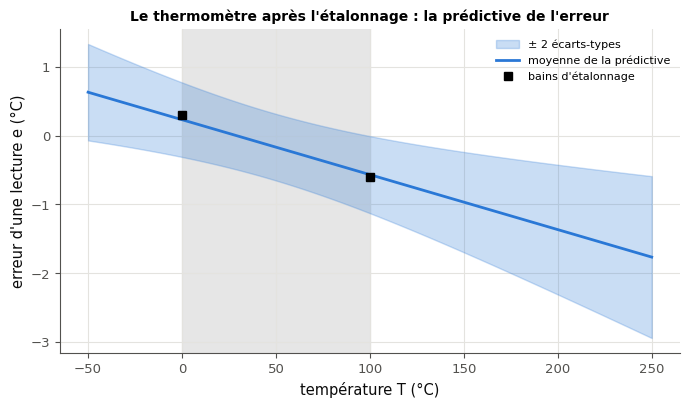

✅ Ex M25a.23 : la prédictive et sa bande sont dessinées.


In [32]:
linreg_posterior = mymath.gaussian.linreg_posterior


def draw_predictive_23(ax, ts, means, sds):
    """In ax: the predictive mean of the error against ts, its band mean ± 2 sds (ax.fill_between), and the two
    calibration points (0, 0.3) and (100, -0.6); labels and a legend. No other axes."""
    ax.fill_between(ts, means - 2 * sds, means + 2 * sds, color="C0", alpha=0.25, label="± 2 écarts-types")
    ax.plot(ts, means, color="C0", label="moyenne de la prédictive")
    ax.plot([0.0, 100.0], [0.3, -0.6], "ks", label="bains d'étalonnage")
    ax.axvspan(0.0, 100.0, color="0.9", zorder=0)
    ax.set_xlabel("température T (°C)")
    ax.set_ylabel("erreur d'une lecture e (°C)")
    ax.set_title("Le thermomètre après l'étalonnage : la prédictive de l'erreur", fontsize=10)
    ax.legend(fontsize=8)


posterior_23 = linreg_posterior(PHI_23, E_23, np.zeros(2), S0_23, NOISE_23)
m_N_23, S_N_23 = posterior_23
answer_M25a_23a = m_N_23.tolist()
m_first_23, S_first_23 = linreg_posterior(PHI_23[:1], E_23[:1], np.zeros(2), S0_23, NOISE_23)   # the ice bath
m_seq_23, S_seq_23 = linreg_posterior(PHI_23[1:], E_23[1:], m_first_23, S_first_23, NOISE_23)  # then the boiling water
answer_M25a_23b = bool(np.allclose(m_seq_23, m_N_23, rtol=0, atol=1e-12) and np.allclose(S_seq_23, S_N_23, rtol=0, atol=1e-12))
tau2_23 = 0.5
m_tau_23, _ = linreg_posterior(PHI_23, E_23, np.zeros(2), tau2_23 * np.eye(2), NOISE_23)
ridge_23 = np.linalg.solve(PHI_23.T @ PHI_23 + NOISE_23 / tau2_23 * np.eye(2), PHI_23.T @ E_23)
answer_M25a_23c = m_tau_23.tolist() + [bool(np.allclose(m_tau_23, ridge_23))]
answer_M25a_23d = float(-100 * S_N_23[0, 1] / S_N_23[1, 1])
features_23 = np.column_stack([np.ones_like(TS_23), TS_23 / 100])
pred_means_23 = features_23 @ m_N_23
pred_sds_23 = np.sqrt(np.einsum("ij,jk,ik->i", features_23, S_N_23, features_23) + NOISE_23)
print("a)", np.round(answer_M25a_23a, 6).tolist(), "; S_N =", np.round(S_N_23, 6).tolist(), " b)", answer_M25a_23b)
print("c)", [round(v, 6) for v in answer_M25a_23c[:2]], answer_M25a_23c[2], " d)", round(answer_M25a_23d, 3))
print("écart-type de la prédictive à −50, 0, 46,3, 100, 200 et 250 °C :",
      [round(float(np.interp(t, TS_23, pred_sds_23)), 3) for t in (-50, 0, answer_M25a_23d, 100, 200, 250)])

with checked("M25a.23"):
    results_23 = []
    report_23 = reporter(results_23)
    if not filled(pred_means_23, pred_sds_23):
        print("⏳ Ex M25a.23 : la figure attend tes tableaux pred_means_23 et pred_sds_23.")
        raise StopCheck
    S_c23 = np.linalg.inv(np.linalg.inv(S0_23) + PHI_23.T @ PHI_23 / NOISE_23)
    m_c23 = S_c23 @ (PHI_23.T @ E_23 / NOISE_23)
    features_c23 = np.column_stack([np.ones_like(TS_23), TS_23 / 100])
    means_c23 = features_c23 @ m_c23
    sds_c23 = np.sqrt(np.einsum("ij,jk,ik->i", features_c23, S_c23, features_c23) + NOISE_23)
    results_23.append(same("M25a.23", "pred_means_23, les moyennes de la prédictive", pred_means_23, means_c23))
    results_23.append(same("M25a.23", "pred_sds_23, les écarts-types de la prédictive (bruit compris)", pred_sds_23,
                           sds_c23))
    if not all(results_23):
        raise StopCheck
    fig_23, ax_23 = plt.subplots(figsize=(8, 4.2))
    try:
        opened_23 = drawn(draw_predictive_23, ax_23, TS_23, means_c23, sds_c23)
        report_23(not opened_23, "draw_predictive_23 dessine dans l'axe reçu",
                  "draw_predictive_23 doit dessiner dans l'axe reçu, sans ouvrir de figure")
        report_23(through(ax_23, TS_23, means_c23), "la moyenne de la prédictive est tracée contre la température",
                  "il manque la courbe des moyennes contre TS_23 (une valeur par température)")
        band_23 = any(type(c).__name__ != "PathCollection" for c in ax_23.collections) or (
            through(ax_23, TS_23, means_c23 + 2 * sds_c23) and through(ax_23, TS_23, means_c23 - 2 * sds_c23))
        report_23(band_23, "la bande à deux écarts-types est tracée",
                  "il manque la bande moyenne ± 2 écarts-types (ax.fill_between, ou deux courbes)")
        report_23(has_points(ax_23, [(0.0, 0.3), (100.0, -0.6)]), "les deux points d'étalonnage sont placés",
                  "il manque les deux points d'étalonnage (0 ; 0,3) et (100 ; −0,6)")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_23)
        raise
    plt.show()
    verdict("M25a.23", all(results_23), "la prédictive et sa bande sont dessinées.", "")

In [33]:
phi_23r, e_23r = np.array([[1.0, 0.0], [1.0, 1.0]]), np.array([0.3, -0.6])
s0_23r, s2_23r = np.diag([0.25, 1.0]), 0.04


def posterior_23r(s0, s2):
    """The law of θ given e in the joint Gaussian (θ, e) (fiche §5, the conditional law), not the precision form."""
    gain = s0 @ phi_23r.T @ np.linalg.inv(phi_23r @ s0 @ phi_23r.T + s2 * np.eye(2))
    return gain @ e_23r, s0 - gain @ phi_23r @ s0


m_23r, S_23r = posterior_23r(s0_23r, s2_23r)
wbm.record("M25a.23a", m_23r.tolist(), decimals=4,
           mistakes={"l'a priori tire aussi les poids vers sa moyenne : ce ne sont pas les moindres carrés":
                         np.linalg.solve(phi_23r, e_23r).tolist(),
                     "noise_var est une variance σ², pas un écart-type": posterior_23r(s0_23r, math.sqrt(s2_23r))[0].tolist()})
wbm.record("M25a.23b", True,
           mistakes={"les précisions s'additionnent dans n'importe quel ordre : compare m_N et S_N à 1e-12 près": False})
ridge_23r = np.linalg.solve(phi_23r.T @ phi_23r + s2_23r / 0.5 * np.eye(2), phi_23r.T @ e_23r)
wbm.record("M25a.23c", ridge_23r.tolist() + [True], decimals=4,
           mistakes={"avec m₀ = 0 et S₀ = τ²I, la moyenne a posteriori est la solution ridge de pénalité σ²/τ²":
                         ridge_23r.tolist() + [False],
                     "c) change l'a priori : S₀ = 0,5 I": m_23r.tolist() + [True]})
wbm.record("M25a.23d", float(-100 * S_23r[0, 1] / S_23r[1, 1]), decimals=1,
           mistakes={"vérifie le signe de la formule": float(100 * S_23r[0, 1] / S_23r[1, 1]),
                     "(S_N)₂₂ est le coefficient S_N[1, 1], en bas à droite": float(-100 * S_23r[0, 1] / S_23r[0, 0])})

WBM_ANSWER {"decimals": 4, "element_coarse": [["9badb1ab6bf26bd6efb1c00794a9e93c62a227cb25fc00fe7d3ebcf11023b71d"], ["633bb53a1027c1e643a26fb51e386b7cf772721e661edb09848e51072f1ce7b6"]], "element_coarse_any": [["645bf4a54dc283ae5597fb1d33e6b5834d0666a784e6e2ef5af260de38a1d6c1", "0d28b226a7fd67701ffca07c558043d8700c7d7e152a0794cbc99c1e1de7f5d7"], ["ca68828f20a745e5b0cd3224a4a25c35a373e8158047cd4943af949722115ec4", "5ed3b2db2b44e96de4723954aaec3b5760f10bf78dd9588d79a8d687cc925542", "3148b137aa141a45fe0a00a56caa82a2355059c9cd9913b2adc29baf72e73cd3"]], "element_hashes": ["793ed02952b5032be2c7a70ff5362b5f9cc19cbeb2b0979b406df6806527fbdb", "b6466b0ab4f621ef0ec89d88f9e48fe7c0ba7914078d9b0894ba29b1cfe12932"], "hash": "e3496573c9267b86b3ce8c8326d693fdd7d540432afd3b1b82f9e84a23a7f2e6", "id": "M25a.23a", "kind": "array", "mistakes": {"b272d11026db8ecbff7f112f6f8b51bd249ad377872c0f94d73f303f166548d3": "l'a priori tire aussi les poids vers sa moyenne : ce ne sont pas les moindres carrés", "ba664310

💡 La précision a posteriori $\mathbf{S}_0^{-1} + \sigma^{-2}\boldsymbol{\Phi}^\top\boldsymbol{\Phi}$, puis deux `np.linalg.solve`. a) $\mathbf{m}_N \approx (0{,}2311 ;\ -0{,}7991)$, $\mathbf{S}_N \approx \begin{pmatrix} 0{,}0334 & -0{,}0321 \\ -0{,}0321 & 0{,}0693 \end{pmatrix}$, comme M25a.6 d) et e). b) Vrai. c) $(0{,}2214 ;\ -0{,}7606)$ et vrai : la solution ridge de pénalité $\frac{0{,}04}{0{,}5} = 0{,}08$. d) $T \approx 46{,}3$ °C, où l'écart-type de la prédictive vaut $0{,}242$ °C ; $0{,}271$ et $0{,}280$ aux deux bains, $0{,}35$ à −50 °C, $0{,}47$ à 200 °C et $0{,}59$ à 250 °C : la bande s'ouvre en extrapolation.

### Ex M25a.24 — `scipy.stats.multivariate_normal`, `np.cov` et `scipy.integrate` : tes log-densités, le maximum de vraisemblance, et la KL de M25a.8 par une intégrale double 📦 ★ ⏱️ 25 min
**Objectif :** comparer ta librairie à SciPy, retrouver le maximum de vraisemblance avec `np.cov`, et calculer une KL entre deux gaussiennes de trois façons.  
**Prérequis :** fiche §1, §6 et §7 ; Ex M25a.20 et M25a.8 · **Parcours :** C, E

La cellule fournie donne les épaisseurs de route de M25a.2, la serre de M25a.1, et les deux réglages de M25a.8 ($p_0$ : `MU0_24`, `S0_24` ; $p_1$ : `MU1_24`, `S1_24`). Avec ta `sample_mvn` et ta `mvn_logpdf` (M25a.20 et M25a.21), et SciPy :
- a) tire 1 000 vecteurs des épaisseurs de route (`seed=5924`) : vrai ou faux, ta `mvn_logpdf` et `scipy.stats.multivariate_normal(mean, cov).logpdf` diffèrent de moins de $10^{-10}$ sur les 1 000 lignes ;
- b) 50 tirages de la serre (`sample_mvn(mean, cov, 50, seed=5924)`, le tableau $\mathbf{X}$) : l'estimation du maximum de vraisemblance $\hat{\boldsymbol{\Sigma}} = \frac1n(\mathbf{X} - \bar{\mathbf{x}})^\top(\mathbf{X} - \bar{\mathbf{x}})$, calculée à la main en NumPy (3 décimales dans ta copie), et vrai ou faux, elle est égale à `np.cov(X, rowvar=False, bias=True)` (une liste de 5 : les 4 coefficients de $\hat{\boldsymbol{\Sigma}}$ ligne par ligne, puis le booléen) ;
- c) le rapport entre `np.cov(X, rowvar=False)` (sans `bias`) et $\hat{\boldsymbol{\Sigma}}$, le même pour tous les coefficients (4 décimales dans ta copie) ;
- d) la KL $\mathrm{KL}(p_0 \,\|\, p_1)$ de M25a.8 par `scipy.integrate.dblquad`, en intégrant $p_0\ln\frac{p_0}{p_1}$ sur le carré $[\mu_{0,1} - 25,\ \mu_{0,1} + 25] \times [\mu_{0,2} - 25,\ \mu_{0,2} + 25]$ (4 décimales dans ta copie), à comparer à ta réponse d) de M25a.8 ;
- e) la même KL estimée par la moyenne, sur 200 000 tirages de $p_0$ (`sample_mvn(MU0_24, S0_24, 200000, seed=5924)`), de $\ln p_0 - \ln p_1$, puis l'erreur type de cette moyenne, l'écart-type des 200 000 termes divisé par $\sqrt{200\,000}$ (une liste de 2 nombres ; 4 décimales chacune dans ta copie).

Ce qu'il faut observer : la formule fermée, l'intégrale double et la moyenne sur des tirages donnent la même KL, cette dernière à son erreur type près ; et `np.cov` divise par $n - 1$ si on ne lui dit rien. Dans ta copie : `dblquad` appelle ta fonction `f(y, x)` avec $y$ en premier ; pourquoi le carré suffit-il ?

In [34]:
MU_ROAD_24 = np.array([40.0, 60.0, 30.0])                  # the road layers of M25a.2
COV_ROAD_24 = np.array([[4.0, 6.0, -2.0], [6.0, 13.0, -1.0], [-2.0, -1.0, 3.0]])
MU_GREEN_24 = np.array([22.0, 65.0])                       # the greenhouse of M25a.1
COV_GREEN_24 = np.array([[4.0, -6.0], [-6.0, 34.0]])
MU0_24, S0_24 = np.array([2.0, -1.0]), np.array([[4.0, 2.0], [2.0, 3.0]])     # the setting A of M25a.8: p0
MU1_24, S1_24 = np.array([3.0, -2.0]), np.array([[6.0, -1.0], [-1.0, 2.0]])   # the setting B: p1

In [35]:
sample_mvn, mvn_logpdf = mymath.gaussian.sample_mvn, mymath.gaussian.mvn_logpdf
road_24 = sample_mvn(MU_ROAD_24, COV_ROAD_24, 1000, seed=5924)
gap_24 = float(np.max(np.abs(mvn_logpdf(road_24, MU_ROAD_24, COV_ROAD_24)
                             - stats.multivariate_normal(MU_ROAD_24, COV_ROAD_24).logpdf(road_24))))
answer_M25a_24a = bool(gap_24 < 1e-10)
X_24 = sample_mvn(MU_GREEN_24, COV_GREEN_24, 50, seed=5924)
centred_24 = X_24 - X_24.mean(axis=0)
sigma_hat_24 = centred_24.T @ centred_24 / len(X_24)            # (1/n) Σ (x_i − x̄)(x_i − x̄)ᵀ
answer_M25a_24b = sigma_hat_24.ravel().tolist() + [bool(np.allclose(sigma_hat_24, np.cov(X_24, rowvar=False, bias=True)))]
answer_M25a_24c = float(np.cov(X_24, rowvar=False)[0, 0] / sigma_hat_24[0, 0])
P0_24, P1_24 = np.linalg.inv(S0_24), np.linalg.inv(S1_24)
const0_24 = -math.log(2 * math.pi) - 0.5 * math.log(np.linalg.det(S0_24))
const1_24 = -math.log(2 * math.pi) - 0.5 * math.log(np.linalg.det(S1_24))


def integrand_24(y, x):
    """p0 ln(p0/p1) at the point (x, y): dblquad gives y first."""
    d0, d1 = np.array([x, y]) - MU0_24, np.array([x, y]) - MU1_24
    log0, log1 = const0_24 - 0.5 * d0 @ P0_24 @ d0, const1_24 - 0.5 * d1 @ P1_24 @ d1
    return math.exp(log0) * (log0 - log1)


kl_24, error_24 = integrate.dblquad(integrand_24, MU0_24[0] - 25, MU0_24[0] + 25, MU0_24[1] - 25, MU0_24[1] + 25)
answer_M25a_24d = float(kl_24)
draws_24 = sample_mvn(MU0_24, S0_24, 200000, seed=5924)
terms_24 = mvn_logpdf(draws_24, MU0_24, S0_24) - mvn_logpdf(draws_24, MU1_24, S1_24)
answer_M25a_24e = [float(terms_24.mean()), float(terms_24.std() / math.sqrt(len(terms_24)))]
print("a)", answer_M25a_24a, f"(écart maximal {gap_24:.1e})", " b)", np.round(answer_M25a_24b[:4], 4).tolist(),
      answer_M25a_24b[4], " c)", round(answer_M25a_24c, 6), "= 50/49 ≈", round(50 / 49, 6))
print("d)", round(answer_M25a_24d, 6), f"(erreur estimée {error_24:.0e})", " e)", np.round(answer_M25a_24e, 5).tolist())

a) True (écart maximal 1.1e-14)  b) [3.4958, -5.8591, -5.8591, 32.0558] True  c) 1.020408 = 50/49 ≈ 1.020408
d) 0.795591 (erreur estimée 1e-08)  e) [0.79638, 0.00296]


In [36]:
L_road_24r = np.linalg.cholesky([[4.0, 6.0, -2.0], [6.0, 13.0, -1.0], [-2.0, -1.0, 3.0]])
wbm.record("M25a.24a", True,
           mistakes={"les deux calculs sont justes : compare l'écart maximal, np.max(np.abs(...)), à 1e-10": False})
L_green_24r = np.linalg.cholesky([[4.0, -6.0], [-6.0, 34.0]])
X_24r = np.array([22.0, 65.0]) + np.random.default_rng(5924).standard_normal((50, 2)) @ L_green_24r.T
mle_24r = np.cov(X_24r, rowvar=False, bias=True)
unbiased_24r = np.cov(X_24r, rowvar=False)
wbm.record("M25a.24b", mle_24r.ravel().tolist() + [True], decimals=3,
           mistakes={"le maximum de vraisemblance divise par n, comme np.cov avec bias=True":
                         unbiased_24r.ravel().tolist() + [False],
                     "Σ̂ du maximum de vraisemblance est exactement np.cov(X, rowvar=False, bias=True)":
                         mle_24r.ravel().tolist() + [False]})
wbm.record("M25a.24c", float(unbiased_24r[0, 0] / mle_24r[0, 0]), decimals=4,
           mistakes={"le rapport demandé a np.cov sans bias au numérateur": float(mle_24r[0, 0] / unbiased_24r[0, 0])})
mu0_24r, s0_24r = np.array([2.0, -1.0]), np.array([[4.0, 2.0], [2.0, 3.0]])
mu1_24r, s1_24r = np.array([3.0, -2.0]), np.array([[6.0, -1.0], [-1.0, 2.0]])


def kl_formula_24r(m0, c0, m1, c1):
    """The closed form of the fiche (§7)."""
    delta = m1 - m0
    return 0.5 * (np.trace(np.linalg.solve(c1, c0)) + delta @ np.linalg.solve(c1, delta) - len(m0)
                  + math.log(np.linalg.det(c1) / np.linalg.det(c0)))


wbm.record("M25a.24d", float(kl_formula_24r(mu0_24r, s0_24r, mu1_24r, s1_24r)), decimals=4,
           mistakes={"on intègre p₀ ln(p₀/p₁) : l'espérance se prend sous p₀, la première loi":
                         float(kl_formula_24r(mu1_24r, s1_24r, mu0_24r, s0_24r))})
draws_24r = mu0_24r + np.random.default_rng(5924).standard_normal((200000, 2)) @ np.linalg.cholesky(s0_24r).T
terms_24r = (stats.multivariate_normal(mu0_24r, s0_24r).logpdf(draws_24r)
             - stats.multivariate_normal(mu1_24r, s1_24r).logpdf(draws_24r))
mc_24r, sd_24r = float(terms_24r.mean()), float(terms_24r.std())
wbm.record("M25a.24e", [mc_24r, sd_24r / math.sqrt(200000)], decimals=4,
           mistakes={"l'erreur type de la moyenne divise l'écart-type des termes par √n": [mc_24r, sd_24r],
                     "l'erreur type divise par √n, pas par n": [mc_24r, sd_24r / 200000]})

WBM_ANSWER {"hash": "261901bb1886213a0cad2de19d9cccb159c101056ad362ce8304194bac9c4600", "id": "M25a.24a", "kind": "bool", "mistakes": {"e4a53d03cdd39c57bd6b6237cb3e0e142514b9dc7f67ba510cfb61aa399898cc": "les deux calculs sont justes : compare l'écart maximal, np.max(np.abs(...)), à 1e-10"}}
📝 Ex M25a.24a : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 3, "element_coarse": [["4d0c77a40c3ce5177150aef10938a3226e1c399619cc4e7518c7fe347e228c98"], ["461238352ed025682bc03e67564b33cde628b5b9fb36fd55c6ec7cc1b1fb3491"], ["8db843cb5f97d0d1eff263a19857fc3f1ed3ef6adc3c8abaf77ff398f9be5588"], ["027e1448f26f83a45376789c9317dc801c21b7cf42597255456dfccbf528d58d"], ["81f91e15322b5c7fce0dd4a7691956a4187acab969db1a9f2c1fb53668b8a92c"]], "element_coarse_any": [["647cb1697e526b4de6f1fc7db2e6476712ef4cfb2dbd3f7fd5d8f31c9bf5e9e1", "4891c6dab00f6b8d190725043f3018ceecaa48dbcb662ed428ec642b907d29fd"], ["c2652c4aaf2bea8f3d344bb67d219155792f61da8007e559bdc560448bb245cf", "877458b12f3314c7acea3b0d5b0938db18ca

💡 a) Vrai : un écart maximal de l'ordre de $10^{-14}$. b) $\hat{\boldsymbol{\Sigma}} \approx \begin{pmatrix} 3{,}496 & -5{,}859 \\ -5{,}859 & 32{,}056 \end{pmatrix}$, et vrai. c) $\frac{50}{49} \approx 1{,}0204$. d) $0{,}7956$, la valeur de la formule (M25a.8 d)) : l'intégrande est négligeable hors du carré. e) $0{,}7964$, d'erreur type $0{,}0030$ : la formule est à moins d'une erreur type.

## Partie B · Prédire, mesurer, dessiner

Fiche §3 et §4. La masse d'un ellipsoïde quand la dimension grandit, prédite puis mesurée ; une loi conditionnelle approchée par simulation ; les ellipses, une tranche et une projection, dessinées.

### Ex M25a.25 — Prédire la part des tirages dans l'ellipsoïde de Mahalanobis de même niveau quand la dimension passe de 2 à 10, puis mesurer 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir, puis mesurer, la masse d'un ellipsoïde de Mahalanobis de niveau fixé quand la dimension augmente.  
**Prérequis :** fiche §3 ; Ex M25a.3 et M25a.21 · **Parcours :** C, E

On garde le niveau de l'ellipse à 90 % du plan, $c^2 = 2\ln 10$ (`LEVEL_25`), et l'on regarde, en dimension $d$, la part des tirages de $\mathcal{N}(\mathbf{0}, \boldsymbol{\Sigma}_d)$ tels que $\Delta^2 \le c^2$, avec $(\boldsymbol{\Sigma}_d)_{ij} = 0{,}6^{\lvert i - j\rvert}$ (`ar_cov_25(d)`). **Avant d'exécuter quoi que ce soit**, prédis :
- a) en dimension 10, cette part est : (A) encore de l'ordre de 90 % ; (B) nettement plus petite ; (C) nettement plus grande (une lettre) ;
- b) la première dimension où elle passe sous 50 % : (A) 3 ; (B) entre 5 et 7 ; (C) au-delà de 10 (une lettre) ;
- c) vrai ou faux : pour une dimension donnée, cette part dépend de la matrice $\boldsymbol{\Sigma}_d$ choisie.

Puis, une fois tes prédictions écrites et vérifiées, mesure, pour $d = 2, \ldots, 10$, la part sur 100 000 tirages (`sample_mvn(np.zeros(d), ar_cov_25(d), 100000, seed=5925)`, $\Delta^2$ par `np.linalg.solve`), compare-la à `scipy.stats.chi2(d).cdf(LEVEL_25)`, et relève :
- d) la part mesurée en dimension 10 (3 décimales dans ta copie) ;
- e) la première dimension où la part mesurée passe sous 50 % (un entier).

La vérification de l'expérience ne s'exécute qu'une fois tes trois prédictions écrites : elle compare tes parts à celles des tirages attendus et affiche la loi du khi-deux à côté. Ce qu'il faut observer : $\Delta^2$ suit la loi du khi-deux à $d$ degrés quelle que soit $\boldsymbol{\Sigma}_d$ ; à niveau fixé, la masse de l'ellipsoïde ne dépend que de la dimension.

In [37]:
LEVEL_25 = 2 * np.log(10)                                 # c² of the 90 % ellipse of the plane
DIMS_25 = list(range(2, 11))                               # d = 2, ..., 10


def ar_cov_25(d):
    """The covariance (Σ_d)_ij = 0.6^|i − j| in dimension d."""
    index = np.arange(d)
    return 0.6 ** np.abs(index[:, None] - index[None, :])

In [38]:
level_25r = 2 * math.log(10)
chi_25r = {d: float(stats.chi2(d).cdf(level_25r)) for d in range(2, 11)}
first_chi_25r = next(d for d in range(2, 11) if chi_25r[d] < 0.5)
wbm.record("M25a.25a", "A" if abs(chi_25r[10] - 0.9) < 0.05 else ("B" if chi_25r[10] < 0.85 else "C"), prediction=True,
           mistakes={"en dimension d, Δ² est une somme de d carrés : sa moyenne vaut d et grandit avec la dimension": "A",
                     "à niveau fixé, une boule de Mahalanobis de rayon fixe contient de moins en moins quand la masse "
                     "s'éloigne du centre": "C"})
wbm.record("M25a.25b", "A" if first_chi_25r == 3 else ("B" if 5 <= first_chi_25r <= 7 else "C"), prediction=True,
           mistakes={"la part baisse progressivement : compare le niveau c² ≈ 4,6 à la moyenne d de Δ²": "A",
                     "la moyenne de Δ² vaut d : regarde quand d dépasse le niveau c² ≈ 4,6": "C"})
wbm.record("M25a.25c", False, prediction=True,
           mistakes={"Δ² = ‖L⁻¹(x − μ)‖² est la norme au carré d'un tirage de N(0, I_d), quelle que soit Σ_d": True})

WBM_ANSWER {"hash": "1bdd2a0e5585d1e6b161664ad2a19fbf759d175b9abb1b6807fa3c1672b6f6cc", "id": "M25a.25a", "kind": "str", "mistakes": {"8255929cd4335f4ccd20e69e191c764e680af9929c9a9d2529a67684fefa724b": "en dimension d, Δ² est une somme de d carrés : sa moyenne vaut d et grandit avec la dimension", "a768eabfd2b094c4e691d23ff6b9ad7925b294bdc7e9f821b0e1de5f548f9fa0": "à niveau fixé, une boule de Mahalanobis de rayon fixe contient de moins en moins quand la masse s'éloigne du centre"}, "prediction": true}
📝 Ex M25a.25a : réponse enregistrée (str).
WBM_ANSWER {"hash": "781753163f2e1eece67db3b81bbe9666c2d201afbd3db09cc5281cd4e141602d", "id": "M25a.25b", "kind": "str", "mistakes": {"4b899d7d18a6f9ae68e01fc78feaf05f0a522738edfd1d7bdb402aa1b1e60ce5": "la part baisse progressivement : compare le niveau c² ≈ 4,6 à la moyenne d de Δ²", "9a8a50e8aa943e719485dd8e1677af56ce80162d2bb93de82186e95c20a40dfb": "la moyenne de Δ² vaut d : regarde quand d dépasse le niveau c² ≈ 4,6"}, "prediction": true}
📝 E

**L'expérience.** Écris-la une fois tes trois prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

In [39]:
sample_mvn = mymath.gaussian.sample_mvn
shares_25 = []
for d_25 in DIMS_25:
    S_25 = ar_cov_25(d_25)
    X_25 = sample_mvn(np.zeros(d_25), S_25, 100000, seed=5925)
    m2_25 = np.sum(X_25 * np.linalg.solve(S_25, X_25.T).T, axis=1)      # Δ² of each row
    shares_25.append(float(np.mean(m2_25 <= LEVEL_25)))
answer_M25a_25d = shares_25[-1]
answer_M25a_25e = next(d for d, share in zip(DIMS_25, shares_25) if share < 0.5)
print("d)", round(answer_M25a_25d, 4), " e)", answer_M25a_25e)

with checked("M25a.25"):
    if not filled(shares_25):
        print("⏳ Ex M25a.25 : la vérification attend tes parts mesurées shares_25.")
        raise StopCheck
    want_c25 = []
    for d_c25 in DIMS_25:
        S_c25 = ar_cov_25(d_c25)
        X_c25 = np.random.default_rng(5925).standard_normal((100000, d_c25)) @ np.linalg.cholesky(S_c25).T
        m2_c25 = np.einsum("ij,ij->i", X_c25, np.linalg.solve(S_c25, X_c25.T).T)
        want_c25.append(float(np.mean(m2_c25 <= LEVEL_25)))
    if same("M25a.25", "shares_25, les parts mesurées pour d = 2, …, 10", shares_25, want_c25):
        print("   d    mesurée   khi-deux")
        for d_c25, share_c25 in zip(DIMS_25, want_c25):
            print(f"  {d_c25:2d}    {share_c25:.3f}     {stats.chi2(d_c25).cdf(LEVEL_25):.3f}".replace(".", ","))

d) 0.0843  e) 6


✅ Ex M25a.25 : shares_25, les parts mesurées pour d = 2, …, 10 : un tableau (9,), comme attendu.
   d    mesurée   khi-deux
   2    0,899     0,900
   3    0,795     0,797
   4    0,668     0,670
   5    0,532     0,534
   6    0,401     0,405
   7    0,291     0,292
   8    0,200     0,201
   9    0,132     0,133
  10    0,084     0,084


In [40]:
shares_25r, shares_c_25r = [], []
for d in range(2, 11):
    index = np.arange(d)
    S = 0.6 ** np.abs(index[:, None] - index[None, :])
    X = np.random.default_rng(5925).standard_normal((100000, d)) @ np.linalg.cholesky(S).T
    m2 = np.einsum("ij,ij->i", X, np.linalg.solve(S, X.T).T)
    shares_25r.append(float(np.mean(m2 <= level_25r)))
    shares_c_25r.append(float(np.mean(m2 <= math.sqrt(level_25r))))
wbm.record("M25a.25d", shares_25r[-1], decimals=3,
           mistakes={"Δ² se compare au niveau c², pas à c": shares_c_25r[-1]})
first_25r = 2 + next(i for i, share in enumerate(shares_25r) if share < 0.5)
wbm.record("M25a.25e", first_25r,
           mistakes={"les dimensions commencent à d = 2 : l'indice de ta liste n'est pas la dimension":
                         {first_25r - 2, first_25r - 1}})

WBM_ANSWER {"coarse_any": {"1": ["67e8447a60afce5a4e1fbc2efe8b1c0e31789d5866c840feebf6544a3c4c77a8"]}, "decimals": 3, "hash": "b88361beda82ce92f9934dde30c11042c1251584ad4d93ca5b1d266bd793cc9a", "hash_coarse": "ab64b50fa0caa868dba1aaa79cadf41ee7f626264a9a86f04125685bd82a9fe4", "id": "M25a.25d", "kind": "float", "magnitude": -2, "mistakes": {"3ede650355f1cda48303d884c14d7f2d4966c695b7dd479a8230d9e93592a24b": "Δ² se compare au niveau c², pas à c"}, "sign": 1}
📝 Ex M25a.25d : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"hash": "eb775633f6a4b5725a60454f30391c6c762e39024ea43c684353b036dee0d6cb", "id": "M25a.25e", "kind": "int", "magnitude": 0, "mistakes": {"2200f38fa41bb50927ab1c12cee0e1edb1385df2cc4333df0395bcac97c91b39": "les dimensions commencent à d = 2 : l'indice de ta liste n'est pas la dimension", "70d33275ad031d254f29677dfb09be66597703f8dd62db30a4d95c8ccc97bf36": "les dimensions commencent à d = 2 : l'indice de ta liste n'est pas la dimension"}, "sign": 1}
📝 Ex M25a.25e : r

**Après l'expérience**, dans ta copie : pourquoi la part ne dépend-elle pas de $\boldsymbol{\Sigma}_d$ (blanchis) ? Que vaut la moyenne de $\Delta^2$ en dimension $d$, et comment l'expliques-tu avec la couronne du §3 ?

💡 Prédictions attendues : a) (B) ; b) (B) ; c) faux. Mesures : la part passe de $0{,}899$ ($d = 2$) à $0{,}795$, $0{,}668$, $0{,}532$, $0{,}401$ ($d = 6$)… jusqu'à $0{,}084$ ($d = 10$), au millième près de la loi du khi-deux ; d) $0{,}084$ ; e) $d = 6$. En dimension $d$, $\mathbb{E}[\Delta^2] = d$ : la masse est sur une couronne de rayon proche de $\sqrt d$, et une boule de rayon fixe $\sqrt{2\ln 10} \approx 2{,}15$ en contient de moins en moins.

### Ex M25a.26 — Conditionner par simulation : garder les tirages dont une mesure tombe près d'une valeur, et comparer à la loi conditionnelle exacte 🔬 ★★ ⏱️ 25 min
**Objectif :** approcher une loi conditionnelle en gardant les tirages proches de la valeur lue, et voir le compromis entre biais et nombre de tirages gardés.  
**Prérequis :** fiche §4 ; Ex M25a.1, M25a.21 et M25a.22 · **Parcours :** C

Pour la serre de M25a.1 (`MU_GREEN_26`, `COV_GREEN_26`), on cherche la loi de l'humidité $H$ sachant que la température vaut $T = 24$ °C (`T_READ_26`).
- a) Calcule-la exactement avec ta `condition_gaussian` : la moyenne et la variance (une liste de 2 nombres).

Puis tire 200 000 relevés (`sample_mvn(MU_GREEN_26, COV_GREEN_26, 200000, seed=5926)`) et, pour chaque demi-largeur $h$ de `HS_26` (2, 1, 0,5, 0,2 et 0,05 °C), garde ceux où $\lvert T - 24\rvert < h$ : `table_26` a une ligne par $h$, dans cet ordre, avec leur nombre, et la moyenne et la variance empiriques (`np.var`) de leur humidité. Écris `draw_window_26(ax_mean, ax_var, hs, means, variances, exact_mean, exact_var)`, qui trace dans les deux axes reçus (sans en ouvrir d'autre) la moyenne et la variance empiriques contre $h$ (abscisse logarithmique), avec les valeurs exactes (des droites horizontales). Relève :
- b) le nombre de relevés gardés pour $h = 0{,}05$ (un entier) ;
- c) la moyenne empirique de l'humidité pour $h = 2$ (2 décimales dans ta copie) ;
- d) vrai ou faux : pour $h = 2$, la variance empirique dépasse la variance exacte de plus de 1.

La vérification compare ton tableau à celui des tirages attendus, puis appelle `draw_window_26` et regarde le dessin. Ce qu'il faut conclure : une fenêtre large garde beaucoup de relevés mais biaise la moyenne et gonfle la variance (elle mélange des températures différentes) ; une fenêtre étroite est presque sans biais mais garde peu de relevés (leur nombre est à peu près proportionnel à $h$) ; la loi conditionnelle exacte évite ce compromis.

In [41]:
MU_GREEN_26 = np.array([22.0, 65.0])                       # the greenhouse of M25a.1: (T, H)
COV_GREEN_26 = np.array([[4.0, -6.0], [-6.0, 34.0]])
T_READ_26 = 24.0                                           # the temperature read (°C)
HS_26 = [2.0, 1.0, 0.5, 0.2, 0.05]                         # the half widths of the window (°C)

a) [62.0, 25.0]  b) 2342  c) 62.8113  d) True
   h = 2     :  95511 relevés, moyenne 62,811, variance 27,295
   h = 1     :  48279 relevés, moyenne 62,222, variance 25,652
   h = 0,5   :  24089 relevés, moyenne 62,042, variance 25,057
   h = 0,2   :   9635 relevés, moyenne 62,075, variance 24,608
   h = 0,05  :   2342 relevés, moyenne 62,232, variance 25,203
✅ Ex M25a.26 : table_26, une ligne [nombre, moyenne, variance] par demi-largeur : un tableau (5, 3), comme attendu.


✅ draw_window_26 dessine dans les axes reçus
✅ les moyennes et les variances empiriques sont tracées contre h
✅ les abscisses sont logarithmiques
✅ les valeurs exactes sont tracées


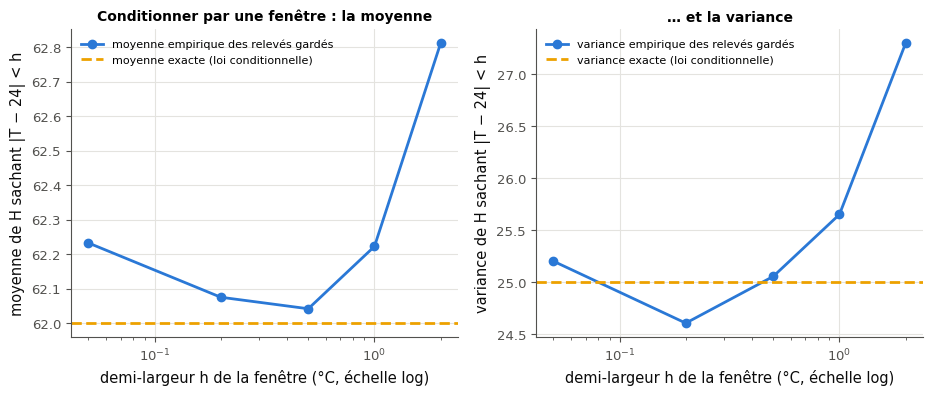

✅ Ex M25a.26 : ton tableau est juste, et dessiné avec les valeurs exactes.


In [42]:
condition_gaussian, sample_mvn = mymath.gaussian.condition_gaussian, mymath.gaussian.sample_mvn


def draw_window_26(ax_mean, ax_var, hs, means, variances, exact_mean, exact_var):
    """In ax_mean: the empirical means of H against hs (points joined), the x scale logarithmic, and the exact mean (a
    horizontal line); in ax_var: the same for the variances. Labels and a legend in each. No other axes."""
    for ax, values, exact, name in ((ax_mean, means, exact_mean, "moyenne"), (ax_var, variances, exact_var, "variance")):
        ax.plot(hs, values, "o-", color="C0", label=f"{name} empirique des relevés gardés")
        ax.axhline(exact, color="C3", linestyle="--", label=f"{name} exacte (loi conditionnelle)")
        ax.set_xscale("log")
        ax.set_xlabel("demi-largeur h de la fenêtre (°C, échelle log)")
        ax.set_ylabel(f"{name} de H sachant |T − 24| < h")
        ax.legend(fontsize=8)
    ax_mean.set_title("Conditionner par une fenêtre : la moyenne", fontsize=10)
    ax_var.set_title("… et la variance", fontsize=10)


mean_26, cov_26 = condition_gaussian(MU_GREEN_26, COV_GREEN_26, [0], [T_READ_26])
answer_M25a_26a = [float(mean_26[0]), float(cov_26[0, 0])]
draws_26 = sample_mvn(MU_GREEN_26, COV_GREEN_26, 200000, seed=5926)
rows_26 = []
for h_26 in HS_26:
    humidity_26 = draws_26[np.abs(draws_26[:, 0] - T_READ_26) < h_26, 1]
    rows_26.append([len(humidity_26), humidity_26.mean(), humidity_26.var()])
table_26 = np.array(rows_26)
answer_M25a_26b = int(table_26[-1, 0])
answer_M25a_26c = float(table_26[0, 1])
answer_M25a_26d = bool(table_26[0, 2] - answer_M25a_26a[1] > 1)
print("a)", answer_M25a_26a, " b)", answer_M25a_26b, " c)", round(answer_M25a_26c, 4), " d)", answer_M25a_26d)
for h_26, (count_26, m_26, v_26) in zip(HS_26, table_26):
    print(f"   h = {h_26:<5g} : {int(count_26):6d} relevés, moyenne {m_26:.3f}, variance {v_26:.3f}".replace(".", ","))

with checked("M25a.26"):
    results_26 = []
    report_26 = reporter(results_26)
    if not filled(table_26):
        print("⏳ Ex M25a.26 : la vérification attend ton tableau table_26.")
        raise StopCheck
    draws_c26 = MU_GREEN_26 + np.random.default_rng(5926).standard_normal((200000, 2)) @ np.linalg.cholesky(COV_GREEN_26).T
    want_c26 = []
    for h_c26 in HS_26:
        kept_c26 = draws_c26[np.abs(draws_c26[:, 0] - T_READ_26) < h_c26, 1]
        want_c26.append([len(kept_c26), kept_c26.mean(), kept_c26.var()])
    want_c26 = np.array(want_c26)
    results_26.append(same("M25a.26", "table_26, une ligne [nombre, moyenne, variance] par demi-largeur", table_26,
                           want_c26))
    if not results_26[-1]:
        raise StopCheck
    gain_c26 = COV_GREEN_26[1, 0] / COV_GREEN_26[0, 0]
    exact_c26 = (MU_GREEN_26[1] + gain_c26 * (T_READ_26 - MU_GREEN_26[0]), COV_GREEN_26[1, 1] - gain_c26 * COV_GREEN_26[0, 1])
    fig_26, (ax_mean_26, ax_var_26) = plt.subplots(1, 2, figsize=(11, 4))
    try:
        opened_26 = drawn(draw_window_26, ax_mean_26, ax_var_26, HS_26, want_c26[:, 1], want_c26[:, 2], *exact_c26)
        report_26(not opened_26, "draw_window_26 dessine dans les axes reçus",
                  "draw_window_26 doit dessiner dans les deux axes reçus, sans ouvrir de figure")
        report_26(through(ax_mean_26, HS_26, want_c26[:, 1]) and through(ax_var_26, HS_26, want_c26[:, 2]),
                  "les moyennes et les variances empiriques sont tracées contre h",
                  "il manque une courbe : les moyennes (à gauche), puis les variances (à droite), contre h")
        report_26(ax_mean_26.get_xscale() == "log" and ax_var_26.get_xscale() == "log", "les abscisses sont logarithmiques",
                  "mets les abscisses en échelle logarithmique (ax.set_xscale(\"log\"))")
        report_26(horizontal(ax_mean_26, exact_c26[0]) and horizontal(ax_var_26, exact_c26[1]),
                  "les valeurs exactes sont tracées", "il manque une droite horizontale : la moyenne exacte (à gauche) "
                  "ou la variance exacte (à droite), par ax.axhline")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_26)
        raise
    plt.show()
    verdict("M25a.26", all(results_26), "ton tableau est juste, et dessiné avec les valeurs exactes.", "")

In [43]:
mu_26r, cov_26r = np.array([22.0, 65.0]), np.array([[4.0, -6.0], [-6.0, 34.0]])
exact_26r = [float(mu_26r[1] + cov_26r[1, 0] / cov_26r[0, 0] * (24.0 - mu_26r[0])),
             float(cov_26r[1, 1] - cov_26r[1, 0] ** 2 / cov_26r[0, 0])]
wbm.record("M25a.26a", exact_26r, decimals=4,
           mistakes={"c'est la loi marginale de H : la lecture de T la change": [float(mu_26r[1]), float(cov_26r[1, 1])],
                     "sachant T, la variance de H diminue : retire Σ_HT Σ_TT⁻¹ Σ_TH": [exact_26r[0], float(cov_26r[1, 1])],
                     "on demande la variance, pas l'écart-type": [exact_26r[0], math.sqrt(exact_26r[1])]})
draws_26r = mu_26r + np.random.default_rng(5926).standard_normal((200000, 2)) @ np.linalg.cholesky(cov_26r).T


def window_26r(h):
    return draws_26r[np.abs(draws_26r[:, 0] - 24.0) < h]


wbm.record("M25a.26b", int(len(window_26r(0.05))),
           mistakes={"h est une demi-largeur : garde les relevés où |T − 24| < h": int(len(window_26r(0.025))),
                     "garde les relevés proches de la température lue, |T − 24| < h, pas de la moyenne de T":
                         int(np.sum(np.abs(draws_26r[:, 0] - 22.0) < 0.05))})
wbm.record("M25a.26c", float(window_26r(2.0)[:, 1].mean()), decimals=2,
           mistakes={"on demande la moyenne de l'humidité H des relevés gardés, pas celle de T":
                         float(window_26r(2.0)[:, 0].mean())})
wbm.record("M25a.26d", bool(window_26r(2.0)[:, 1].var() - exact_26r[1] > 1),
           mistakes={"une fenêtre large mélange des températures différentes : la dispersion de la moyenne "
                     "conditionnelle dans la fenêtre s'ajoute à la variance": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["36ed9b9df2b214af8f87cb9af801280c0623b352e1bec2856ba650cc2eb0b97a"], ["51d7bfc17dc2fe526c161e19102abfff8923f84218c266dc880bc3aeafbf3393"]], "element_coarse_any": [["3fa23c6bb74c075dd4d75dd242bf17f36b6ad338060078403f30b9b26c92a59d", "6eb2b6257476f1a82dfdf6a2721513dbe3e292c6c0b4a421bf08b8427c0b6acf", "d93d9c5151e675a6f691721bd82d3f93c939e14195d33d0ec5240b795738bb2f"], ["fe35ccf4c1ae5014ffe8e1aaa62557081c85f626f0a3c96fae588296b5aa124d", "41667ddb4cf04bc5e29ff18595ee584b3169c0cdd1d17f6ac5087217cd6fa7c9", "7480bb43d00a3fc462fe744d523bc3b3e02d836600fdf4bfc92094f7632af1a5"]], "element_hashes": ["42d0f0b6fa8c5a5350b9fb7c460362c48a0c3e4623c65d9c753f8c936e7660a0", "924daaf942279dbaf33527989503a492d78c800a96675344c0741eda65ada69b"], "hash": "0c43e011076ab21ca26092c7fc226827cdda9cc11f3087d4ada7fb4310c196f8", "id": "M25a.26a", "kind": "array", "mistakes": {"565668523c73e4b554ac0f5e3c106998f37bd1d4e4a6d1236f3a76f5010c8f23": "sachant T, la variance de H 

**Après la figure**, dans ta copie : pourquoi la moyenne empirique est-elle biaisée pour $h = 2$, et dans quel sens ? Combien de relevés faudrait-il tirer pour en garder autant avec $h = 0{,}05$ qu'avec $h = 2$ ?

💡 a) $\mathcal{N}(62, 25)$. b) $2\,342$ relevés pour $h = 0{,}05$, environ 1 % des 200 000. c) $62{,}81$ : un biais de $0{,}8$, parce que la fenêtre de 22 à 26 °C garde plus de températures sous 24 °C (la densité de $T$ décroît après 22 °C), donc des humidités plus hautes. d) Vrai : $27{,}3$ contre 25. Pour $h = 1$, $0{,}5$ et $0{,}2$ : $(48\,279 ;\ 62{,}22 ;\ 25{,}65)$, $(24\,089 ;\ 62{,}04 ;\ 25{,}06)$, $(9\,635 ;\ 62{,}08 ;\ 24{,}61)$ ; pour $h = 0{,}05$, $(62{,}23 ;\ 25{,}20)$, plus bruité : le nombre de relevés gardés est à peu près proportionnel à $h$.

### Ex M25a.27 — Les ellipses de niveau d'une gaussienne en dimension 2, une tranche (la loi conditionnelle) et une projection (la loi marginale), selon la corrélation 🎨 ★ ⏱️ 20 min
**Objectif :** voir, selon la corrélation, que la tranche d'une gaussienne du plan est une loi normale décalée et plus étroite, et sa projection une loi normale de même variance.  
**Prérequis :** fiche §3 et §4 ; Ex M25a.22 · **Parcours :** C, E

Écris `draw_gaussian_27(ax_joint, ax_cut, mean, cov, x1_value)`, qui dessine sur les **axes reçus** (sans ouvrir de figure) :
- dans `ax_joint`, les ellipses de $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$ qui contiennent les masses de `LEVELS_27` (50 % et 90 %), chacune obtenue en appliquant $\boldsymbol{\varepsilon} \mapsto \boldsymbol{\mu} + \mathbf{L}\boldsymbol{\varepsilon}$ au cercle de rayon $c$ (fiche §3, 💻 ; au moins 50 points, de $0$ à $2\pi$), la droite verticale $x_1 = $ `x1_value` (`ax.axvline`) et la droite des moyennes conditionnelles de $x_2$ sachant $x_1$, avec la même échelle sur les deux axes (`ax_joint.set_aspect("equal")`) ;
- dans `ax_cut`, la densité de la loi marginale de $x_2$ et celle de la loi conditionnelle de $x_2$ sachant $x_1 = $ `x1_value` (par ta `condition_gaussian`, `mymath.gaussian.condition_gaussian`), chacune sur au moins 50 points, avec une légende.

La cellule fournie donne $\boldsymbol{\mu} = (0, 1)$ (`MU_27`), les écarts-types 1 et 2 (`SDS_27`), les corrélations $\rho = 0$, $0{,}5$ et $0{,}9$ (`RHOS_27`), la covariance correspondante (`cov_27(rho)`) et $x_1 = 1{,}5$ (`X1_27`). La vérification appelle ta fonction pour les trois corrélations, trois colonnes de deux panneaux, puis pour un cas que tu ne vois pas, et regarde chaque dessin. Ce qu'il faut observer : la tranche est une loi normale décalée de $\rho\frac{\sigma_2}{\sigma_1}(x_1 - \mu_1)$ et plus étroite (variance multipliée par $1 - \rho^2$), la projection garde la variance $\sigma_2^2$ ; pour $\rho = 0$, les deux courbes se confondent ; et la droite des moyennes conditionnelles passe par les points où les ellipses ont une tangente verticale.

In [44]:
MU_27 = np.array([0.0, 1.0])
SDS_27 = (1.0, 2.0)                                        # the standard deviations of x1 and x2
RHOS_27 = (0.0, 0.5, 0.9)                                  # the three correlations
X1_27 = 1.5                                                # the slice x1 = 1.5
LEVELS_27 = (0.5, 0.9)                                     # the masses of the two ellipses


def cov_27(rho):
    """The covariance of standard deviations SDS_27 and correlation rho."""
    s1, s2 = SDS_27
    return np.array([[s1 ** 2, rho * s1 * s2], [rho * s1 * s2, s2 ** 2]])

ρ = 0 : x₂ sachant x₁ = 1,5 suit N(1 ; 4), la projection N(1 ; 4)
ρ = 0,5 : x₂ sachant x₁ = 1,5 suit N(2,5 ; 3), la projection N(1 ; 4)
ρ = 0,9 : x₂ sachant x₁ = 1,5 suit N(3,7 ; 0,76), la projection N(1 ; 4)
✅ ρ = 0 : draw_gaussian_27 dessine dans les axes reçus
✅ ρ = 0 : les deux ellipses, la verticale, la droite des moyennes conditionnelles et les deux densités sont là
✅ ρ = 0,5 : draw_gaussian_27 dessine dans les axes reçus
✅ ρ = 0,5 : les deux ellipses, la verticale, la droite des moyennes conditionnelles et les deux densités sont là
✅ ρ = 0,9 : draw_gaussian_27 dessine dans les axes reçus
✅ ρ = 0,9 : les deux ellipses, la verticale, la droite des moyennes conditionnelles et les deux densités sont là
✅ un cas que tu ne vois pas (une autre moyenne, une corrélation négative, une autre tranche) est dessiné juste aussi


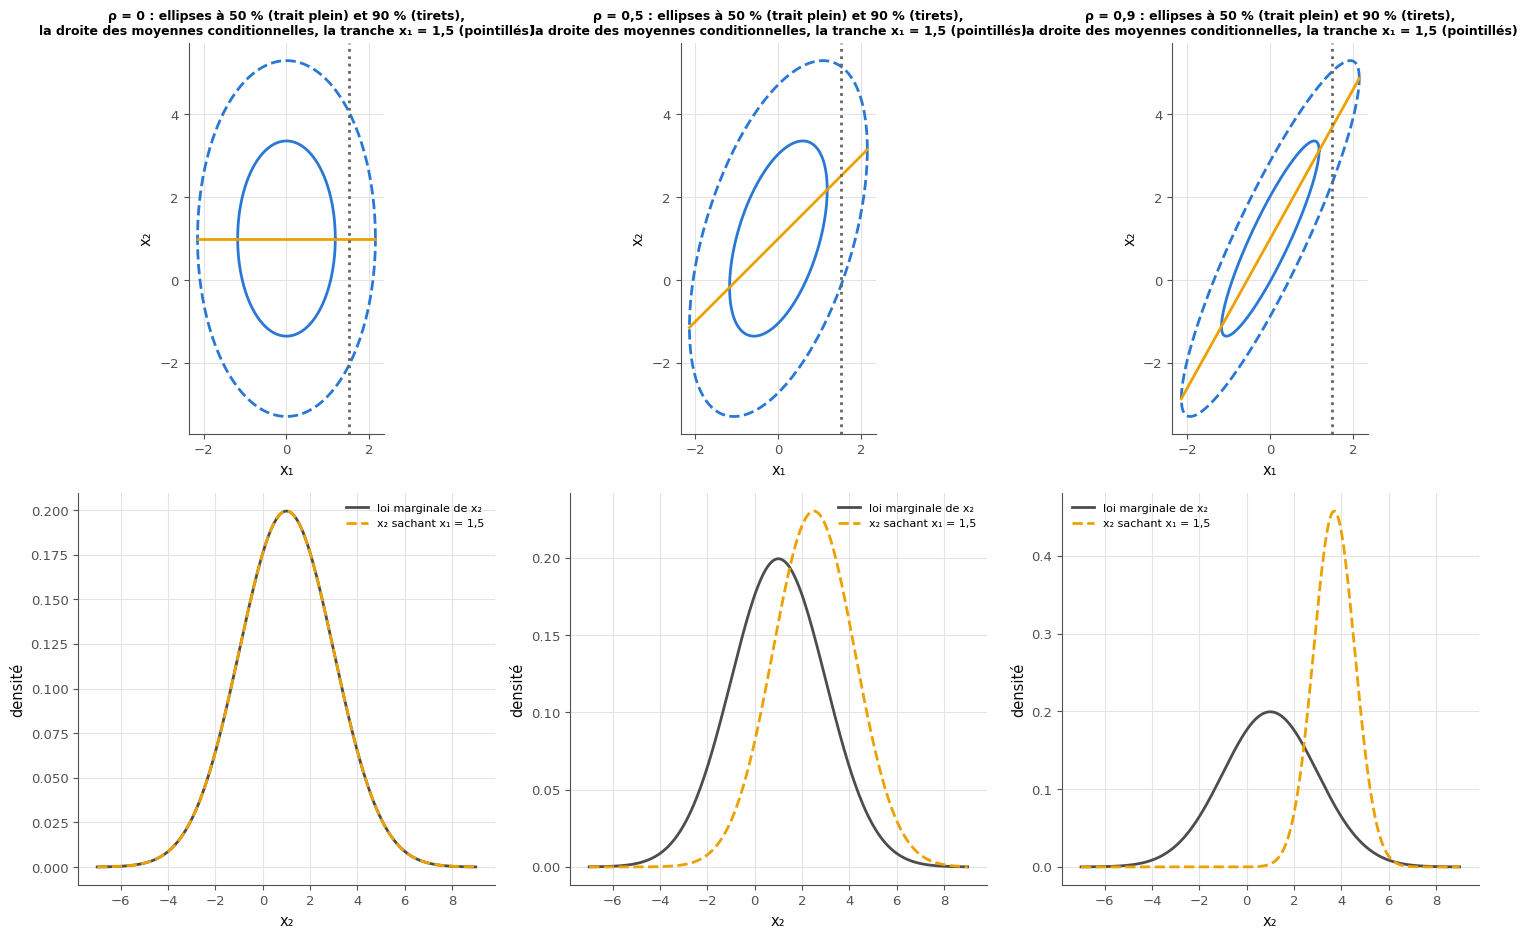

✅ Ex M25a.27 : les ellipses, les tranches et les projections sont dessinées.


In [45]:
condition_gaussian = mymath.gaussian.condition_gaussian


def draw_gaussian_27(ax_joint, ax_cut, mean, cov, x1_value):
    """In ax_joint: the ellipses of N(mean, cov) that contain the masses LEVELS_27, each the image μ + L(c cos t, c sin t)
    of the circle of radius c (at least 50 points, t from 0 to 2π), the vertical line x1 = x1_value (ax.axvline), the
    line of the conditional means of x2 given x1, equal scales (ax_joint.set_aspect("equal")); in ax_cut: the density
    of the marginal law of x2 and that of the conditional law of x2 given x1 = x1_value (your condition_gaussian), each
    on at least 50 points, with a legend. No other axes."""
    mean, cov = np.asarray(mean, dtype=float), np.asarray(cov, dtype=float)
    L = np.linalg.cholesky(cov)
    t = np.linspace(0.0, 2 * np.pi, 201)
    circle = np.vstack([np.cos(t), np.sin(t)])
    for level, style in zip(LEVELS_27, ("-", "--")):
        c = math.sqrt(-2 * math.log(1 - level))              # the level of the ellipse of mass `level`
        points = mean[:, None] + c * L @ circle               # the circle of radius c, through ε ↦ μ + L ε
        ax_joint.plot(points[0], points[1], style, color="C0", label=f"ellipse à {round(100 * level)} %")
    reach = math.sqrt(-2 * math.log(1 - max(LEVELS_27)) * cov[0, 0])
    x1s = np.array([mean[0] - reach, mean[0] + reach])
    ax_joint.plot(x1s, mean[1] + cov[0, 1] / cov[0, 0] * (x1s - mean[0]), color="C3",
                  label="moyennes conditionnelles de x₂")
    ax_joint.axvline(x1_value, color="0.4", linestyle=":", label=f"x₁ = {x1_value:g}".replace(".", ","))
    ax_joint.set_aspect("equal")
    ax_joint.set_xlabel("x₁")
    ax_joint.set_ylabel("x₂")
    rho = cov[0, 1] / math.sqrt(cov[0, 0] * cov[1, 1])
    ax_joint.set_title(f"ρ = {rho:.2g} : ellipses à 50 % (trait plein) et 90 % (tirets),\nla droite des moyennes conditionnelles, "
                       f"la tranche x₁ = {x1_value:g} (pointillés)".replace(".", ","), fontsize=9)
    cond_mean, cond_cov = condition_gaussian(mean, cov, [0], [x1_value])
    x2s = np.linspace(mean[1] - 4 * math.sqrt(cov[1, 1]), mean[1] + 4 * math.sqrt(cov[1, 1]), 301)
    ax_cut.plot(x2s, stats.norm(mean[1], math.sqrt(cov[1, 1])).pdf(x2s), color="0.3", label="loi marginale de x₂")
    ax_cut.plot(x2s, stats.norm(cond_mean[0], math.sqrt(cond_cov[0, 0])).pdf(x2s), "--", color="C3",
                label=f"x₂ sachant x₁ = {x1_value:g}".replace(".", ","))
    ax_cut.set_xlabel("x₂")
    ax_cut.set_ylabel("densité")
    ax_cut.legend(fontsize=8)


for rho_27 in RHOS_27:
    gain_27 = cov_27(rho_27)[1, 0] / cov_27(rho_27)[0, 0]
    print(f"ρ = {rho_27:g} : x₂ sachant x₁ = 1,5 suit N({MU_27[1] + gain_27 * (X1_27 - MU_27[0]):.4g} ; "
          f"{cov_27(rho_27)[1, 1] - gain_27 * cov_27(rho_27)[0, 1]:.4g}), la projection N({MU_27[1]:g} ; "
          f"{cov_27(rho_27)[1, 1]:g})".replace(".", ","))

def look_27(ax_joint, ax_cut, mean, cov, x1_value):
    """What is missing in a drawing of draw_gaussian_27: a list of French phrases, empty when all is there."""
    mean, cov = np.asarray(mean, dtype=float), np.asarray(cov, dtype=float)
    L, missing = np.linalg.cholesky(cov), []
    for level in LEVELS_27:
        c2, found = -2 * math.log(1 - level), False
        for line in ax_joint.lines:
            x, y = line_points(line)
            if x.size < 20:
                continue
            white = np.linalg.solve(L, np.vstack([x - mean[0], y - mean[1]])).T
            if np.allclose(np.sum(white ** 2, axis=1), c2, rtol=1e-6, atol=1e-9):
                angles = np.sort(np.arctan2(white[:, 1], white[:, 0]))
                found = found or np.diff(np.concatenate([angles, [angles[0] + 2 * np.pi]])).max() < 0.5
        if not found:
            missing.append(f"l'ellipse à {round(100 * level)} % (des points de Δ² = c², tout autour du centre)")
    if not any(line_points(line)[0].size >= 2 and np.allclose(line_points(line)[0], x1_value, rtol=0, atol=1e-9)
               for line in ax_joint.lines):
        missing.append(f"la droite verticale x₁ = {fr(x1_value, 2)} (ax.axvline)")
    slope = cov[0, 1] / cov[0, 0]
    if not any(np.ptp(line_points(line)[0]) > 0 and np.allclose(
            line_points(line)[1], mean[1] + slope * (line_points(line)[0] - mean[0]), rtol=0, atol=1e-9)
               for line in ax_joint.lines):
        missing.append("la droite des moyennes conditionnelles de x₂ sachant x₁")
    if ax_joint.get_aspect() not in ("equal", 1.0):
        missing.append("la même échelle sur les deux axes du panneau du haut (set_aspect(\"equal\"))")
    gain = cov[1, 0] / cov[0, 0]
    laws = {"la densité de la loi marginale de x₂": (mean[1], cov[1, 1]),
            "la densité de la loi conditionnelle de x₂ sachant x₁": (mean[1] + gain * (x1_value - mean[0]),
                                                                    cov[1, 1] - gain * cov[0, 1])}
    for name, (m, v) in laws.items():
        if not any(line_points(line)[0].size >= 20 and np.allclose(
                line_points(line)[1], stats.norm(m, math.sqrt(v)).pdf(line_points(line)[0]), rtol=1e-6, atol=1e-12)
                   for line in ax_cut.lines):
            missing.append(name + " (panneau du bas)")
    if ax_cut.get_legend() is None:
        missing.append("la légende du panneau du bas")
    return missing


with checked("M25a.27"):
    results_27 = []
    report_27 = reporter(results_27)
    fig_27, axes_27 = plt.subplots(2, 3, figsize=(15, 9.5))
    try:
        for column_27, rho_27 in enumerate(RHOS_27):
            name_27 = f"ρ = {rho_27:g}".replace(".", ",")
            opened_27 = drawn(draw_gaussian_27, axes_27[0, column_27], axes_27[1, column_27], MU_27, cov_27(rho_27), X1_27)
            report_27(not opened_27, f"{name_27} : draw_gaussian_27 dessine dans les axes reçus",
                      f"{name_27} : draw_gaussian_27 doit dessiner dans les deux axes reçus, sans ouvrir de figure")
            missing_27 = look_27(axes_27[0, column_27], axes_27[1, column_27], MU_27, cov_27(rho_27), X1_27)
            report_27(not missing_27, f"{name_27} : les deux ellipses, la verticale, la droite des moyennes "
                      "conditionnelles et les deux densités sont là", f"{name_27} : il manque " + " ; ".join(missing_27))
        rng_c27 = np.random.default_rng(5917)
        sds_c27, rho_c27 = rng_c27.uniform(0.6, 2.5, size=2), -0.7
        cov_c27 = np.array([[sds_c27[0] ** 2, rho_c27 * sds_c27[0] * sds_c27[1]],
                            [rho_c27 * sds_c27[0] * sds_c27[1], sds_c27[1] ** 2]])
        mean_c27 = rng_c27.uniform(-3, 3, size=2)
        fig_c27, (joint_c27, cut_c27) = plt.subplots(1, 2)
        try:
            opened_c27 = drawn(draw_gaussian_27, joint_c27, cut_c27, mean_c27.copy(), cov_c27.copy(),
                               float(mean_c27[0] - 0.8 * sds_c27[0]))
            missing_c27 = look_27(joint_c27, cut_c27, mean_c27, cov_c27, float(mean_c27[0] - 0.8 * sds_c27[0]))
        finally:
            plt.close(fig_c27)
        report_27(not opened_c27 and not missing_c27, "un cas que tu ne vois pas (une autre moyenne, une corrélation "
                  "négative, une autre tranche) est dessiné juste aussi", "un cas que tu ne vois pas (une autre moyenne, "
                  "une corrélation négative, une autre tranche) : il manque " + " ; ".join(missing_c27 or ["…"]))
    except StopCheck:
        fig_27.tight_layout()
        plt.show()
        raise
    except BaseException:
        plt.close(fig_27)
        raise
    fig_27.tight_layout()
    plt.show()
    verdict("M25a.27", all(results_27), "les ellipses, les tranches et les projections sont dessinées.", "")

**Après la figure**, dans ta copie : où la droite des moyennes conditionnelles coupe-t-elle les ellipses ? Que deviennent la tranche et la projection quand $\rho$ tend vers 1 ? Quelle part de la variance de $x_2$ la lecture de $x_1$ enlève-t-elle, pour chaque $\rho$ ?

💡 Pour $\rho = 0$, $0{,}5$ et $0{,}9$, la tranche $x_1 = 1{,}5$ donne les lois $\mathcal{N}(1, 4)$, $\mathcal{N}(2{,}5 ;\ 3)$ et $\mathcal{N}(3{,}7 ;\ 0{,}76)$ ; la projection reste $\mathcal{N}(1, 4)$. Les ellipses s'allongent le long de la diagonale quand $\rho$ grandit, et la droite des moyennes conditionnelles, $x_2 = 1 + 2\rho\,x_1$, passe par le centre et par les points de tangence verticale des ellipses.

## Partie C · Déboguer, tester

Fiche §1, §2 et §4. Trois erreurs classiques qui ne lèvent aucune erreur Python ; un test statistique pour un tirage. La vérification de M25a.29 s'appuie sur la référence (`ref_gauss`), pour ne pas dépendre de ton code.

In [46]:
ref_gauss = wbm.load_mymath("ref", alias="mymath_ref").gaussian   # the reference: the check of M25a.29

### Ex M25a.28 — Chasse à l'erreur : un tirage par E L au lieu de E Lᵀ, ln det Σ sans le facteur 2, et une covariance conditionnelle qui dépend de la valeur observée 🐛 ★ ⏱️ 20 min
**Objectif :** reconnaître trois erreurs classiques qui ne lèvent aucune erreur Python et passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §1, §2 et §4 ; Ex M25a.1, M25a.3 et M25a.4 · **Parcours :** C, E

Un collègue a écrit trois fonctions (cellule fournie) ; chacune a l'erreur que nomme le titre, aucune ne lève d'erreur Python, et chacune a passé la vérification qu'il a faite :
1. `draw_correlated(mean, cov, n, seed)` doit rendre $n$ tirages de $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$ rangés en lignes ; elle calcule `L = np.linalg.cholesky(cov)` et `E = np.random.default_rng(seed).standard_normal((n, d))`, puis rend `mean + E @ L`. Il l'a vérifiée sur la loi de moyenne nulle et de covariance $\operatorname{diag}(4, 9)$ : la covariance empirique de 50 000 tirages est bien proche de $\boldsymbol{\Sigma}$. Il l'applique au vent de M25a.3 (`MU_WIND_28`, `COV_WIND_28`).
2. `log_density(x, mean, cov)` doit rendre la log-densité de $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$ en un point ; elle calcule $\mathbf{L}$, résout $\mathbf{L}\mathbf{y} = \mathbf{x} - \boldsymbol{\mu}$, puis rend $-\frac12\big[d\ln(2\pi) + \sum_i\ln L_{ii} + \lVert\mathbf{y}\rVert^2\big]$. Il l'a vérifiée en trois points d'une loi de dimension 2 : `log_density(x, mean, cov) - log_density(mean, mean, cov)` vaut bien $-\frac12\Delta^2(\mathbf{x})$. Il l'applique à la serre de M25a.1 (`MU_GREEN_28`, `COV_GREEN_28`, `XP_28`).
3. `conditional_law(mean, cov, idx, values)` doit rendre la moyenne et la covariance des coordonnées hors de `idx` sachant `x[idx] = values` ; pour « tenir compte de l'écart observé », elle remplace $\boldsymbol{\Sigma}_{bb}$ par la dispersion de $\mathbf{x}_b$ autour de la valeur lue, $\boldsymbol{\Sigma}_{bb} + (\mathbf{v} - \boldsymbol{\mu}_b)(\mathbf{v} - \boldsymbol{\mu}_b)^\top$ (avec $\mathbf{v}$ = `values`), dans la moyenne comme dans la covariance. Il l'a vérifiée sur le capteur en panne de M25a.4 (`MU_SENSOR_28`, `COV_SENSOR_28`), en supposant que les deux voisins lisaient leur moyenne. Il l'applique aux vraies lectures, 19,5 °C et 14 °C.

À faire : écris `draw_correlated_fixed`, `log_density_fixed` et `conditional_law_fixed`, avec les mêmes arguments (la troisième reçoit `idx` comme une liste, et ne modifie jamais les tableaux reçus), puis réponds :
- a) la covariance théorique des tirages que rend la version fausse de `draw_correlated` pour le vent (une matrice $2 \times 2$ ; 4 décimales dans ta copie) ;
- b) vrai ou faux : la covariance empirique (`bias=True`) de 50 000 tirages de la version corrigée (`seed=5928`) est à moins de 0,3 de $\boldsymbol{\Sigma}$, coefficient par coefficient ;
- c) la valeur que rend la version fausse de `log_density` en $\mathbf{x}_P$ (4 décimales dans ta copie) ;
- d) celle de la version corrigée (4 décimales dans ta copie) ;
- e) la moyenne et la variance conditionnelles que rend la version fausse de `conditional_law` (une liste de 2 nombres ; 4 décimales dans ta copie) ;
- f) celles de la version corrigée (une liste de 2 nombres ; 4 décimales dans ta copie).

Pour chacune des trois erreurs, dis aussi, dans ta copie, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie tes corrections sur des cas que tu ne vois pas : des lois de covariance pleine en dimension 1 à 5, des points quelconques, et des valeurs lues loin de la moyenne.

In [47]:
MU_WIND_28 = np.array([2.5, 1.0])                          # the wind of M25a.3 (m/s)
COV_WIND_28 = np.array([[14.0, 3.0], [3.0, 6.0]])
MU_GREEN_28 = np.array([22.0, 65.0])                       # the greenhouse of M25a.1
COV_GREEN_28 = np.array([[4.0, -6.0], [-6.0, 34.0]])
XP_28 = np.array([24.0, 68.0])
MU_SENSOR_28 = np.array([18.0, 17.0, 15.0])                # the sensors of M25a.4
COV_SENSOR_28 = np.array([[4.0, 3.0, 1.0], [3.0, 4.0, 2.0], [1.0, 2.0, 4.0]])


# The colleague's code
def draw_correlated(mean, cov, n, seed):
    """n draws of N(mean, cov), one per row."""
    mean, cov = np.asarray(mean, dtype=float), np.asarray(cov, dtype=float)
    L = np.linalg.cholesky(cov)
    E = np.random.default_rng(seed).standard_normal((n, len(mean)))
    return mean + E @ L


def log_density(x, mean, cov):
    """ln N(x | mean, cov) at one point x."""
    x, mean, cov = (np.asarray(v, dtype=float) for v in (x, mean, cov))
    L = np.linalg.cholesky(cov)
    y = np.linalg.solve(L, x - mean)
    return float(-0.5 * (len(x) * np.log(2 * np.pi) + np.sum(np.log(np.diag(L))) + y @ y))


def conditional_law(mean, cov, idx, values):
    """(mean, covariance) of the coordinates not in idx, given x[idx] = values."""
    mean, cov, values = (np.asarray(v, dtype=float) for v in (mean, cov, values))
    rest = [i for i in range(len(mean)) if i not in idx]
    gap = values - mean[idx]
    S_bb = cov[np.ix_(idx, idx)] + np.outer(gap, gap)          # "to take the observed gap into account"
    S_ab = cov[np.ix_(rest, idx)]
    gain = S_ab @ np.linalg.inv(S_bb)
    return mean[rest] + gain @ gap, cov[np.ix_(rest, rest)] - gain @ S_ab.T


# The colleague's checks: all pass
check_1_28 = draw_correlated(np.zeros(2), np.diag([4.0, 9.0]), 50000, 5911)
print("(1) N(0, diag(4, 9)), 50 000 tirages : covariance empirique",
      np.round(np.cov(check_1_28, rowvar=False, bias=True), 2).tolist(), "(attendu proche de [[4, 0], [0, 9]])")
mean_2_28, cov_2_28 = np.array([-1.0, 0.5]), np.array([[2.0, -0.8], [-0.8, 1.25]])
ok_2_28 = all(np.isclose(log_density(x, mean_2_28, cov_2_28) - log_density(mean_2_28, mean_2_28, cov_2_28),
                          -0.5 * (x - mean_2_28) @ np.linalg.solve(cov_2_28, x - mean_2_28))
              for x in (np.array([0.0, 0.0]), np.array([1.5, -1.0]), np.array([-2.0, 2.0])))
print("(2) en trois points, log_density(x) − log_density(μ) = −½ Δ²(x) :", ok_2_28, "(attendu True)")
mean_3_28, cov_3_28 = conditional_law(MU_SENSOR_28, COV_SENSOR_28, [0, 2], MU_SENSOR_28[[0, 2]])
print("(3) voisins lus à leur moyenne : moyenne conditionnelle égale à μ₂ :", bool(np.isclose(mean_3_28[0], 17.0)),
      "; variance conditionnelle plus petite que Σ₂₂ :", bool(cov_3_28[0, 0] < COV_SENSOR_28[1, 1]), "(attendu True, True)")

(1) N(0, diag(4, 9)), 50 000 tirages : covariance empirique [[3.96, -0.07], [-0.07, 9.09]] (attendu proche de [[4, 0], [0, 9]])
(2) en trois points, log_density(x) − log_density(μ) = −½ Δ²(x) : True (attendu True)
(3) voisins lus à leur moyenne : moyenne conditionnelle égale à μ₂ : True ; variance conditionnelle plus petite que Σ₂₂ : True (attendu True, True)


In [48]:
def draw_correlated_fixed(mean, cov, n, seed):
    """n draws of N(mean, cov), one per row: L = np.linalg.cholesky(cov), E = np.random.default_rng(seed).standard_normal((n, d))."""
    mean, cov = np.asarray(mean, dtype=float), np.asarray(cov, dtype=float)
    L = np.linalg.cholesky(cov)
    E = np.random.default_rng(seed).standard_normal((n, len(mean)))
    return mean + E @ L.T                                     # row i: (μ + L εᵢ)ᵀ = μᵀ + εᵢᵀ Lᵀ


def log_density_fixed(x, mean, cov):
    """ln N(x | mean, cov) at one point x: a float."""
    x, mean, cov = (np.asarray(v, dtype=float) for v in (x, mean, cov))
    L = np.linalg.cholesky(cov)
    y = np.linalg.solve(L, x - mean)
    return float(-0.5 * (len(x) * np.log(2 * np.pi) + 2 * np.sum(np.log(np.diag(L))) + y @ y))   # ln det Σ = 2 Σ ln L_ii


def conditional_law_fixed(mean, cov, idx, values):
    """(mean, covariance) of the coordinates not in idx (in increasing order), given x[idx] = values (idx a list)."""
    mean, cov, values = (np.asarray(v, dtype=float) for v in (mean, cov, values))
    idx = list(idx)
    rest = [i for i in range(len(mean)) if i not in idx]
    S_ab = cov[np.ix_(rest, idx)]
    gain = np.linalg.solve(cov[np.ix_(idx, idx)], S_ab.T).T  # Σ_ab Σ_bb⁻¹, with the block Σ_bb itself
    return mean[rest] + gain @ (values - mean[idx]), cov[np.ix_(rest, rest)] - gain @ S_ab.T


L_wind_28 = np.linalg.cholesky(COV_WIND_28)
answer_M25a_28a = (L_wind_28.T @ L_wind_28).tolist()        # the rows of E @ L have the covariance Lᵀ L
draws_28 = draw_correlated_fixed(MU_WIND_28, COV_WIND_28, 50000, 5928)
gap_28 = np.abs(np.cov(draws_28, rowvar=False, bias=True) - COV_WIND_28)
answer_M25a_28b = bool(np.all(gap_28 < 0.3))
answer_M25a_28c = log_density(XP_28, MU_GREEN_28, COV_GREEN_28)
answer_M25a_28d = log_density_fixed(XP_28, MU_GREEN_28, COV_GREEN_28)
wrong_mean_28, wrong_cov_28 = conditional_law(MU_SENSOR_28, COV_SENSOR_28, [0, 2], [19.5, 14.0])
answer_M25a_28e = [float(wrong_mean_28[0]), float(wrong_cov_28[0, 0])]
fixed_mean_28, fixed_cov_28 = conditional_law_fixed(MU_SENSOR_28, COV_SENSOR_28, [0, 2], [19.5, 14.0])
answer_M25a_28f = [float(fixed_mean_28[0]), float(fixed_cov_28[0, 0])]
print("a)", np.round(answer_M25a_28a, 4).tolist(), " b)", answer_M25a_28b, f"(écart maximal {gap_28.max():.3f})")
print("c)", round(answer_M25a_28c, 6), " d)", round(answer_M25a_28d, 6), "; écart ¼ ln det Σ =",
      round(0.25 * math.log(np.linalg.det(COV_GREEN_28)), 6))
print("e)", np.round(answer_M25a_28e, 6).tolist(), " f)", np.round(answer_M25a_28f, 6).tolist())

results_28, parts_28 = [], []


def report_28(ok, success, failure):
    results_28.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_28(part, name, function, *args):
    """function(*args); an error of the learner's code becomes one ❌ line that names the function (the check of this
    part stops there, the final verdict stays)."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", RuntimeWarning)
            return function(*args)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_28(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:200]}")
        parts_28.append(part)
        raise StopCheck from None


rng_c28 = np.random.default_rng(5918)


def random_law_28(d):
    """A random mean and a random full covariance (symmetric positive definite) in dimension d."""
    A = rng_c28.normal(size=(d, d))
    return rng_c28.normal(size=d) * 3, A @ A.T + 0.5 * np.eye(d)


with checked("M25a.28"):                                      # (1) draw_correlated_fixed
    wrong_28 = []
    for d_c28, n_c28, seed_c28 in ((2, 6, 5932), (3, 5, 5933), (4, 4, 5934)):
        mean_c28, cov_c28 = random_law_28(d_c28)
        got_c28 = call_28(1, "draw_correlated_fixed", draw_correlated_fixed, mean_c28.copy(), cov_c28.copy(), n_c28,
                          seed_c28)
        want_c28 = (mean_c28 + np.random.default_rng(seed_c28).standard_normal((n_c28, d_c28))
                    @ np.linalg.cholesky(cov_c28).T)
        if got_c28 is None or np.shape(got_c28) != want_c28.shape or not np.allclose(got_c28, want_c28, rtol=1e-9,
                                                                                    atol=1e-12):
            wrong_28.append(f"une loi de dimension {d_c28}, {n_c28} tirages : attendu un tableau {want_c28.shape} qui "
                            f"commence par {np.round(want_c28[0], 4).tolist()}, reçu {shown(got_c28)[:90]}")
    report_28(not wrong_28, "(1) draw_correlated_fixed : trois lois de covariance pleine, en dimension 2, 3 et 4 "
              "(comparées à μ + L εᵢ, même graine)", "(1) draw_correlated_fixed, " + " ; ".join(wrong_28[:2]))
    parts_28.append(1)

with checked("M25a.28"):                                      # (2) log_density_fixed
    wrong_28 = []
    for d_c28 in (1, 2, 3, 5):
        mean_c28, cov_c28 = random_law_28(d_c28)
        x_c28 = mean_c28 + rng_c28.normal(size=d_c28) * 2
        got_c28 = call_28(2, "log_density_fixed", log_density_fixed, x_c28.copy(), mean_c28.copy(), cov_c28.copy())
        want_c28 = float(stats.multivariate_normal(mean_c28, cov_c28).logpdf(x_c28))
        if got_c28 is None or np.ndim(got_c28) != 0 or not math.isclose(float(got_c28), want_c28, rel_tol=1e-9):
            wrong_28.append(f"une loi de dimension {d_c28} : attendu {want_c28:.6f}, reçu {shown(got_c28, 6)}"[:200])
    report_28(not wrong_28, "(2) log_density_fixed : des lois de dimension 1, 2, 3 et 5, en des points quelconques",
              "(2) log_density_fixed, " + " ; ".join(wrong_28[:2]))
    parts_28.append(2)

with checked("M25a.28"):                                      # (3) conditional_law_fixed
    wrong_28 = []
    for d_c28, idx_c28 in ((3, [1]), (4, [3, 0]), (5, [0, 2, 4])):
        mean_c28, cov_c28 = random_law_28(d_c28)
        values_c28 = mean_c28[idx_c28] + rng_c28.normal(size=len(idx_c28)) * 4      # far from the mean
        rest_c28 = [i for i in range(d_c28) if i not in idx_c28]
        precision_c28 = np.linalg.inv(cov_c28)
        cov_want_c28 = np.linalg.inv(precision_c28[np.ix_(rest_c28, rest_c28)])          # Σ_{a|b} = Λ_aa⁻¹
        mean_want_c28 = mean_c28[rest_c28] - cov_want_c28 @ precision_c28[np.ix_(rest_c28, idx_c28)] @ (
            values_c28 - mean_c28[idx_c28])
        got_c28 = call_28(3, "conditional_law_fixed", conditional_law_fixed, mean_c28.copy(), cov_c28.copy(),
                          list(idx_c28), values_c28.copy())
        if not isinstance(got_c28, (tuple, list)) or len(got_c28) != 2:
            wrong_28.append(f"attendu le couple (moyenne, covariance), reçu {shown(got_c28)[:90]}")
            break
        if (np.shape(got_c28[0]) != mean_want_c28.shape or np.shape(got_c28[1]) != cov_want_c28.shape
                or not np.allclose(got_c28[0], mean_want_c28, rtol=1e-9, atol=1e-12)
                or not np.allclose(got_c28[1], cov_want_c28, rtol=1e-9, atol=1e-12)):
            wrong_28.append(f"dimension {d_c28}, idx = {idx_c28}, des valeurs loin de la moyenne : attendu "
                            f"({np.round(mean_want_c28, 4).tolist()}, {np.round(cov_want_c28, 4).tolist()}), reçu "
                            f"{shown(tuple(got_c28))}"[:260])
    report_28(not wrong_28, "(3) conditional_law_fixed : des lois de dimension 3, 4 et 5, des valeurs lues loin de la "
              "moyenne", "(3) conditional_law_fixed, " + " ; ".join(wrong_28[:2]))
    parts_28.append(3)

if len(set(parts_28)) == 3:
    verdict("M25a.28", all(results_28), "les trois fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

a) [[14.6429, 1.8558], [1.8558, 5.3571]]  b) True (écart maximal 0.082)
c) -4.20917  d) -5.360462 ; écart ¼ ln det Σ = 1.151293
e) [17.322581, 1.548387]  f) [17.666667, 1.333333]
✅ (1) draw_correlated_fixed : trois lois de covariance pleine, en dimension 2, 3 et 4 (comparées à μ + L εᵢ, même graine)
✅ (2) log_density_fixed : des lois de dimension 1, 2, 3 et 5, en des points quelconques
✅ (3) conditional_law_fixed : des lois de dimension 3, 4 et 5, des valeurs lues loin de la moyenne
✅ Ex M25a.28 : les trois fonctions corrigées passent tous les cas.


In [49]:
cov_wind_28r = np.array([[14.0, 3.0], [3.0, 6.0]])
L_wind_28r = np.linalg.cholesky(cov_wind_28r)
wbm.record("M25a.28a", (L_wind_28r.T @ L_wind_28r).tolist(), decimals=4,
           mistakes={"la version fausse ne tire pas selon Σ : calcule la covariance des lignes de E @ L":
                         cov_wind_28r.tolist()})
draws_28r = np.array([2.5, 1.0]) + np.random.default_rng(5928).standard_normal((50000, 2)) @ L_wind_28r.T
wbm.record("M25a.28b", bool(np.all(np.abs(np.cov(draws_28r, rowvar=False, bias=True) - cov_wind_28r) < 0.3)),
           mistakes={"compare chaque coefficient de la covariance empirique de la version corrigée à celui de Σ": False})
green_28r = stats.multivariate_normal([22.0, 65.0], [[4.0, -6.0], [-6.0, 34.0]])
right_28r = float(green_28r.logpdf([24.0, 68.0]))
wrong_28r = right_28r + 0.25 * math.log(np.linalg.det([[4.0, -6.0], [-6.0, 34.0]]))   # half of ln det Σ missing
wbm.record("M25a.28c", wrong_28r, decimals=4,
           mistakes={"c) demande la valeur que rend la version FAUSSE": right_28r})
wbm.record("M25a.28d", right_28r, decimals=4,
           mistakes={"d) demande la valeur que rend ta version CORRIGÉE": wrong_28r})
mu_28r = np.array([18.0, 17.0, 15.0])
cov_28r = np.array([[4.0, 3.0, 1.0], [3.0, 4.0, 2.0], [1.0, 2.0, 4.0]])
gap_28r = np.array([19.5, 14.0]) - mu_28r[[0, 2]]


def law_28r(block):
    gain = cov_28r[1, [0, 2]] @ np.linalg.inv(block)
    return [float(mu_28r[1] + gain @ gap_28r), float(cov_28r[1, 1] - gain @ cov_28r[[0, 2], 1])]


right_law_28r = law_28r(cov_28r[np.ix_([0, 2], [0, 2])])
wrong_law_28r = law_28r(cov_28r[np.ix_([0, 2], [0, 2])] + np.outer(gap_28r, gap_28r))
wbm.record("M25a.28e", wrong_law_28r, decimals=4,
           mistakes={"e) demande ce que rend la version FAUSSE": right_law_28r})
wbm.record("M25a.28f", right_law_28r, decimals=4,
           mistakes={"f) demande ce que rend ta version CORRIGÉE": wrong_law_28r})

WBM_ANSWER {"decimals": 4, "element_coarse": [["748bca7ca290778f56825198858ab66635867088d13b557100a8248e1e3d6a8e"], ["a9057340048d5c78bb7e4408b5f1c229662fcfb9d556f27e709241b3507e925d"], ["b7bf7f4d52bbc48994fa96b2b9c628a7dfbf7860ed6dd99284f969bc83178e7e"], ["8532796728b6eb89b09541ff01e651f53dbcb0eec6d3c36c7e6c0344be26b8a3"]], "element_coarse_any": [["e391c581e456cfeb000f4c9eb1fe60890adccb23f4c31e0bfd0c534b9f6f21a1", "966802bbcc132001bafddfbbe83eeaa0ee154906e312e6ec6d469385fb30bb15", "34a6aa9784b7a2d4a25c1dcfa4400157037b831f7bad654394b1286e5c1a6caa"], ["2d81a7b4572d2402106bf3ee512d4685ca709863e9cf7bd9757d6d188954bc5d", "852342c89291b0945d1114a519773e2e0301b6f18ecb1c8bf6249c99ea8afbf4", "2da58afc7608bc866ede1e7e93a34a64781c87c6bc7325a6980dab664fdff798"], ["876999001be4dad0a140fe417e309d522a107ccf18ea94e72d1876cb3bdb03c9", "5a28b87891ad158b535da0ab305111d8eec2517c176518d3e230446ad6e82a30", "a23c168920549fd88cd2b617182effd35c97ea557f1fb43a2df86a191aab6c14"], ["5446e1d92cf96ec13ba06ec217678c

**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas (une covariance diagonale, des différences de log-densités, des voisins lus à leur moyenne), et quelle vérification l'aurait vue ? Pour (2), de combien la version fausse se trompe-t-elle, et pourquoi cet écart ne dépend-il pas du point ? Pour (3), dans quel sens la version fausse déplace-t-elle la moyenne, et que devient son erreur quand les lectures s'éloignent des moyennes ?

💡 (1) `E @ L` donne la covariance $\mathbf{L}^\top\mathbf{L}$ : il faut `mean + E @ L.T` ; pour une $\boldsymbol{\Sigma}$ diagonale, $\mathbf{L}$ est diagonale, donc symétrique, et les deux écritures coïncident. a) $\begin{pmatrix} 14{,}6429 & 1{,}8558 \\ 1{,}8558 & 5{,}3571 \end{pmatrix}$ au lieu de $\begin{pmatrix} 14 & 3 \\ 3 & 6 \end{pmatrix}$ ; b) vrai (écart maximal $0{,}082$). (2) Le facteur 2 de $\ln\det\boldsymbol{\Sigma} = 2\sum_i\ln L_{ii}$ manque ; la vérification comparait des différences de log-densités, où ce terme constant s'annule. c) $-4{,}2092$, trop grand de $\frac14\ln 100 \approx 1{,}1513$ ; d) $-5{,}3605$. (3) La covariance conditionnelle est le complément de Schur de $\boldsymbol{\Sigma}_{bb}$ lui-même ; le terme ajouté est nul quand les voisins lisent leur moyenne. e) $(17{,}3226 ;\ 1{,}5484)$ ; f) $(17{,}6667 ;\ 1{,}3333)$.

### Ex M25a.29 — Un test de propriété : la moyenne et la covariance empiriques de tes tirages, à une tolérance fixée par l'erreur type 🛠️ ★ ⏱️ 20 min
**Objectif :** écrire un test statistique dont la tolérance est fixée par l'erreur type et un risque d'échec annoncé, puis mesurer ce risque et la puissance du test.  
**Prérequis :** fiche §2 ; M02c ; Ex M25a.21 · **Parcours :** C

Écris `moment_test_29(sampler, mean, cov, n, seed, k)`, qui tire `X = sampler(mean, cov, n, seed)` et vérifie, par des `assert`, que chaque moyenne empirique est à moins de $k$ erreurs types de $\mu_j$, l'erreur type valant $\sqrt{\Sigma_{jj}/n}$, et que chaque coefficient de la covariance empirique (`bias=True`) est à moins de $k$ erreurs types de $\Sigma_{jk}$, l'erreur type valant $\sqrt{(\Sigma_{jj}\Sigma_{kk} + \Sigma_{jk}^2)/n}$ ; un échec lève `AssertionError`, avec un message qui dit **d'abord** ce qui était attendu (il commence par « expected »), **puis** le coefficient fautif. On prend la loi du vent de M25a.3 (`MU_WIND_29`, `COV_WIND_29`) et $n = 2\,000$ (`N_29`).
- a) Choisis $k$ pour que la probabilité qu'une fonction juste échoue soit au plus 1 % : en dimension 2, le test fait 5 comparaisons (2 moyennes et 3 coefficients de covariance) ; partage les 1 % entre elles (une borne de la réunion) et lis $k$ dans `scipy.stats.norm.ppf` (4 décimales dans ta copie).
- b) Lance ton test sur ta `sample_mvn` pour les 300 graines `SEEDS_29` (tirées par `np.random.default_rng(5929).integers(0, 2**31, size=300)`) : le nombre d'échecs, à comparer à ce que garantit a) (un entier).
- c) Sur ces 300 répétitions, mesure l'écart-type (`np.std`) du coefficient $(0, 1)$ de la covariance empirique, et compare-le à la formule de l'erreur type (une liste de 2 nombres ; 4 décimales chacun dans ta copie).
- d) La cellule fournie donne quatre versions fausses : `sampler_EL` (qui rend `mean + E @ L`), `sampler_sigma` (`mean + E @ cov`), `sampler_diag` (qui ignore les covariances : chaque coordonnée a la bonne variance, sans corrélation) et `sampler_inflated` (qui tire $\mathcal{N}(\boldsymbol{\mu}, 1{,}02\,\boldsymbol{\Sigma})$) ; lance ton test sur chacune avec la graine 5929 et $n = 2\,000$ : lesquelles attrape-t-il ? (une liste de 4 booléens, dans cet ordre : `True` quand ton test l'attrape).
- e) Combien de tirages faudrait-il pour qu'un écart de 2 % sur une variance dépasse $k$ erreurs types (l'erreur type d'une variance empirique vaut $\Sigma_{jj}\sqrt{2/n}$) ? Le plus petit entier $n$ (avec $k$ non arrondi). Vérifie que ton test attrape `sampler_inflated` avec $n = 200\,000$.

La vérification lance ton test sur la référence (`ref_gauss`), où il doit passer, sur les versions fausses, où il doit lever une `AssertionError` qui sort de ta fonction, sur un cas en dimension 3 que tu ne vois pas, puis sur **ta** librairie. Ce qu'il faut retenir : la tolérance d'un test statistique se choisit par l'erreur type et un risque d'échec annoncé, pas au hasard ; un tel test attrape les erreurs grossières à petit $n$, et une erreur fine seulement si $n$ est assez grand pour elle.

In [50]:
MU_WIND_29 = np.array([2.5, 1.0])                          # the wind of M25a.3 (m/s)
COV_WIND_29 = np.array([[14.0, 3.0], [3.0, 6.0]])
N_29 = 2000
SEEDS_29 = np.random.default_rng(5929).integers(0, 2**31, size=300)   # the 300 seeds of b) and c)


def sampler_EL(mean, cov, n, seed):
    """Wrong: mean + E @ L."""
    E = np.random.default_rng(seed).standard_normal((n, len(mean)))
    return np.asarray(mean, dtype=float) + E @ np.linalg.cholesky(cov)


def sampler_sigma(mean, cov, n, seed):
    """Wrong: mean + E @ cov."""
    E = np.random.default_rng(seed).standard_normal((n, len(mean)))
    return np.asarray(mean, dtype=float) + E @ np.asarray(cov, dtype=float)


def sampler_diag(mean, cov, n, seed):
    """Wrong: each coordinate has the right variance, without any correlation."""
    E = np.random.default_rng(seed).standard_normal((n, len(mean)))
    return np.asarray(mean, dtype=float) + E * np.sqrt(np.diag(cov))


def sampler_inflated(mean, cov, n, seed):
    """Wrong by a little: draws of N(mean, 1.02 cov)."""
    E = np.random.default_rng(seed).standard_normal((n, len(mean)))
    return np.asarray(mean, dtype=float) + E @ np.linalg.cholesky(1.02 * np.asarray(cov, dtype=float)).T

In [51]:
def moment_test_29(sampler, mean, cov, n, seed, k):
    """X = sampler(mean, cov, n, seed); assert that each empirical mean is within k standard errors sqrt(Σ_jj / n) of
    μ_j, and that each coefficient of the empirical covariance (bias=True) is within k standard errors
    sqrt((Σ_jj Σ_kk + Σ_jk²) / n) of Σ_jk. Each message says first what was expected ("expected ..."), then the
    faulty coefficient."""
    mean, cov = np.asarray(mean, dtype=float), np.asarray(cov, dtype=float)
    X = np.asarray(sampler(mean, cov, n, seed), dtype=float)
    means, covariance = X.mean(axis=0), np.cov(X, rowvar=False, bias=True)
    for j in range(len(mean)):
        se = math.sqrt(cov[j, j] / n)
        assert abs(means[j] - mean[j]) <= k * se, (
            f"expected the mean of coordinate {j} within {k:.3f} standard errors ({k * se:.4g}) of {mean[j]:.4g}, "
            f"got {means[j]:.4g}")
    for j in range(len(mean)):
        for l in range(j, len(mean)):
            se = math.sqrt((cov[j, j] * cov[l, l] + cov[j, l] ** 2) / n)
            assert abs(covariance[j, l] - cov[j, l]) <= k * se, (
                f"expected the covariance ({j}, {l}) within {k:.3f} standard errors ({k * se:.4g}) of {cov[j, l]:.4g}, "
                f"got {covariance[j, l]:.4g}")


def fails_29(sampler, n=N_29, seed=5929):
    """True when moment_test_29 raises an AssertionError."""
    try:
        moment_test_29(sampler, MU_WIND_29, COV_WIND_29, n, seed, answer_M25a_29a)
    except AssertionError:
        return True
    return False


sample_mvn = mymath.gaussian.sample_mvn
answer_M25a_29a = float(stats.norm.ppf(1 - 0.01 / (2 * 5)))     # 1 % shared by 5 comparisons, two-sided each
answer_M25a_29b = sum(fails_29(sample_mvn, seed=int(seed)) for seed in SEEDS_29)
covariances_29 = [np.cov(sample_mvn(MU_WIND_29, COV_WIND_29, N_29, seed=int(seed)), rowvar=False, bias=True)[0, 1]
                  for seed in SEEDS_29]
answer_M25a_29c = [float(np.std(covariances_29)),
                   math.sqrt((COV_WIND_29[0, 0] * COV_WIND_29[1, 1] + COV_WIND_29[0, 1] ** 2) / N_29)]
answer_M25a_29d = [fails_29(s) for s in (sampler_EL, sampler_sigma, sampler_diag, sampler_inflated)]
answer_M25a_29e = math.ceil((answer_M25a_29a * math.sqrt(2) / 0.02) ** 2)   # 0.02 Σ_jj > k Σ_jj √(2/n)
print("a)", round(answer_M25a_29a, 6), " b)", answer_M25a_29b, "échecs sur 300 (au plus 3 en moyenne)")
print("c)", np.round(answer_M25a_29c, 5).tolist(), " d)", answer_M25a_29d, " e)", answer_M25a_29e,
      "; sampler_inflated attrapé à n = 200 000 :", fails_29(sampler_inflated, n=200000))

with checked("M25a.29"):
    results_29 = []
    report_29 = reporter(results_29, stop=False)
    K_c29 = float(stats.norm.ppf(1 - 0.01 / (2 * 5)))

    def run_29(sampler, label, mean=MU_WIND_29, cov=COV_WIND_29, n=N_29, seed=5929):
        """None when moment_test_29 passes, else the message of its AssertionError (other errors: ❌, then stop)."""
        try:
            moment_test_29(sampler, mean, cov, n, seed, K_c29)
        except AssertionError as exc:
            return str(exc) or "(un assert sans message)"
        except (NotImplementedError, MymathMissingError):
            raise
        except Exception as exc:  # noqa: BLE001 - another error than an assert
            print(f"❌ Ex M25a.29 : moment_test_29({label}) lève {type(exc).__name__} au lieu d'un assert : "
                  f"{str(exc)[:200]}")
            raise StopCheck from None
        return None

    message_29 = run_29(ref_gauss.sample_mvn, "référence")
    report_29(message_29 is None, "sur la référence (le vent, n = 2 000, graine 5929, k de a)), ton test passe",
              f"ton test échoue sur la référence, qui est juste : {message_29!r:.200}")
    for sampler_c29, label_c29 in ((sampler_EL, "sampler_EL"), (sampler_sigma, "sampler_sigma"),
                                   (sampler_diag, "sampler_diag")):
        message_29 = run_29(sampler_c29, label_c29)
        if message_29 is None:
            report_29(False, "", f"ton test n'attrape pas {label_c29} : il doit lever une AssertionError, et la laisser "
                      "sortir de ta fonction")
            continue
        report_29(message_29.strip().lower().startswith(("expected", "attendu")),
                  f"ton test attrape {label_c29} : {message_29[:140]}",
                  f"ton test attrape {label_c29}, mais son message doit commencer par ce qui était attendu "
                  f"(« expected … »), reçu : {message_29[:140]!r}")
    message_29 = run_29(sampler_inflated, "sampler_inflated")
    report_29(message_29 is None, "sampler_inflated (1,02 Σ) passe à n = 2 000, comme annoncé",
              f"ton test attrape déjà sampler_inflated à n = 2 000, ce que k de a) ne permet pas : relis tes erreurs "
              f"types ({message_29!r:.140})")
    message_29 = run_29(sampler_inflated, "sampler_inflated, n = 200 000", n=200000)
    report_29(message_29 is not None, "à n = 200 000, ton test attrape sampler_inflated",
              "à n = 200 000, ton test laisse passer sampler_inflated : vérifie l'erreur type des variances")
    rng_c29 = np.random.default_rng(5919)
    A_c29 = rng_c29.normal(size=(3, 3))
    cov3_c29, mean3_c29 = A_c29 @ A_c29.T + np.eye(3), rng_c29.normal(size=3) * 2
    message_29 = run_29(ref_gauss.sample_mvn, "référence, dimension 3", mean3_c29, cov3_c29, 3000, 5931)
    report_29(message_29 is None, "en dimension 3 (un cas que tu ne vois pas), ton test passe sur la référence",
              f"en dimension 3 (un cas que tu ne vois pas), ton test échoue sur la référence : {message_29!r:.200}")

    def shifted_c29(mean, cov, n, seed):
        """Wrong: the right draws, the second mean moved by 8 standard errors."""
        return ref_gauss.sample_mvn(mean, cov, n, seed) + np.array([0.0, 8 * math.sqrt(cov[1, 1] / n), 0.0])

    def flipped_c29(mean, cov, n, seed):
        """Wrong: the covariances of the first coordinate with the others of the wrong sign."""
        D = np.diag([-1.0, 1.0, 1.0])
        return ref_gauss.sample_mvn(mean, D @ cov @ D, n, seed) * np.array([1.0, 1.0, 1.0])

    for sampler_c29, label_c29 in ((shifted_c29, "une moyenne décalée"), (flipped_c29, "des covariances de mauvais signe")):
        message_29 = run_29(sampler_c29, label_c29, mean3_c29, cov3_c29, 3000, 5931)
        report_29(message_29 is not None, f"en dimension 3, ton test attrape une version fausse que tu ne vois pas "
                  f"({label_c29})", f"en dimension 3, ton test laisse passer une version fausse que tu ne vois pas "
                  f"({label_c29}) : compare toutes les moyennes et tous les coefficients de la covariance")
    try:
        moment_test_29(mymath.gaussian.sample_mvn, MU_WIND_29, COV_WIND_29, N_29, 5929, K_c29)
        print("✅ ta librairie (sample_mvn) passe ton test")
    except (NotImplementedError, MymathMissingError):
        print("⏳ ta librairie : sample_mvn n'est pas encore écrite (M25a.21)")
    except AssertionError as exc:
        print(f"❌ ta librairie échoue à ton test ({str(exc)[:200]}) : si ton test passe sur la référence, l'erreur est "
              "dans ta sample_mvn (lance aussi ses tests, M25a.21)")
    verdict("M25a.29", all(results_29), "ton test passe sur la référence et attrape les versions fausses.",
            "relis les lignes ❌ ci-dessus.")

a) 3.090232  b) 4 échecs sur 300 (au plus 3 en moyenne)
c) [0.21158, 0.21564]  d) [True, True, True, False]  e) 47748 ; sampler_inflated attrapé à n = 200 000 : True
✅ sur la référence (le vent, n = 2 000, graine 5929, k de a)), ton test passe
✅ ton test attrape sampler_EL : expected the covariance (0, 1) within 3.090 standard errors (0.6664) of 3, got 1.885
✅ ton test attrape sampler_sigma : expected the covariance (0, 0) within 3.090 standard errors (1.368) of 14, got 206
✅ ton test attrape sampler_diag : expected the covariance (0, 1) within 3.090 standard errors (0.6664) of 3, got -0.04876
✅ sampler_inflated (1,02 Σ) passe à n = 2 000, comme annoncé


✅ à n = 200 000, ton test attrape sampler_inflated
✅ en dimension 3 (un cas que tu ne vois pas), ton test passe sur la référence
✅ en dimension 3, ton test attrape une version fausse que tu ne vois pas (une moyenne décalée)
✅ en dimension 3, ton test attrape une version fausse que tu ne vois pas (des covariances de mauvais signe)
✅ ta librairie (sample_mvn) passe ton test
✅ Ex M25a.29 : ton test passe sur la référence et attrape les versions fausses.


In [52]:
k_29r = float(stats.norm.ppf(1 - 0.001))
wbm.record("M25a.29a", k_29r, decimals=4,
           mistakes={"chaque comparaison peut échouer des deux côtés : la moitié de son risque de chaque côté":
                         float(stats.norm.ppf(1 - 0.002)),
                     "partage les 1 % entre les 5 comparaisons (une borne de la réunion)": float(stats.norm.ppf(1 - 0.005))})
mu_29r, cov_29r = np.array([2.5, 1.0]), np.array([[14.0, 3.0], [3.0, 6.0]])
L_29r = np.linalg.cholesky(cov_29r)


def passes_29r(X, k, cross=True):
    """The moment test of the statement on the draws X (cross=False: the term Σ_jk² of the standard error forgotten)."""
    n = len(X)
    se_mean = np.sqrt(np.diag(cov_29r) / n)
    se_cov = np.sqrt((np.outer(np.diag(cov_29r), np.diag(cov_29r)) + (cov_29r ** 2 if cross else 0)) / n)
    return bool(np.all(np.abs(X.mean(axis=0) - mu_29r) <= k * se_mean)
                and np.all(np.abs(np.cov(X, rowvar=False, bias=True) - cov_29r) <= k * se_cov))


draws_29r = [mu_29r + np.random.default_rng(int(seed)).standard_normal((2000, 2)) @ L_29r.T
             for seed in np.random.default_rng(5929).integers(0, 2**31, size=300)]
fails_29r = sum(not passes_29r(X, k_29r) for X in draws_29r)
variants_29r = {"la tolérance est k de a), avec le risque partagé entre les 5 comparaisons, des deux côtés":
                    sum(not passes_29r(X, float(stats.norm.ppf(1 - 0.005))) for X in draws_29r),
                "l'erreur type d'un coefficient de covariance contient aussi Σ_jk²":
                    sum(not passes_29r(X, k_29r, cross=False) for X in draws_29r)}
wbm.record("M25a.29b", fails_29r, mistakes={m: v for m, v in variants_29r.items() if v != fails_29r})
sd_29r = float(np.std([np.cov(X, rowvar=False, bias=True)[0, 1] for X in draws_29r]))
wbm.record("M25a.29c", [sd_29r, math.sqrt((14.0 * 6.0 + 3.0 ** 2) / 2000)], decimals=4,
           mistakes={"l'erreur type d'un coefficient de covariance contient aussi Σ_jk²":
                         [sd_29r, math.sqrt(14.0 * 6.0 / 2000)]})
E_29r = np.random.default_rng(5929).standard_normal((2000, 2))
wrong_29r = [mu_29r + E_29r @ L_29r, mu_29r + E_29r @ cov_29r, mu_29r + E_29r * np.sqrt(np.diag(cov_29r)),
             mu_29r + E_29r @ np.linalg.cholesky(1.02 * cov_29r).T]
caught_29r = [not passes_29r(X, k_29r) for X in wrong_29r]
wbm.record("M25a.29d", caught_29r,
           mistakes={"à n = 2 000, l'erreur type d'une variance est encore grande devant un écart de 2 %":
                         caught_29r[:3] + [True],
                     "sampler_diag a les bonnes variances, mais pas la covariance : ton test doit comparer le "
                     "coefficient (0, 1) aussi": caught_29r[:2] + [False, caught_29r[3]]})
n_29r = math.ceil((k_29r * math.sqrt(2) / 0.02) ** 2)
wbm.record("M25a.29e", n_29r,
           mistakes={"le plus petit entier n qui convient : arrondis vers le haut, avec k non arrondi": n_29r - 1})

WBM_ANSWER {"coarse_any": {"0": ["364f0aa33d799111753f7fed590ddc3567202cef2122ebbaa0903c996d37e886"]}, "coarser": {"1": ["45a58f907ea46e82ee099e0e894b9820541a83905f8b30c9df545313a90ff39b"], "2": ["8257bf8a3d2aca04cee388a54e6f3a742aa2d4b8e6a4ed01b52b438d8b67218a"]}, "decimals": 4, "hash": "a059df11d3937c64f093906b41605abd9604daf92eae2d43d91000450436b24f", "hash_coarse": "98c90a7f0aee9d83f09ab743daed9a683fd3f02cdbba46322b3ddfd6aa8c74af", "id": "M25a.29a", "kind": "float", "magnitude": 0, "mistakes": {"58a3ff6015b6a1583b0c7baab808a416775395fef28fb5624199ecdb6b343106": "chaque comparaison peut échouer des deux côtés : la moitié de son risque de chaque côté", "faa0aaa640afa1b8273b938044b5352bdd5af1e29ef74aebc6ca0292e1cbe568": "partage les 1 % entre les 5 comparaisons (une borne de la réunion)"}, "sign": 1}
📝 Ex M25a.29a : réponse enregistrée (float, 4 décimales).


WBM_ANSWER {"hash": "03d9add16c55dafe6b63725d3934fcbe9a2d14e54dbacb25c236df6b8dd7d560", "id": "M25a.29b", "kind": "int", "magnitude": 0, "mistakes": {"21360c3238de9462786004a59d359bd93abd984747ea9cd96815ecc12fbf778a": "l'erreur type d'un coefficient de covariance contient aussi Σ_jk²", "fe8b3f041834e94c482df27e3555cd382793d930dcd840f9fbd9d42e4a3a22c5": "la tolérance est k de a), avec le risque partagé entre les 5 comparaisons, des deux côtés"}, "sign": 1}
📝 Ex M25a.29b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 4, "element_coarse": [["421cf6c7b35aa1a5642a7a2a96ee84e4f4cbafb78b46498fe5173eafbed35d9f"], ["650a65ea25548949e1f329e6c8243bfe3154788b3ce3733b49e892f602fe0fef"]], "element_coarse_any": [["9b4f0f641892996669fc4798651529d913ae84f58c66c771411234fe11c390c2", "74af39b4fe9f64e275ff64a4e49ef371a9a3ddb6ae4e39a97f530e1aefc7c4b3"], ["28344a70a23fcd01e3068a70434a60c27644746abd9fead2ab01e2b7379a2bd3", "f8a6f2e4d40449c231a29b83ec9cb1fe71a0903ca2a4b556d15a2913286f7ba2"]], "element_h

**Après la vérification**, dans ta copie : le nombre d'échecs de b) est-il compatible avec la borne de a) (300 répétitions laissent une fluctuation d'environ $\pm 0{,}6$ %) ? Pourquoi `sampler_diag` passe-t-il les comparaisons des moyennes et des variances ? Que dit e) de la taille d'échantillon qu'il faut pour voir une erreur fine ?

💡 a) $k = \Phi^{-1}(1 - 0{,}001) \approx 3{,}0902$ (chaque comparaison a le risque $0{,}002$, partagé entre les deux côtés). b) 4 échecs sur 300 (1,3 %), compatible avec la borne : au plus 1 % en moyenne, avec une fluctuation d'environ $\pm 0{,}6$ % sur 300 répétitions. c) $0{,}2116$ mesuré, contre $\sqrt{(14 \times 6 + 9)/2\,000} \approx 0{,}2156$. d) $[\text{vrai}, \text{vrai}, \text{vrai}, \text{faux}]$ : `sampler_inflated` passe. e) $n = 47\,748$, le premier entier au-delà de $(k\sqrt2/0{,}02)^2 \approx 47\,747{,}7$ ; à $n = 200\,000$, le test attrape `sampler_inflated`.

## Partie D · Défi

Fiche §4 et §5. Des températures manquantes, reconstruites par une loi conditionnelle.

### Ex M25a.30 — Défi : reconstruire les températures manquantes le long d'une route par la loi conditionnelle d'une gaussienne, sous une erreur quadratique moyenne fixée 🏆 ★★★ ⏱️ 30 min
**Objectif :** reconstruire des valeurs manquantes par la loi conditionnelle d'une gaussienne, en construisant soi-même la covariance qui tient compte du bruit de mesure.  
**Prérequis :** fiche §4 et §5 ; Ex M25a.22 · **Parcours :** C

Une route est équipée d'un capteur de température par kilomètre, aux positions $s = 0, 1, \ldots, 30$ km (`S_30`). Les vraies températures (en °C) suivent une loi normale de moyenne $m(s) = 14 - 0{,}15\,s$ (la route monte ; `MEAN_30`) et de covariance $K_{ij} = 4\exp\big(-\frac{\lvert s_i - s_j\rvert}{6}\big)$, exponentielle de la distance (`K_30`). Douze capteurs sont en panne, aux positions 0, 1, 2, 13 à 17, et 27 à 30 (`MISS_30`) ; les 19 autres (`OBS_30`) mesurent la vraie température avec une erreur gaussienne indépendante d'écart-type 0,4 °C (`NOISE_SD_30`). La cellule fournie tire les vraies températures et les mesures avec `rng = np.random.default_rng(5930)` (les vraies températures $m + \mathbf{L}\,$`rng.standard_normal(31)`, $\mathbf{L}$ étant le facteur de Cholesky de $\mathbf{K}$, puis les 19 mesures, vraies températures plus $0{,}4\,$`rng.standard_normal(19)`) ; elle ne te donne que les mesures (`Y_OBS_30`), et la cellule de vérification garde les vraies températures des positions en panne.

Écris `reconstruct_30(s, y_obs, obs, miss)`, qui rend les moyennes et les écarts-types de la loi conditionnelle des vraies températures aux positions `miss` sachant les mesures aux positions `obs` (deux tableaux de 12 nombres). Le bruit ne touche que les positions mesurées : à toi de construire la covariance du vecteur formé des vraies températures aux positions en panne et des mesures aux autres positions (ta `condition_gaussian` peut faire le reste). Écris aussi `draw_road_30(ax, s, y_obs, obs, miss, means, sds)`, qui trace dans l'axe reçu les mesures, tes moyennes avec leur bande à deux écarts-types, la moyenne $m(s)$ et l'interpolation linéaire `np.interp(s, s[obs], y_obs)`.

**Critère de réussite :** la cellule de vérification calcule l'erreur quadratique moyenne de tes douze moyennes contre les vraies températures, et réussit si elle est au plus 1,0 °C. Puis relève, dans ta copie : a) ton erreur quadratique moyenne (affichée par la vérification) ; b) celle de l'interpolation linéaire des mesures, `np.interp(s[miss], s[obs], y_obs)` (affichée aussi) ; c) combien des douze vraies températures tombent à moins de deux de tes écarts-types de tes moyennes (affiché aussi).

Pour aller plus loin : la longueur 6 km de la covariance est supposée connue ; trace, en fonction de cette longueur, le logarithme de l'évidence des 19 mesures (ta `mvn_logpdf`), et regarde où il est maximal.

In [53]:
S_30 = np.arange(31.0)                                     # the positions of the sensors (km)
MEAN_30 = 14 - 0.15 * S_30                                 # the mean temperature m(s) (°C): the road climbs
K_30 = 4 * np.exp(-np.abs(S_30[:, None] - S_30[None, :]) / 6)    # K_ij = 4 exp(−|s_i − s_j| / 6)
MISS_30 = [0, 1, 2, 13, 14, 15, 16, 17, 27, 28, 29, 30]    # the twelve sensors down
OBS_30 = [i for i in range(31) if i not in MISS_30]        # the 19 sensors that measure
NOISE_SD_30 = 0.4                                          # the standard deviation of a measurement error (°C)


def measures_30():
    """The 19 measures at the positions OBS_30; the true temperatures stay inside this function."""
    rng = np.random.default_rng(5930)
    truth = MEAN_30 + np.linalg.cholesky(K_30) @ rng.standard_normal(31)
    return truth[OBS_30] + NOISE_SD_30 * rng.standard_normal(len(OBS_30))


Y_OBS_30 = measures_30()

moyennes : [13.64, 13.43, 13.2, 10.44, 9.94, 9.38, 8.76, 8.06, 6.72, 7.06, 7.33, 7.54]
écarts-types : [1.606, 1.421, 1.111, 1.075, 1.312, 1.38, 1.312, 1.075, 1.111, 1.421, 1.606, 1.727]
a) ton erreur quadratique moyenne : 0,831 °C ; b) celle de l'interpolation linéaire : 1,247 °C ; c) vraies températures à moins de deux de tes écarts-types : 12 sur 12
✅ Ex M25a.30 : critère atteint : erreur quadratique moyenne 0,831 °C ≤ 1,0 °C.


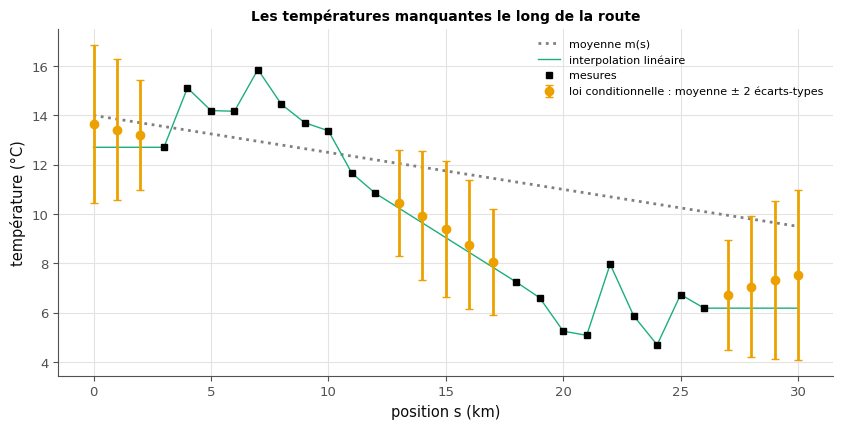

In [54]:
condition_gaussian, mvn_logpdf = mymath.gaussian.condition_gaussian, mymath.gaussian.mvn_logpdf


def road_law_30(s, length=6.0):
    """The mean and the covariance of the true temperatures at the positions s."""
    s = np.asarray(s, dtype=float)
    return 14 - 0.15 * s, 4 * np.exp(-np.abs(s[:, None] - s[None, :]) / length)


def reconstruct_30(s, y_obs, obs, miss):
    """The means and the standard deviations (two 1-D arrays of len(miss)) of the conditional law of the true
    temperatures at the positions miss, given the measures y_obs at the positions obs (model: mean 14 − 0.15 s,
    covariance 4 exp(−|s_i − s_j| / 6), a measurement noise of standard deviation 0.4 on the measured positions only)."""
    obs, miss = list(obs), list(miss)
    order = miss + obs                                         # the vector (truths at miss, measures at obs)
    mean, cov = road_law_30(np.asarray(s, dtype=float)[order])
    cov = cov + np.diag([0.0] * len(miss) + [0.4 ** 2] * len(obs))   # the noise on the measures only
    cond_mean, cond_cov = condition_gaussian(mean, cov, list(range(len(miss), len(order))), y_obs)
    return cond_mean, np.sqrt(np.diag(cond_cov))


def draw_road_30(ax, s, y_obs, obs, miss, means, sds):
    """In ax: the measures (points), your means at the positions miss with their band ± 2 sds, the mean m(s) and the
    linear interpolation np.interp(s, s[obs], y_obs); labels and a legend. No other axes."""
    s = np.asarray(s, dtype=float)
    ax.plot(s, 14 - 0.15 * s, color="0.5", linestyle=":", label="moyenne m(s)")
    ax.plot(s, np.interp(s, s[obs], y_obs), color="C2", linewidth=1, label="interpolation linéaire")
    ax.errorbar(s[miss], means, yerr=2 * sds, fmt="o", color="C3", capsize=3,
                label="loi conditionnelle : moyenne ± 2 écarts-types")
    ax.plot(s[obs], y_obs, "ks", markersize=4, label="mesures")
    ax.set_xlabel("position s (km)")
    ax.set_ylabel("température (°C)")
    ax.set_title("Les températures manquantes le long de la route", fontsize=10)
    ax.legend(fontsize=8)


means_30, sds_30 = reconstruct_30(S_30, Y_OBS_30, OBS_30, MISS_30)
print("moyennes :", np.round(means_30, 2).tolist())
print("écarts-types :", np.round(sds_30, 3).tolist())

reconstructed_30 = None
with checked("M25a.30"):
    result_c30 = reconstruct_30(S_30.copy(), Y_OBS_30.copy(), list(OBS_30), list(MISS_30))
    means_c30, sds_c30 = pair("M25a.30", "reconstruct_30", result_c30, names=("means", "sds"))
    try:
        means_c30, sds_c30 = np.asarray(means_c30, dtype=float), np.asarray(sds_c30, dtype=float)
    except (TypeError, ValueError):
        verdict("M25a.30", False, "", "reconstruct_30 doit rendre deux tableaux de 12 nombres (moyennes, écarts-types).")
        raise StopCheck from None
    if means_c30.shape != (12,) or sds_c30.shape != (12,) or not (np.all(np.isfinite(means_c30))
                                                                  and np.all(np.isfinite(sds_c30))):
        verdict("M25a.30", False, "", f"reconstruct_30 doit rendre deux tableaux de 12 nombres finis, un par position "
                f"en panne ; reçu les formes {means_c30.shape} et {sds_c30.shape}.")
        raise StopCheck
    rng_c30 = np.random.default_rng(5930)
    truth_c30 = (MEAN_30 + np.linalg.cholesky(K_30) @ rng_c30.standard_normal(31))[MISS_30]   # kept by the check
    rmse_c30 = float(np.sqrt(np.mean((means_c30 - truth_c30) ** 2)))
    linear_c30 = np.interp(S_30[MISS_30], S_30[OBS_30], Y_OBS_30)
    rmse_linear_c30 = float(np.sqrt(np.mean((linear_c30 - truth_c30) ** 2)))
    inside_c30 = int(np.sum(np.abs(means_c30 - truth_c30) <= 2 * sds_c30))
    print(f"a) ton erreur quadratique moyenne : {fr(rmse_c30)} °C ; b) celle de l'interpolation linéaire : "
          f"{fr(rmse_linear_c30)} °C ; c) vraies températures à moins de deux de tes écarts-types : {inside_c30} sur 12")
    verdict("M25a.30", rmse_c30 <= 1.0, f"critère atteint : erreur quadratique moyenne {fr(rmse_c30)} °C ≤ 1,0 °C.",
            f"critère pas encore atteint : erreur quadratique moyenne {fr(rmse_c30)} °C > 1,0 °C.")
    reconstructed_30 = (means_c30, sds_c30)

with checked("M25a.30"):
    if reconstructed_30 is None:
        print("⏳ Ex M25a.30 : la figure attend une reconstruction qui passe la vérification ci-dessus.")
        raise StopCheck
    fig_30, ax_30 = plt.subplots(figsize=(10, 4.5))
    try:
        opened_30 = drawn(draw_road_30, ax_30, S_30, Y_OBS_30, list(OBS_30), list(MISS_30), *reconstructed_30)
    except BaseException:
        plt.close(fig_30)
        raise
    if opened_30:
        print("❌ Ex M25a.30 : draw_road_30 doit dessiner dans l'axe reçu, sans ouvrir de figure.")
    plt.show()

**Pour aller plus loin** : le logarithme de l'évidence des 19 mesures, $\ln\mathcal{N}(\mathbf{y} \mid \mathbf{m}_{\text{obs}}, \mathbf{K}_{\text{obs, obs}} + 0{,}16\,\mathbf{I})$, en fonction de la longueur de la covariance.

maximum vers 5,50 km : ln p(y) ≈ -35,99 ; à 4 km : -36,34, à 8 km : -36,51


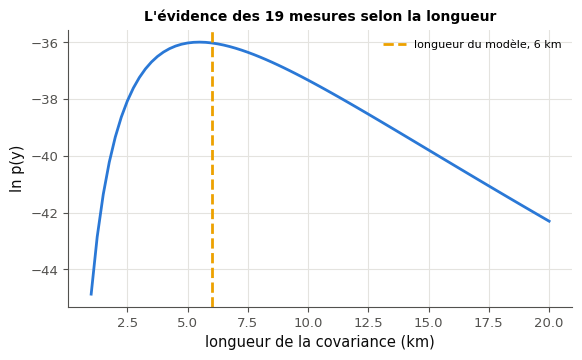

In [55]:
lengths_30 = np.linspace(1.0, 20.0, 77)
evidence_30 = []
for length_30 in lengths_30:
    mean_obs_30, cov_obs_30 = road_law_30(S_30[OBS_30], length_30)
    evidence_30.append(mvn_logpdf(Y_OBS_30, mean_obs_30, cov_obs_30 + 0.16 * np.eye(len(OBS_30))))
best_30 = int(np.argmax(evidence_30))
print(f"maximum vers {lengths_30[best_30]:.2f} km : ln p(y) ≈ {evidence_30[best_30]:.2f} ; à 4 km : "
      f"{np.interp(4, lengths_30, evidence_30):.2f}, à 8 km : {np.interp(8, lengths_30, evidence_30):.2f}".replace(".", ","))
fig_e30, ax_e30 = plt.subplots(figsize=(6.5, 3.6))
ax_e30.plot(lengths_30, evidence_30, color="C0")
ax_e30.axvline(6.0, color="C3", linestyle="--", label="longueur du modèle, 6 km")
ax_e30.set_xlabel("longueur de la covariance (km)")
ax_e30.set_ylabel("ln p(y)")
ax_e30.set_title("L'évidence des 19 mesures selon la longueur", fontsize=10)
ax_e30.legend(fontsize=8)
plt.show()

**Pour réfléchir** : pourquoi la loi conditionnelle revient-elle vers la tendance $m(s)$ aux deux bouts de la route, alors que l'interpolation linéaire prolonge la dernière mesure ? Que deviendraient tes moyennes si tu oubliais le bruit de mesure ?

💡 La covariance du vecteur (vraies températures aux positions en panne, mesures aux autres) est $\mathbf{K}$, plus $0{,}16$ sur la diagonale des seules positions mesurées ; `condition_gaussian` donne les moyennes, et la racine de la diagonale de la covariance conditionnelle les écarts-types. a) $0{,}83$ °C ; b) $1{,}25$ °C (et $2{,}14$ pour la seule moyenne $m(s)$) ; c) 12 sur 12. Le gain vient des bouts de la route ($1{,}01$ °C contre $1{,}59$ °C), où `np.interp` prolonge la dernière mesure à plat alors que la loi conditionnelle revient vers $m(s)$ ; dans le trou du milieu, les deux méthodes se valent ($0{,}48$ et $0{,}46$ °C). L'évidence est maximale vers 5,5 km ($\approx -35{,}99$ ; $-36{,}02$ à 6 km), sur une courbe plate entre 4 et 8 km.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu évaluer la densité et la log-densité d'une loi normale multivariée par Cholesky, et y lire le rôle de $\det\boldsymbol{\Sigma}$ et de la distance de Mahalanobis ?
2. Sais-tu trouver la loi d'une transformation affine, et tirer des vecteurs de loi $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$, en colonnes comme en lignes ?
3. Sais-tu tracer les ellipses de niveau, calculer leur masse en dimension 2, et dire ce qu'elle devient en dimension $d$ ?
4. Sais-tu calculer un complément de Schur et une loi conditionnelle, et expliquer pourquoi la covariance conditionnelle ne dépend pas de la valeur lue ?
5. Sais-tu fusionner des mesures, faire une régression bayésienne, calculer une KL entre deux gaussiennes, et écrire un test statistique dont tu connais le risque d'échec ?

**La suite** : M25b, qui introduit les variables cachées et réutilise ce chapitre (le conditionnement, la KL et l'entropie, le maximum de vraisemblance), puis le chapitre 25 de workbookIA, qui construit des modèles génératifs à partir de tirages gaussiens.